Smart Clinical Imaging Assistant: data and image-model pipeline

0. Setup & configuration

In [ ]:
import sys, subprocess, importlib.util
NEED = {"timm": "timm", "mlflow": "mlflow", "optuna": "optuna", "imagehash": "imagehash", "pytorch_grad_cam": "grad-cam", "shap": "shap", "kagglehub": "kagglehub", "tabulate": "tabulate"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", missing); subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
else: print("all extra packages already present")


installing: ['mlflow', 'optuna', 'imagehash', 'grad-cam']


In [ ]:
import os, sys, re, json, math, time, random, hashlib, warnings, platform, shutil, subprocess, copy, itertools
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 11})

SMOKE = os.environ.get("CXR_SMOKE", "0") == "1"
SEED  = 42

CFG = dict(
    data_version   = "v1.0",
    img_size       = 96 if SMOKE else 224,
    use_clahe      = True,
    resize_mode    = "squash",
    split_fracs    = dict(train=.70, val=.15, test=.15),
    n_split_folds  = 10 if SMOKE else 20,
    near_dup_hamming = 4,
    families       = ["resnet50", "densenet121", "vit_small"],
    pretrained     = not SMOKE,
    n_trials       = 2 if SMOKE else 8,
    tune_epochs    = 1 if SMOKE else 4,
    final_epochs   = 2 if SMOKE else 15,
    patience       = 2 if SMOKE else 4,
    baseline_epochs= 2 if SMOKE else 20,
    n_boot         = 100 if SMOKE else 1000,
    n_explain      = 8 if SMOKE else 120,
    tta_k          = 4 if SMOKE else 8,
    num_workers    = 0 if SMOKE else min(4, os.cpu_count() or 1),
)
FAMILIES_ALL = ["simplecnn"] + CFG["families"]

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s)
    import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

WORK = Path(os.environ.get("CXR_WORK", "/kaggle/working" if Path("/kaggle/working").exists() else "./cxr_work")).resolve()
WORK.mkdir(parents=True, exist_ok=True)
DS_DIR   = WORK / f"dataset_{CFG['data_version']}"
ART_DIR  = WORK / "artifacts";  FIG_DIR = WORK / "figures"
for d in (DS_DIR, ART_DIR, FIG_DIR, ART_DIR / "models", FIG_DIR / "evidence"): d.mkdir(parents=True, exist_ok=True)
print(f"SMOKE={SMOKE} | device={DEVICE} | work dir={WORK}")
print(f"torch {torch.__version__} | python {platform.python_version()} | cpus={os.cpu_count()}")
if SMOKE: print(" SMOKE profile: tiny settings, results are meaningless — code-path test only.")


SMOKE=False | device=cuda | work dir=/content/cxr_work
torch 2.11.0+cu130 | python 3.13.16 | cpus=12


1. Data provenance
Kaggle Chest X-Ray Images (Pneumonia), Kermany et al., Cell 2018. Paediatric AP radiographs from one hospital, CC BY 4.0. Images only, with the pneumonia subtype in the filename.

In [ ]:
def find_dataset_root():
    cands = [os.environ.get("CXR_DATA_ROOT"),
             "/kaggle/input/chest-xray-pneumonia/chest_xray",
             "/kaggle/input/chest-xray-pneumonia", "./chest_xray", "./data/chest_xray"]
    for c in cands:
        if c and Path(c).exists(): base = Path(c); break
    else:
        try:
            import kagglehub
            base = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
        except Exception as e:
            raise FileNotFoundError(
                "Dataset not found. Either (a) add the Kaggle dataset to this notebook, (b) set CXR_DATA_ROOT, or "
                "(c) on Colab: upload kaggle.json, or set os.environ[\"KAGGLE_USERNAME\"] / os.environ[\"KAGGLE_KEY\"], then re-run.\n" + repr(e))
    hits = [p for p in sorted(base.rglob("train")) if p.is_dir() and "__MACOSX" not in p.parts and (p.parent / "test").is_dir()]
    if not hits: raise FileNotFoundError(f"No train/ + test/ folders under {base}")
    return min(hits, key=lambda p: len(p.parts)).parent

DATA_ROOT = find_dataset_root()
print("Data root:", DATA_ROOT)
IMG_EXT = {".jpeg", ".jpg", ".png"}
files = sorted(p for p in DATA_ROOT.rglob("*")
               if p.suffix.lower() in IMG_EXT and "__MACOSX" not in p.parts and not p.name.startswith("._")
               and p.relative_to(DATA_ROOT).parts[0].lower() in ("train", "val", "test"))
assert len(files) > 0, "no images under train/ val/ test/"
print(f"{len(files):,} image files found")
if len(files) != 5856: print(f"WARNING: expected 5,856 images for the Kaggle chest-xray-pneumonia dataset, found {len(files):,} - check for a duplicated/nested copy of the data")
assert len({(p.parent.parent.name.lower(), p.parent.name, p.name) for p in files}) == len(files), "duplicate train/val/test paths"
PROVENANCE = dict(source="kaggle:paultimothymooney/chest-xray-pneumonia", publication="Kermany et al., Cell 2018",
                  n_files=len(files), total_bytes=int(sum(p.stat().st_size for p in files)),
                  retrieved=time.strftime("%Y-%m-%d"), root=str(DATA_ROOT))
print(PROVENANCE)


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Data root: /kaggle/input/chest-xray-pneumonia/chest_xray
5,856 image files found
{'source': 'kaggle:paultimothymooney/chest-xray-pneumonia', 'publication': 'Kermany et al., Cell 2018', 'n_files': 5856, 'total_bytes': 1236482806, 'retrieved': '2026-10-27', 'root': '/kaggle/input/chest-xray-pneumonia/chest_xray'}


2. Data dictionary

In [ ]:
DATA_DICTIONARY = pd.DataFrame([
 ("image_id","str","derived","Stable ID = relative path with '/' -> '__' (unique, reproducible)"),
 ("path","str","file","Absolute path on this machine (not portable — use image_id + DATA_ROOT)"),
 ("orig_split","cat","folder","Kaggle's own split: train / val / test"),
 ("label_name","cat","folder","NORMAL / PNEUMONIA (ground truth, expert-labelled)"),
 ("y","int8","derived","1 = PNEUMONIA, 0 = NORMAL (modelling target)"),
 ("subtype","cat","filename","normal / bacteria / virus (pneumonia subtype parsed from filename; secondary analysis only)"),
 ("patient_id","str","filename","Parsed patient key: personNNN (pneumonia) or IM-NNNN (normal). Falls back to file stem (flagged)"),
 ("patient_id_parsed","bool","derived","False if the filename matched no known pattern"),
 ("width, height","int","image","Original pixel dimensions"),
 ("aspect","float","derived","width / height"),
 ("mode","cat","image","PIL colour mode of the file (L = greyscale, RGB = 3-channel copy)"),
 ("file_bytes","int","file","Size on disk"),
 ("md5","str","derived","Hash of file bytes -> exact duplicates"),
 ("phash","uint64","derived","64-bit perceptual hash -> near-duplicates (Hamming ≤ near_dup_hamming)"),
 ("mean_int, std_int, p1, p99","float","image","Intensity statistics of the 8-bit greyscale image (before CLAHE)"),
 ("dup_group","int","derived","Connected-component ID of exact/near-duplicate links"),
 ("group_id","int","derived","Leakage-safe group = connected component of (patient_id ∪ duplicate links). Splits never cut a group"),
 ("split","cat","derived","Final leakage-safe split: train / val / test"),
 ("row","int","derived","Row index into the cached uint8 image array"),
], columns=["column","dtype","source","description"])
DATA_DICTIONARY.to_csv(DS_DIR / "data_dictionary.csv", index=False)
DATA_DICTIONARY


,column,dtype,source,description
0,image_id,str,derived,Stable ID = relative path with '/' -> '__' (un...
1,path,str,file,Absolute path on this machine (not portable — ...
2,orig_split,cat,folder,Kaggle's own split: train / val / test
3,label_name,cat,folder,"NORMAL / PNEUMONIA (ground truth, expert-label..."
4,y,int8,derived,"1 = PNEUMONIA, 0 = NORMAL (modelling target)"
5,subtype,cat,filename,normal / bacteria / virus (pneumonia subtype p...
6,patient_id,str,filename,Parsed patient key: personNNN (pneumonia) or I...
7,patient_id_parsed,bool,derived,False if the filename matched no known pattern
8,"width, height",int,image,Original pixel dimensions
9,aspect,float,derived,width / height


3. Master index

In [ ]:
import cv2, imagehash
from joblib import Parallel, delayed

def parse_meta(p: Path):
    n = p.name
    m = re.search(r"(person\d+)_(bacteria|virus)", n, re.I)
    if m: return m.group(1).lower(), m.group(2).lower(), True
    m = re.search(r"(IM-\d+)", n, re.I)
    if m: return m.group(1).upper(), "normal", True
    return p.stem, ("normal" if "NORMAL" in p.parent.name.upper() else "unknown"), False

def preprocess_gray(a: np.ndarray, size: int, clahe: bool, mode: str) -> np.ndarray:
    if clahe: a = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(a)
    if mode == "squash":
        return cv2.resize(a, (size, size), interpolation=cv2.INTER_AREA)
    h, w = a.shape; s = size / max(h, w); nh, nw = max(1, round(h * s)), max(1, round(w * s))
    a = cv2.resize(a, (nw, nh), interpolation=cv2.INTER_AREA)
    c = np.zeros((size, size), np.uint8); y0, x0 = (size - nh) // 2, (size - nw) // 2; c[y0:y0+nh, x0:x0+nw] = a; return c

def process_one(p: str, size: int, clahe: bool, mode: str):
    p = Path(p); raw = p.read_bytes()
    im = Image.open(p); orig_mode = im.mode; w, h = im.size
    g = np.asarray(im.convert("L")); small = cv2.resize(g, (128, 128), interpolation=cv2.INTER_AREA)
    ph = int(str(imagehash.phash(Image.fromarray(small), hash_size=8)), 16)
    pid, sub, ok = parse_meta(p)
    rec = dict(path=str(p), width=w, height=h, mode=orig_mode, file_bytes=len(raw), md5=hashlib.md5(raw).hexdigest(),
               phash=ph, mean_int=float(g.mean()), std_int=float(g.std()), p1=float(np.percentile(g, 1)), p99=float(np.percentile(g, 99)),
               patient_id=pid, subtype=sub, patient_id_parsed=ok)
    return rec, preprocess_gray(g, size, clahe, mode)

t0 = time.time()
out = Parallel(n_jobs=-1, batch_size=16)(delayed(process_one)(str(p), CFG["img_size"], CFG["use_clahe"], CFG["resize_mode"]) for p in files)
manifest = pd.DataFrame([o[0] for o in out]); IMGS = np.stack([o[1] for o in out]); del out
rel = manifest["path"].map(lambda s: str(Path(s).relative_to(DATA_ROOT)))
manifest.insert(0, "image_id", rel.str.replace(os.sep, "__", regex=False).str.replace("/", "__", regex=False))
manifest["orig_split"] = rel.map(lambda s: Path(s).parts[0].lower())
manifest["label_name"] = manifest["path"].map(lambda s: "PNEUMONIA" if "PNEUMONIA" in Path(s).parent.name.upper() else "NORMAL")
manifest["y"] = (manifest["label_name"] == "PNEUMONIA").astype("int8")
manifest["aspect"] = manifest.width / manifest.height
manifest["row"] = np.arange(len(manifest))
assert manifest.image_id.is_unique and len(manifest) == len(IMGS)
print(f"indexed {len(manifest):,} images in {time.time()-t0:.0f}s | cached array {IMGS.shape} {IMGS.dtype} = {IMGS.nbytes/1e6:.0f} MB")
manifest.head()


indexed 5,856 images in 44s | cached array (5856, 224, 224) uint8 = 294 MB


,image_id,path,width,height,mode,file_bytes,md5,phash,mean_int,std_int,p1,p99,patient_id,subtype,patient_id_parsed,orig_split,label_name,y,aspect,row
0,test__NORMAL__IM-0001-0001.jpeg,/kaggle/input/chest-xray-pneumonia/chest_xray/...,1857,1317,L,252680,6535e4c9b865af758eb077d28864c334,11055851214040876908,130.998608,57.102032,18.0,232.0,IM-0001,normal,True,test,NORMAL,0,1.410023,0
1,test__NORMAL__IM-0003-0001.jpeg,/kaggle/input/chest-xray-pneumonia/chest_xray/...,2111,1509,L,329189,b0936ea9277e1dec13fa09f3dbe1499c,9341809482013580907,142.445303,60.668227,23.0,237.0,IM-0003,normal,True,test,NORMAL,0,1.398940,1
2,test__NORMAL__IM-0005-0001.jpeg,/kaggle/input/chest-xray-pneumonia/chest_xray/...,2031,1837,L,408620,1bdca139c77d5997f873e9e078d8f047,11055781089990286159,136.249559,55.404084,19.0,229.0,IM-0005,normal,True,test,NORMAL,0,1.105607,2
3,test__NORMAL__IM-0006-0001.jpeg,/kaggle/input/chest-xray-pneumonia/chest_xray/...,1663,1326,L,252275,5f4216bba00f1db48677e70c74332b09,10983581433383041611,148.670080,42.324957,60.0,222.0,IM-0006,normal,True,test,NORMAL,0,1.254148,3
4,test__NORMAL__IM-0007-0001.jpeg,/kaggle/input/chest-xray-pneumonia/chest_xray/...,2053,1818,L,408508,2f0982422666632a3411cccadbbad64d,15959141189279226445,137.699779,53.966271,23.0,236.0,IM-0007,normal,True,test,NORMAL,0,1.129263,4


4. Data-quality audit

In [ ]:
audit = {}
na = manifest.isna().sum(); audit["missing_cells"] = int(na.sum())
audit["unparsed_patient_ids"] = int((~manifest.patient_id_parsed).sum())
audit["unknown_subtype"] = int((manifest.subtype == "unknown").sum())
audit["non_greyscale_files"] = int((manifest["mode"] != "L").sum())
audit["tiny_images(<128px side)"] = int(((manifest.width < 128) | (manifest.height < 128)).sum())

dup_md5 = manifest[manifest.duplicated("md5", keep=False)].sort_values("md5")
audit["exact_duplicate_files"] = int(manifest.duplicated("md5", keep="first").sum())
ph = manifest.phash.values.astype(np.uint64); n = len(ph)
POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)
near_pairs = []
for s in range(0, n, 256):
    x = (ph[s:s+256, None] ^ ph[None, :]).view(np.uint8).reshape(min(256, n - s), n, 8)
    d = POP[x].sum(-1)
    ii, jj = np.where(d <= CFG["near_dup_hamming"])
    near_pairs += [(s + a, b) for a, b in zip(ii, jj) if s + a < b]
near_pairs = np.array(near_pairs).reshape(-1, 2)
audit["near_duplicate_pairs(phash)"] = int(len(near_pairs))

parent = list(range(n))
def find(a):
    while parent[a] != a: parent[a] = parent[parent[a]]; a = parent[a]
    return a
def union(a, b): ra, rb = find(a), find(b); parent[max(ra, rb)] = min(ra, rb)
for g in manifest.groupby("md5").row.apply(list):
    for r in g[1:]: union(g[0], r)
for a, b in near_pairs: union(int(a), int(b))
manifest["dup_group"] = [find(i) for i in range(n)]
dup_sizes = manifest.groupby("dup_group").size()
for g in manifest.groupby("patient_id").row.apply(list):
    for r in g[1:]: union(g[0], r)
manifest["group_id"] = pd.factorize([find(i) for i in range(n)])[0]

conf = manifest[manifest.dup_group.isin(dup_sizes[dup_sizes > 1].index)].groupby("dup_group").y.nunique()
audit["duplicate_clusters_with_conflicting_labels"] = int((conf > 1).sum())
xs = manifest[manifest.dup_group.isin(dup_sizes[dup_sizes > 1].index)].groupby("dup_group").orig_split.nunique()
audit["dup_clusters_spanning_orig_splits"] = int((xs > 1).sum())
pat_xs = manifest.groupby("patient_id").orig_split.nunique()
audit["patients_spanning_orig_splits"] = int((pat_xs > 1).sum())
audit["n_patients"] = int(manifest.patient_id.nunique()); audit["n_groups_after_merge"] = int(manifest.group_id.nunique())
imgs_per_pat = manifest.groupby("patient_id").size()

def iqr_flag(s, k=3.0):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return (s < q1 - k * i) | (s > q3 + k * i)
for c in ["width", "height", "mean_int", "std_int", "file_bytes"]: manifest[f"out_{c}"] = iqr_flag(manifest[c])
manifest["near_blank"] = manifest.std_int < 10
manifest["is_outlier"] = manifest[[c for c in manifest if c.startswith("out_")]].any(axis=1) | manifest.near_blank
audit["outliers(IQR×3 on size/intensity)"] = int(manifest.is_outlier.sum()); audit["near_blank_images"] = int(manifest.near_blank.sum())

audit["class_balance_PNEUMONIA_fraction"] = round(float(manifest.y.mean()), 4)
audit["imbalance_ratio(majority/minority)"] = round(float(max(manifest.y.mean(), 1 - manifest.y.mean()) / min(manifest.y.mean(), 1 - manifest.y.mean())), 2)
AUDIT = pd.Series(audit, name="value").to_frame()


4.5 Audit of the audit
Are the near-duplicate links safe, and are the filename-parsed patient IDs consistent?

{'n_pairs': 261, 'identical_bytes': 34, 'not_identical_same_patient': 0, 'not_identical_cross_patient': 227, 'with_label_conflict': 35, 'groups_that_merge_several_patients': 64, 'images_in_multi_patient_groups': 581, 'largest_group_sizes': [187, 31, 24, 20, 18]}
Hamming distance of near-duplicate pairs: {0: 34, 2: 18, 4: 209}
Cross-patient, non-identical links merge two different patients into one split-group. That is SAFE for leakage (they are kept together) but shrinks the effective sample; inspect them below. If they look like genuinely different people, lower CFG['near_dup_hamming'].


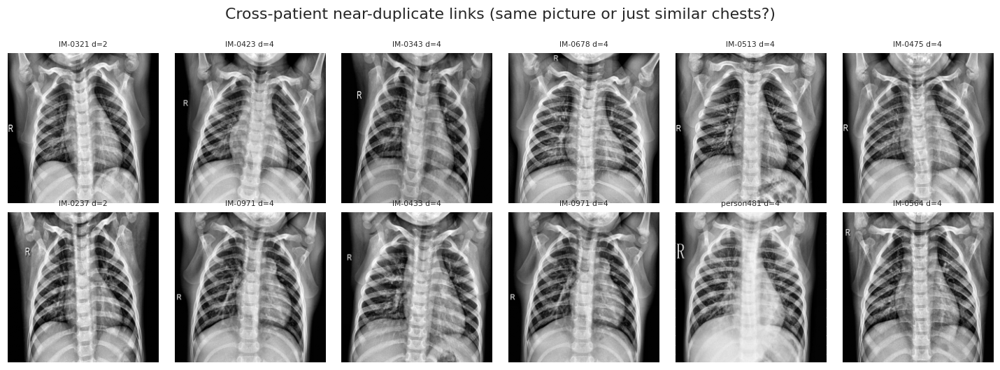

{'patients_with_mixed_labels': 0, 'patient_ids_not_matching_known_pattern': 0, 'patient_id_vs_folder_inconsistent': 0, 'near_dup_cross_patient_links': 227}


In [ ]:
ph_ = manifest.phash.values.astype(np.uint64)
nd = pd.DataFrame(near_pairs, columns=["i", "j"])
if len(nd):
    nd["hamming"] = [bin(int(ph_[a]) ^ int(ph_[b])).count("1") for a, b in zip(nd.i.values, nd.j.values)]
    nd["same_md5"] = manifest.md5.values[nd.i.values] == manifest.md5.values[nd.j.values]
    nd["same_patient"] = manifest.patient_id.values[nd.i.values] == manifest.patient_id.values[nd.j.values]
    nd["label_conflict"] = manifest.y.values[nd.i.values] != manifest.y.values[nd.j.values]
gp = manifest.groupby("group_id").agg(n_images=("row", "size"), n_patients=("patient_id", "nunique"))
NEAR_AUDIT = dict(
    n_pairs=int(len(nd)),
    identical_bytes=int(nd.same_md5.sum()) if len(nd) else 0,
    not_identical_same_patient=int((~nd.same_md5 & nd.same_patient).sum()) if len(nd) else 0,
    not_identical_cross_patient=int((~nd.same_md5 & ~nd.same_patient).sum()) if len(nd) else 0,
    with_label_conflict=int(nd.label_conflict.sum()) if len(nd) else 0,
    groups_that_merge_several_patients=int((gp.n_patients > 1).sum()),
    images_in_multi_patient_groups=int(gp.n_images[gp.n_patients > 1].sum()),
    largest_group_sizes=gp.n_images.sort_values(ascending=False).head(5).tolist())
print(NEAR_AUDIT)
if len(nd): print("Hamming distance of near-duplicate pairs:", nd.hamming.value_counts().sort_index().to_dict())
print("Cross-patient, non-identical links merge two different patients into one split-group. That is SAFE for leakage"
      " (they are kept together) but shrinks the effective sample; inspect them below. If they look like genuinely different people,"
      " lower CFG['near_dup_hamming'].")
cp = nd[(~nd.same_md5) & (~nd.same_patient)] if len(nd) else nd
if len(cp):
    pk = cp.sample(min(6, len(cp)), random_state=SEED)
    fig, axs = plt.subplots(2, len(pk), figsize=(2.2 * len(pk), 4.8), squeeze=False)
    for c_, (_, r_) in enumerate(pk.iterrows()):
        for rr_, ix_ in enumerate((int(r_.i), int(r_.j))):
            axs[rr_, c_].imshow(IMGS[ix_], cmap="gray"); axs[rr_, c_].axis("off"); axs[rr_, c_].set_title(f"{manifest.patient_id.iat[ix_]} d={int(r_.hamming)}", fontsize=7)
    plt.suptitle("Cross-patient near-duplicate links (same picture or just similar chests?)", y=1.0); plt.tight_layout(); plt.savefig(FIG_DIR / "near_duplicate_crosspatient_check.png"); plt.show()

mixed = manifest.groupby("patient_id").y.nunique()
bad_fmt = ~manifest.patient_id.str.fullmatch(r"(person\d+|IM-\d+)", case=False)
inconsistent = (manifest.patient_id.str.lower().str.startswith("person") & (manifest.y == 0)) | (manifest.patient_id.str.upper().str.startswith("IM-") & (manifest.y == 1))
audit["patients_with_mixed_labels"] = int((mixed > 1).sum())
audit["patient_ids_not_matching_known_pattern"] = int(bad_fmt.sum())
audit["patient_id_vs_folder_inconsistent"] = int(inconsistent.sum())
audit["near_dup_cross_patient_links"] = NEAR_AUDIT["not_identical_cross_patient"]
print({k: audit[k] for k in ("patients_with_mixed_labels", "patient_ids_not_matching_known_pattern", "patient_id_vs_folder_inconsistent", "near_dup_cross_patient_links")})
if audit["patients_with_mixed_labels"] or audit["patient_id_vs_folder_inconsistent"]:
    print("WARNING: filename-parsed patient IDs are inconsistent with the folder labels - the patient-level split may be unreliable.")


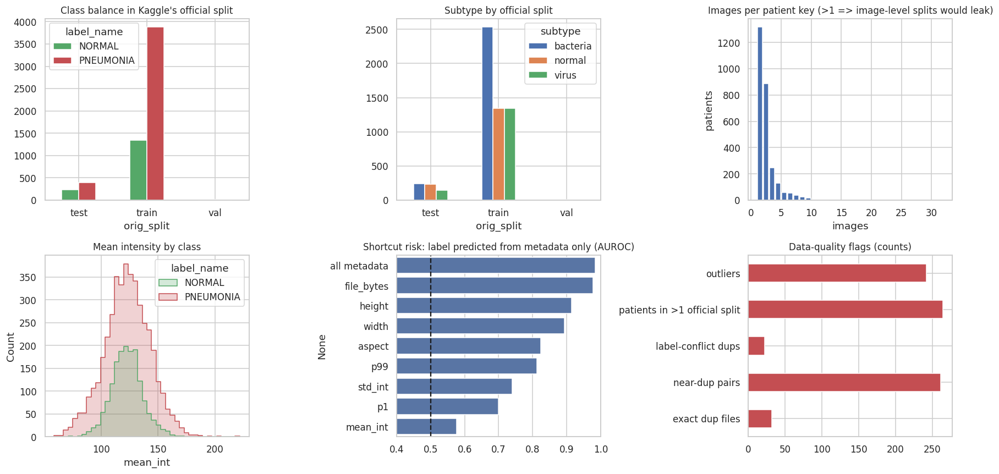

5,856 images · 2,790 patient keys · 73% pneumonia | metadata-only AUROC 0.98 | official train-vs-test shift AUROC 0.77


In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
meta_cols = ["width", "height", "aspect", "file_bytes", "mean_int", "std_int", "p1", "p99"]
def grouped_auc(X, y, groups, k=5):
    oof = np.zeros(len(y))
    for tr, te in GroupKFold(k).split(X, y, groups):
        m = HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, random_state=SEED).fit(X.iloc[tr], y[tr])
        oof[te] = m.predict_proba(X.iloc[te])[:, 1]
    return roc_auc_score(y, oof)
y_all = manifest.y.values
SHORTCUT = {"all metadata": grouped_auc(manifest[meta_cols], y_all, manifest.group_id.values)}
for c in meta_cols: SHORTCUT[c] = grouped_auc(manifest[[c]], y_all, manifest.group_id.values)
SHORTCUT = pd.Series(SHORTCUT, name="grouped-CV AUROC (label from metadata only)").sort_values(ascending=False).round(3).to_frame()
ts = manifest[manifest.orig_split.isin(["train", "test"])]
SPLIT_SHIFT_AUC = grouped_auc(ts[meta_cols], (ts.orig_split == "test").astype(int).values, ts.group_id.values)
audit["metadata_only_AUROC"] = float(SHORTCUT.iloc[0, 0]); audit["official_split_shift_AUROC"] = float(SPLIT_SHIFT_AUC)
pal2 = ["#55a868", "#c44e52"]
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
manifest.groupby(["orig_split", "label_name"]).size().unstack().plot.bar(ax=ax[0, 0], rot=0, color=pal2); ax[0, 0].set_title("Class balance in Kaggle's official split")
manifest.groupby(["orig_split", "subtype"]).size().unstack().plot.bar(ax=ax[0, 1], rot=0); ax[0, 1].set_title("Subtype by official split")
ax[0, 2].hist(imgs_per_pat.values, bins=range(1, int(imgs_per_pat.max()) + 2), color="#4c72b0", rwidth=.85); ax[0, 2].set(title="Images per patient key (>1 => image-level splits would leak)", xlabel="images", ylabel="patients")
sns.histplot(data=manifest, x="mean_int", hue="label_name", bins=40, element="step", ax=ax[1, 0], palette=pal2); ax[1, 0].set_title("Mean intensity by class")
sns.barplot(x=SHORTCUT.iloc[:, 0].values, y=SHORTCUT.index, ax=ax[1, 1], color="#4c72b0"); ax[1, 1].axvline(.5, c="k", ls="--"); ax[1, 1].set(xlim=(.4, 1), title="Shortcut risk: label predicted from metadata only (AUROC)")
cnt = pd.Series({"exact dup files": audit["exact_duplicate_files"], "near-dup pairs": audit["near_duplicate_pairs(phash)"], "label-conflict dups": audit["duplicate_clusters_with_conflicting_labels"],
                 "patients in >1 official split": audit["patients_spanning_orig_splits"], "outliers": audit["outliers(IQR×3 on size/intensity)"]}); cnt.plot.barh(ax=ax[1, 2], color="#c44e52"); ax[1, 2].set_title("Data-quality flags (counts)")
plt.tight_layout(); plt.savefig(FIG_DIR / "audit_overview.png"); plt.show()
issues = {k: v for k, v in audit.items() if k in cnt.index or k.startswith(("exact", "near", "dup", "patients_span"))}
print(f"{len(manifest):,} images · {audit['n_patients']:,} patient keys · {audit['class_balance_PNEUMONIA_fraction']:.0%} pneumonia | metadata-only AUROC {audit['metadata_only_AUROC']:.2f} | official train-vs-test shift AUROC {SPLIT_SHIFT_AUC:.2f}")


5. Exploratory data analysis

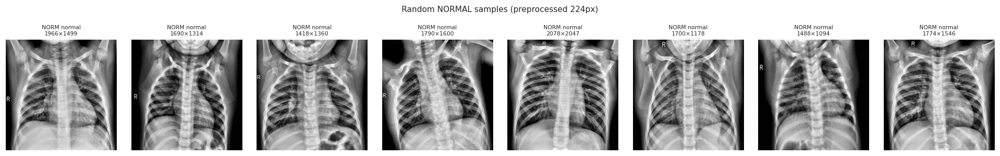

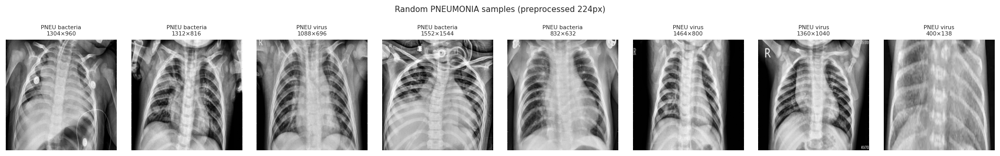

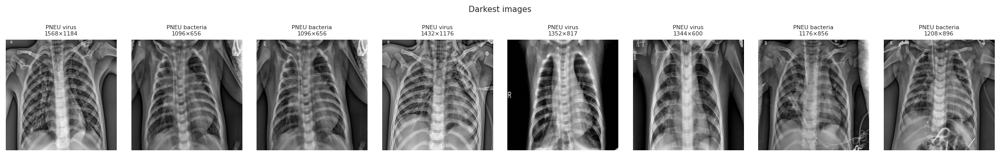

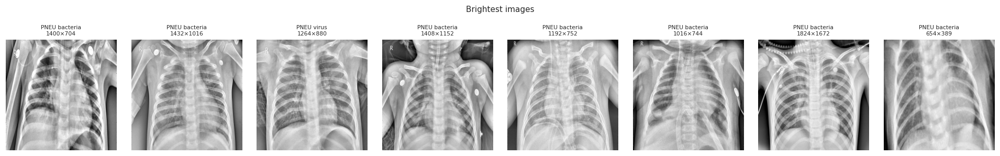

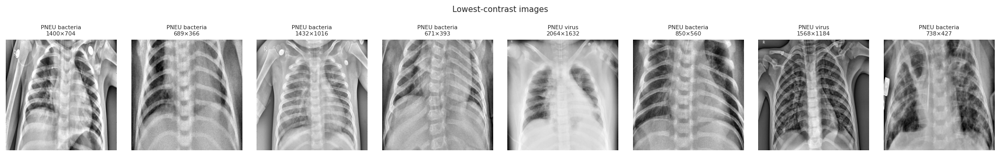

In [ ]:
def show_grid(rows, title, n=8, fname=None):
    rows = rows.head(n); fig, axs = plt.subplots(1, max(len(rows), 2), figsize=(2.2 * max(len(rows), 2), 2.6))
    for ax, (_, r) in zip(np.atleast_1d(axs), rows.iterrows()):
        ax.imshow(IMGS[r.row], cmap="gray"); ax.set_title(f"{r.label_name[:4]} {r.subtype}\n{r.width}×{r.height}", fontsize=7); ax.axis("off")
    for ax in np.atleast_1d(axs)[len(rows):]: ax.axis("off")
    fig.suptitle(title, y=1.04, fontsize=10); plt.tight_layout()
    if fname: plt.savefig(FIG_DIR / fname, bbox_inches="tight")
    plt.show()
rs = np.random.RandomState(SEED)
for lab in ["NORMAL", "PNEUMONIA"]:
    show_grid(manifest[manifest.label_name == lab].sample(8, random_state=SEED, replace=len(manifest[manifest.label_name == lab]) < 8), f"Random {lab} samples (preprocessed {CFG['img_size']}px)", fname=f"samples_{lab}.png")
show_grid(manifest.sort_values("mean_int").assign(), "Darkest images", fname="outliers_dark.png")
show_grid(manifest.sort_values("mean_int", ascending=False), "Brightest images", fname="outliers_bright.png")
show_grid(manifest.sort_values("std_int"), "Lowest-contrast images", fname="outliers_lowcontrast.png")


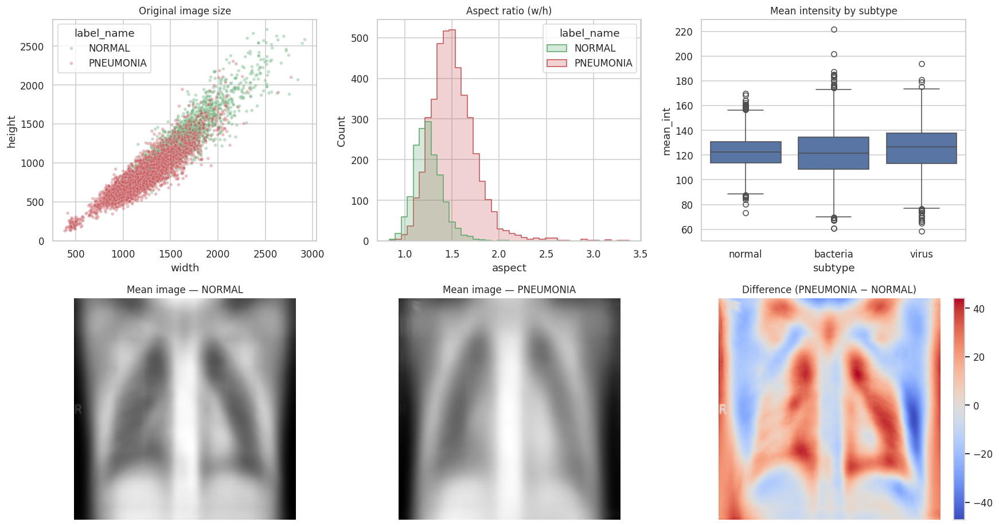

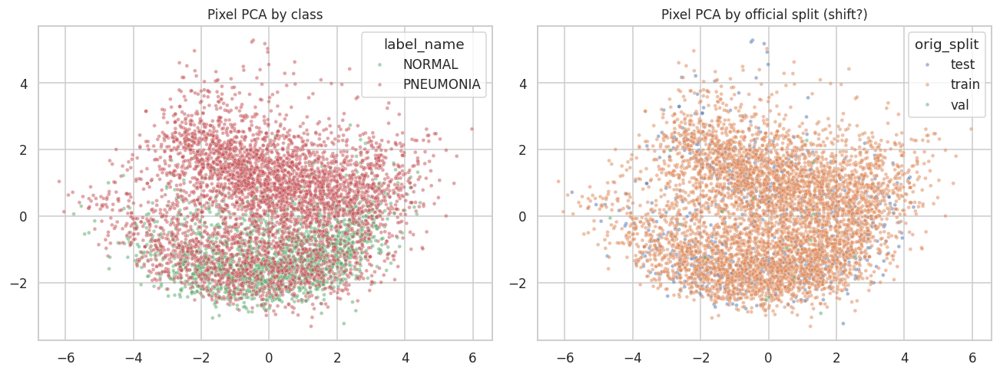

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
sns.scatterplot(data=manifest, x="width", y="height", hue="label_name", alpha=.35, s=14, ax=ax[0, 0], palette=["#55a868", "#c44e52"]); ax[0, 0].set_title("Original image size")
sns.histplot(data=manifest, x="aspect", hue="label_name", bins=40, element="step", ax=ax[0, 1], palette=["#55a868", "#c44e52"]); ax[0, 1].set_title("Aspect ratio (w/h)")
sns.boxplot(data=manifest, x="subtype", y="mean_int", ax=ax[0, 2]); ax[0, 2].set_title("Mean intensity by subtype")
mean_img = {c: IMGS[manifest.y.values == c].mean(0) for c in (0, 1)}
ax[1, 0].imshow(mean_img[0], cmap="gray"); ax[1, 0].set_title("Mean image — NORMAL"); ax[1, 0].axis("off")
ax[1, 1].imshow(mean_img[1], cmap="gray"); ax[1, 1].set_title("Mean image — PNEUMONIA"); ax[1, 1].axis("off")
im = ax[1, 2].imshow(mean_img[1] - mean_img[0], cmap="coolwarm"); ax[1, 2].set_title("Difference (PNEUMONIA − NORMAL)"); ax[1, 2].axis("off"); plt.colorbar(im, ax=ax[1, 2], fraction=.046)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_overview.png"); plt.show()

from sklearn.decomposition import PCA
small = np.stack([cv2.resize(a, (32, 32), interpolation=cv2.INTER_AREA).ravel() for a in IMGS]).astype(np.float32) / 255
Z = PCA(2, random_state=SEED).fit_transform(small - small.mean(0))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=manifest.label_name, s=10, alpha=.5, ax=ax[0], palette=["#55a868", "#c44e52"]); ax[0].set_title("Pixel PCA by class")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=manifest.orig_split, s=10, alpha=.5, ax=ax[1]); ax[1].set_title("Pixel PCA by official split (shift?)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_pca.png"); plt.show()


In [ ]:
def insights():
    L = []; a = audit; vc = manifest.label_name.value_counts()
    L.append(f"**Balance.** {vc.get('PNEUMONIA',0):,} pneumonia vs {vc.get('NORMAL',0):,} normal ({a['class_balance_PNEUMONIA_fraction']:.0%} positive) -> report AUROC/AUPRC and sensitivity/specificity, not accuracy; use a weighted loss.")
    L.append(f"**Patients.** {a['n_patients']:,} patient keys, up to {imgs_per_pat.max()} images each -> splits must be by patient/duplicate group ({a['n_groups_after_merge']:,} groups).")
    bad = a['patients_spanning_orig_splits'] + a['dup_clusters_spanning_orig_splits']
    L.append(f"**Official split.** " + (f"{a['patients_spanning_orig_splits']} patient key(s) and {a['dup_clusters_spanning_orig_splits']} duplicate cluster(s) straddle train/val/test -> not leakage-free; we re-split." if bad else "no patient/duplicate straddling detected; we still re-split to get a usable validation set."))
    if a['exact_duplicate_files'] or a['near_duplicate_pairs(phash)']: L.append(f"**Duplicates.** {a['exact_duplicate_files']} exact, {a['near_duplicate_pairs(phash)']} near-duplicate pairs ({a['duplicate_clusters_with_conflicting_labels']} with conflicting labels).")
    sh = a["metadata_only_AUROC"]
    L.append(f"**Shortcut risk.** Size/brightness alone predict the label at AUROC {sh:.2f}" + (" — substantial; Section 13.5 tests whether the models exploit it." if sh > .65 else " — modest."))
    if a['official_split_shift_AUROC'] > .65: L.append(f"**Shift.** Official train and test are distinguishable from metadata alone (AUROC {a['official_split_shift_AUROC']:.2f}) -> official test is not drawn from the same distribution as train.")
    return L
from IPython.display import Markdown, display
display(Markdown("### What the audit and EDA say\n" + "\n".join(f"- {t}" for t in insights())))


### What the audit and EDA say
- **Balance.** 4,273 pneumonia vs 1,583 normal (73% positive) -> report AUROC/AUPRC and sensitivity/specificity, not accuracy; use a weighted loss.
- **Patients.** 2,790 patient keys, up to 31 images each -> splits must be by patient/duplicate group (2,596 groups).
- **Official split.** 264 patient key(s) and 11 duplicate cluster(s) straddle train/val/test -> not leakage-free; we re-split.
- **Duplicates.** 32 exact, 261 near-duplicate pairs (22 with conflicting labels).
- **Shortcut risk.** Size/brightness alone predict the label at AUROC 0.98 — substantial; Section 13.5 tests whether the models exploit it.
- **Shift.** Official train and test are distinguishable from metadata alone (AUROC 0.77) -> official test is not drawn from the same distribution as train.

6. Patient-level split and leakage checks
All images are pooled and split by patient and duplicate group, stratified by subtype. Assertions check that nothing is shared across splits.

split seed = 42 (attempt 1)
 no shared patients / identical files / near-duplicates across train, val, test


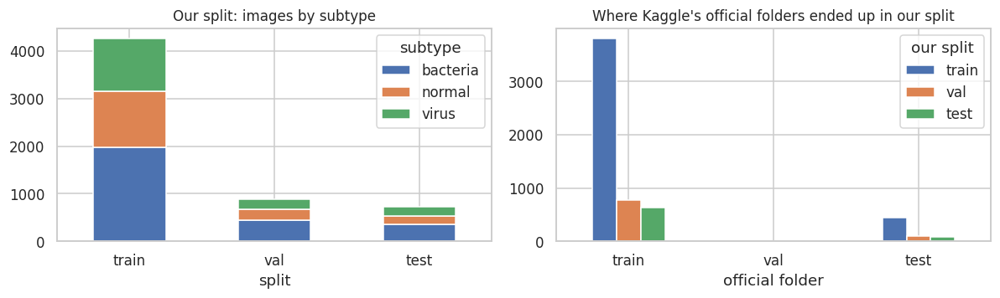

split sizes: {'train': 4259, 'val': 878, 'test': 719} | pneumonia fraction: {'train': 0.724, 'val': 0.747, 'test': 0.744}


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
def make_split(df, seed):
    nf = CFG["n_split_folds"]; ntest = max(1, round(nf * CFG["split_fracs"]["test"])); nval = max(1, round(nf * CFG["split_fracs"]["val"]))
    strat = df.subtype.where(df.subtype != "unknown", "normal").values
    fold = np.full(len(df), -1)
    for k, (_, te) in enumerate(StratifiedGroupKFold(nf, shuffle=True, random_state=seed).split(df, strat, df.group_id.values)): fold[te] = k
    order = np.random.RandomState(seed).permutation(nf)
    role = {int(f): ("test" if i < ntest else "val" if i < ntest + nval else "train") for i, f in enumerate(order)}
    return pd.Series([role[int(f)] for f in fold], index=df.index), strat

for attempt in range(100):
    split, strat = make_split(manifest, SEED + attempt)
    ok = all(set(strat[split.values == s]) >= set(strat) for s in ("train", "val", "test"))
    if ok: break
assert ok, "could not find a split containing every stratum in every partition"
manifest["split"] = split.values; SPLIT_SEED = SEED + attempt
print(f"split seed = {SPLIT_SEED} (attempt {attempt+1})")

def overlap(col):
    s = {k: set(manifest.loc[manifest.split == k, col]) for k in ("train", "val", "test")}
    return {f"{a}∩{b}": len(s[a] & s[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
LEAK = {"patient_id": overlap("patient_id"), "md5": overlap("md5"), "group_id": overlap("group_id"), "dup_group": overlap("dup_group")}
LEAK = pd.DataFrame(LEAK).T
assert (LEAK.values == 0).all(), "LEAKAGE DETECTED"
cross = [(i, j) for i, j in near_pairs if manifest.split.iat[i] != manifest.split.iat[j]]
assert len(cross) == 0, f"{len(cross)} near-duplicate pairs cross splits"
print(" no shared patients / identical files / near-duplicates across train, val, test")

SPLIT_SUMMARY = (manifest.groupby("split").agg(images=("y", "size"), patients=("patient_id", "nunique"), pneumonia_frac=("y", "mean"),
                 bacteria=("subtype", lambda s: (s == "bacteria").sum()), virus=("subtype", lambda s: (s == "virus").sum()))
                 .loc[["train", "val", "test"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
manifest.groupby(["split", "subtype"]).size().unstack().loc[["train", "val", "test"]].plot.bar(stacked=True, ax=ax[0], rot=0); ax[0].set_title("Our split: images by subtype")
pd.crosstab(manifest.orig_split, manifest.split).loc[["train", "val", "test"], ["train", "val", "test"]].plot.bar(ax=ax[1], rot=0); ax[1].set(title="Where Kaggle's official folders ended up in our split", xlabel="official folder"); ax[1].legend(title="our split")
plt.tight_layout(); plt.savefig(FIG_DIR / "split_overview.png"); plt.show()
print("split sizes:", SPLIT_SUMMARY.images.to_dict(), "| pneumonia fraction:", SPLIT_SUMMARY.pneumonia_frac.to_dict())


7. Preprocessing and versioned dataset

In [ ]:
def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

def seq_key(image_id):
    m = re.findall(r"(\d+)", image_id.split("__")[-1]); return int(m[-1]) if m else 0
PATIENT_TABLE = (manifest.assign(seq=manifest.image_id.map(seq_key)).sort_values(["patient_id", "seq", "image_id"]).groupby("patient_id")
                 .agg(n_studies=("image_id", "size"), split=("split", lambda s: ",".join(sorted(set(s)))), subtypes=("subtype", lambda s: ",".join(sorted(set(s)))), labels_in_order=("y", lambda s: json.dumps([int(v) for v in s])),
                      image_ids_in_order=("image_id", lambda s: json.dumps(list(s)))).reset_index())
PATIENT_TABLE["order_is_chronological"] = False
assert not PATIENT_TABLE.split.str.contains(",").any(), "a patient appears in more than one split"
PATIENT_TABLE.to_csv(DS_DIR / "patient_table.csv", index=False)
print(f"patient-linked table: {len(PATIENT_TABLE):,} patients, {int((PATIENT_TABLE.n_studies > 1).sum())} with >1 study (max {PATIENT_TABLE.n_studies.max()}) - ordered by filename sequence, NOT time")
manifest_out = manifest.drop(columns=["path"]).assign(phash=manifest.phash.astype(str))
manifest_out.to_csv(DS_DIR / "manifest.csv", index=False)
manifest[["image_id", "patient_id", "group_id", "y", "subtype", "split", "row"]].to_csv(DS_DIR / "splits.csv", index=False)
np.save(DS_DIR / f"images_uint8_{CFG['img_size']}.npy", IMGS)
pd.Series(audit, name="value").to_frame().to_csv(DS_DIR / "audit.csv")
PREPROC = dict(grayscale=True, clahe=dict(on=CFG["use_clahe"], clipLimit=2.0, tile=(8, 8)), resize=CFG["resize_mode"], size=CFG["img_size"],
               interpolation="INTER_AREA", dtype="uint8", normalisation="ImageNet mean/std applied at load time, grayscale replicated to 3 channels",
               train_augmentation="RandomAffine(rot<=10°, shift<=6%, scale 0.9–1.1) + brightness/contrast jitter, strength-scaled by hp 'aug'; NO horizontal flip (anatomy/laterality)")
card = f"""# Dataset card — chest-xray-pneumonia {CFG['data_version']}
Generated {time.strftime('%Y-%m-%d %H:%M')} · split seed {SPLIT_SEED}

## Provenance
{json.dumps(PROVENANCE, indent=2)}

## Preprocessing (deterministic)
{json.dumps(PREPROC, indent=2, default=str)}

## Split
Patient/duplicate-group-level stratified split (train/val/test ≈ 70/15/15), re-pooled from Kaggle's train+val+test.
Leakage checks passed: shared patients = 0, identical files = 0, near-duplicate pairs = 0.

{SPLIT_SUMMARY.to_string()}

Patient-linked table (`patient_table.csv`): one row per patient with its studies in filename-sequence order. **The dataset has no timestamps, so this order is not chronological** and cannot support true prior-study/recency features (needs MIMIC-CXR).

## Known limitations
Single-site paediatric AP radiographs; JPEG (not DICOM); patient key parsed from filenames (unverifiable); no clinical metadata or timestamps;
labels from filename/folder (no per-image confidence). Not for clinical use.
"""
(DS_DIR / "DATASET_CARD.md").write_text(card)
CHECKSUMS = {p.name: sha256_file(p) for p in sorted(DS_DIR.glob("*")) if p.is_file() and p.name != "checksums.json"}
(DS_DIR / "checksums.json").write_text(json.dumps(CHECKSUMS, indent=2))
SPLIT_SHA = CHECKSUMS["splits.csv"][:12]
shutil.make_archive(str(WORK / f"dataset_{CFG['data_version']}"), "zip", DS_DIR)
print(f"Versioned dataset -> {DS_DIR} (zip alongside) | split sha256[:12] = {SPLIT_SHA}")


patient-linked table: 2,790 patients, 1474 with >1 study (max 31) - ordered by filename sequence, NOT time
Versioned dataset -> /content/cxr_work/dataset_v1.0 (zip alongside) | split sha256[:12] = 0f9ef780d5c7


8. MLflow conventions
One experiment, SmartClinicalImagingAssistant. Run names are {stage}__{model}__{kind}; every run carries tags for stage, model family, modality, data version and split hash.

In [ ]:
import mlflow
from mlflow.tracking import MlflowClient
MLFLOW_URI = f"sqlite:///{WORK / 'mlflow.db'}"
mlflow.set_tracking_uri(MLFLOW_URI)
EXP_NAME = "SmartClinicalImagingAssistant"
_art = (WORK / "mlruns_artifacts").as_uri()
if mlflow.get_experiment_by_name(EXP_NAME) is None: mlflow.create_experiment(EXP_NAME, artifact_location=_art)
mlflow.set_experiment(EXP_NAME)

def mlf_run(stage, family, kind, modality="image", nested=False, extra_tags=None):
    tags = dict(stage=stage, model_family=family, modality=modality, data_version=CFG["data_version"], split_sha=SPLIT_SHA,
                pretrained=str(CFG["pretrained"]), owner="data-imaging-team", smoke=str(SMOKE)); tags.update(extra_tags or {})
    return mlflow.start_run(run_name=f"{stage}__{family}__{kind}", nested=nested, tags=tags)
print("MLflow:", MLFLOW_URI)


2026/10/27 11:44:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 11:44:52 INFO mlflow.store.db.utils: Updating database tables


MLflow: sqlite:////content/cxr_work/mlflow.db


9. Datasets, models and training engine

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); IMNET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def normalise(x01):
    if x01.shape[1] == 1: x01 = x01.repeat(1, 3, 1, 1)
    return (x01 - IMNET_MEAN.to(x01.device)) / IMNET_STD.to(x01.device)

def make_aug(strength):
    if strength <= 0: return None
    return v2.Compose([v2.RandomAffine(degrees=10 * strength, translate=(.06 * strength,) * 2, scale=(1 - .1 * strength, 1 + .1 * strength)),
                       v2.ColorJitter(brightness=.2 * strength, contrast=.2 * strength)])

class CXRDataset(Dataset):
    def __init__(self, arr, y, rows, aug=None): self.arr, self.y, self.rows, self.aug = arr, y, np.asarray(rows), aug
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]; x = torch.from_numpy(np.ascontiguousarray(self.arr[r])).float().div_(255).unsqueeze(0)
        if self.aug is not None: x = self.aug(x)
        return x, torch.tensor(float(self.y[r])), int(r)

Y = manifest.y.values; ROWS = {s: manifest.row.values[manifest.split.values == s] for s in ("train", "val", "test")}
def loader(split_or_rows, bs=64, aug=0.0, shuffle=False, rows=None, drop_last=False):
    r = ROWS[split_or_rows] if rows is None else rows
    return DataLoader(CXRDataset(IMGS, Y, r, make_aug(aug)), batch_size=bs, shuffle=shuffle, num_workers=CFG["num_workers"],
                      pin_memory=DEVICE.type == "cuda", drop_last=drop_last, persistent_workers=False)

class SimpleCNN(nn.Module):
    def __init__(self, c=32):
        super().__init__(); L = []; cin = 3
        for i, co in enumerate([c, c * 2, c * 4, c * 8]):
            L += [nn.Conv2d(cin, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(), nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(), nn.MaxPool2d(2)]; cin = co
        self.features = nn.Sequential(*L); self.num_features = cin
    def forward(self, x): return self.features(x).mean((2, 3))

class Net(nn.Module):
    def __init__(self, family, dropout=0.3, pretrained=True, img_size=224, base_c=32):
        super().__init__(); self.family = family; self.pretrained_ok = pretrained
        import torchvision.models as tvm
        try:
            if family == "simplecnn": self.backbone = SimpleCNN(base_c); D = self.backbone.num_features
            elif family == "resnet50":
                self.backbone = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None); D = self.backbone.fc.in_features; self.backbone.fc = nn.Identity()
            elif family == "densenet121":
                self.backbone = tvm.densenet121(weights=tvm.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None); D = self.backbone.classifier.in_features; self.backbone.classifier = nn.Identity()
            elif family == "vit_small":
                import timm; self.backbone = timm.create_model("vit_small_patch16_224.augreg_in21k_ft_in1k", pretrained=pretrained, num_classes=0, img_size=img_size); D = self.backbone.num_features
            else: raise ValueError(family)
        except Exception as e:
            if not pretrained: raise
            print(f"could not load pretrained weights for {family} ({type(e).__name__}); falling back to RANDOM INIT — results will be worse and are tagged pretrained=False")
            self.__init__(family, dropout, False, img_size, base_c); return
        self.drop = nn.Dropout(dropout); self.fc = nn.Linear(D, 1); self.embed_dim = D
    def embed(self, x): return self.backbone(x)
    def forward(self, x): return self.fc(self.drop(self.embed(x))).squeeze(-1)

def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

@torch.no_grad()
def predict_logits(model, rows, bs=128, return_embed=False):
    model.eval().to(DEVICE); dl = loader(None, bs, rows=rows); L, E, R = [], [], []
    for x, _, r in dl:
        x = normalise(x.to(DEVICE, non_blocking=True))
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            e = model.embed(x); l = model.fc(e).squeeze(-1)
        L.append(l.float().cpu()); R.append(r); E.append(e.float().cpu()) if return_embed else None
    L = torch.cat(L).numpy(); R = torch.cat(R).numpy()
    return (L, R, torch.cat(E).numpy()) if return_embed else (L, R)

from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, log_loss, confusion_matrix, brier_score_loss
def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -30, 30)))
def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); ppv = tp / max(tp + fp, 1); npv = tn / max(tn + fn, 1)
    return dict(sensitivity=sens, specificity=spec, ppv=ppv, npv=npv, accuracy=(tp + tn) / len(y), balanced_acc=(sens + spec) / 2,
                f1=2 * tp / max(2 * tp + fp + fn, 1), tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn))
def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p); return float(thr[np.argmax(tpr - fpr)])
def ece_score(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1); e = 0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)
def quick_eval(y, logit):
    p = sigmoid(logit); return dict(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p), loss=log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)))


In [ ]:
def train_model(family, hp, epochs, run_name_kind, stage, trial=None, log=True, nested=False, seed=SEED, verbose=True):
    seed_everything(seed)
    model = Net(family, hp.get("dropout", .3), CFG["pretrained"] and family != "simplecnn", CFG["img_size"], hp.get("base_c", 32)).to(DEVICE)
    ytr = Y[ROWS["train"]]; pos_w = torch.tensor((1 - ytr.mean()) / ytr.mean(), device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    dl = loader("train", hp["bs"], aug=hp.get("aug", .5), shuffle=True, drop_last=len(ROWS["train"]) >= 2 * hp["bs"]); steps = epochs * len(dl)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp["lr"], total_steps=max(steps, 2), pct_start=.15, anneal_strategy="cos")
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    best = dict(auroc=-1, epoch=-1, state=None, logits=None); hist = []; bad = 0; pruned = False
    ctx = mlf_run(stage, family, run_name_kind, nested=nested) if log else None
    try:
        if log: mlflow.log_params({**hp, "family": family, "epochs": epochs, "img_size": CFG["img_size"], "seed": seed, "params_M": round(n_params(model), 2), "pos_weight": round(float(pos_w), 3)})
        for ep in range(epochs):
            model.train(); t0 = time.time(); tl = 0; n = 0
            for x, y, _ in dl:
                x = normalise(x.to(DEVICE, non_blocking=True)); y = y.to(DEVICE)
                with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"): loss = crit(model(x).float(), y)
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step(); tl += loss.item() * len(y); n += len(y)
            vl, _ = predict_logits(model, ROWS["val"]); q = quick_eval(Y[ROWS["val"]], vl); q["train_loss"] = tl / n; q["epoch_s"] = time.time() - t0; hist.append(q)
            if log: mlflow.log_metrics({f"val_{k}" if k not in ("train_loss", "epoch_s") else k: v for k, v in q.items()}, step=ep)
            if verbose: print(f"  [{family}] ep{ep+1:02d}/{epochs} train_loss {q['train_loss']:.4f} | val AUROC {q['auroc']:.4f} AUPRC {q['auprc']:.4f} loss {q['loss']:.4f} | {q['epoch_s']:.0f}s")
            if q["auroc"] > best["auroc"] + 1e-5:
                best.update(auroc=q["auroc"], epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, logits=vl.copy(), loss=q["loss"]); bad = 0
            else: bad += 1
            if trial is not None:
                trial.report(q["auroc"], ep)
                if trial.should_prune(): pruned = True; break
            if bad >= CFG["patience"]: break
        if log: mlflow.log_metrics({"best_val_auroc": best["auroc"], "best_epoch": best["epoch"]})
    finally:
        if log: mlflow.end_run()
    model.load_state_dict(best["state"]); model.eval()
    return model, best, hist, pruned


Resume from disk
Use after a runtime restart instead of Sections 10 and 11.

In [ ]:
RESUME_FROM_DISK = False
if RESUME_FROM_DISK:
    FINAL = {}
    for fam in FAMILIES_ALL:
        cj = json.loads((ART_DIR / "models" / f"{fam}_{CFG['data_version']}.json").read_text())
        assert cj["split_sha"] == SPLIT_SHA, f"split changed ({cj['split_sha']} vs {SPLIT_SHA}) - saved models do not match this data"
        m = Net(fam, cj["hp"].get("dropout", .3), False, CFG["img_size"], cj["hp"].get("base_c", 32))
        m.load_state_dict(torch.load(ART_DIR / "models" / f"{fam}_{CFG['data_version']}.pt", map_location="cpu")); m.eval().to(DEVICE)
        FINAL[fam] = dict(model=m, hp=cj["hp"], best=dict(auroc=cj["val_auroc"], epoch=cj["best_epoch"], logits=np.load(ART_DIR / "models" / f"{fam}_val_logits.npy")))
    print("reloaded:", {f: round(d["best"]["auroc"], 4) for f, d in FINAL.items()}, "-> now skip Sections 10 and 11 and continue at Section 12")


10. Baseline

In [ ]:
BASE_HP = dict(lr=1e-3, wd=1e-4, bs=32 if SMOKE else 64, dropout=.3, aug=.5, base_c=16 if SMOKE else 32)
t0 = time.time()
base_model, base_best, base_hist, _ = train_model("simplecnn", BASE_HP, CFG["baseline_epochs"], "baseline", "baseline")
print(f"baseline done in {time.time()-t0:.0f}s | best val AUROC {base_best['auroc']:.4f} @ epoch {base_best['epoch']+1} | {n_params(base_model):.2f}M params")
FINAL = {"simplecnn": dict(model=base_model, best=base_best, hp=BASE_HP)}


  [simplecnn] ep01/20 train_loss 0.2264 | val AUROC 0.9646 AUPRC 0.9882 loss 0.7133 | 6s
  [simplecnn] ep02/20 train_loss 0.1417 | val AUROC 0.9693 AUPRC 0.9895 loss 0.7593 | 4s
  [simplecnn] ep03/20 train_loss 0.1214 | val AUROC 0.9721 AUPRC 0.9908 loss 0.3957 | 4s
  [simplecnn] ep04/20 train_loss 0.1058 | val AUROC 0.9356 AUPRC 0.9684 loss 0.3335 | 4s
  [simplecnn] ep05/20 train_loss 0.0934 | val AUROC 0.9802 AUPRC 0.9926 loss 0.5602 | 4s
  [simplecnn] ep06/20 train_loss 0.0826 | val AUROC 0.9872 AUPRC 0.9956 loss 0.5052 | 4s
  [simplecnn] ep07/20 train_loss 0.0865 | val AUROC 0.9790 AUPRC 0.9924 loss 0.6593 | 4s
  [simplecnn] ep08/20 train_loss 0.0723 | val AUROC 0.9889 AUPRC 0.9963 loss 0.8126 | 4s
  [simplecnn] ep09/20 train_loss 0.0717 | val AUROC 0.9903 AUPRC 0.9966 loss 0.1129 | 4s
  [simplecnn] ep10/20 train_loss 0.0728 | val AUROC 0.9889 AUPRC 0.9963 loss 0.9251 | 4s
  [simplecnn] ep11/20 train_loss 0.0642 | val AUROC 0.9909 AUPRC 0.9969 loss 0.1474 | 4s
  [simplecnn] ep12/20

11. Model families and tuning
ResNet-50, DenseNet-121 and ViT-Small, tuned with Optuna; every trial is an MLflow child run.

In [ ]:
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
SPACE = {
 "resnet50":    dict(lr=(1e-5, 5e-4), wd=(1e-6, 1e-2), bs=[16, 32, 64], dropout=(0., .5), aug=(0., 1.)),
 "densenet121": dict(lr=(1e-5, 5e-4), wd=(1e-6, 1e-2), bs=[16, 32, 64], dropout=(0., .5), aug=(0., 1.)),
 "vit_small":   dict(lr=(1e-5, 3e-4), wd=(1e-4, 1e-1), bs=[16, 32, 64], dropout=(0., .3), aug=(0., 1.)),
}
if SMOKE: [s.update(bs=[16, 32]) for s in SPACE.values()]
def suggest(trial, fam):
    s = SPACE[fam]
    return dict(lr=trial.suggest_float("lr", *s["lr"], log=True), wd=trial.suggest_float("wd", *s["wd"], log=True), bs=trial.suggest_categorical("bs", s["bs"]),
                dropout=trial.suggest_float("dropout", *s["dropout"]), aug=trial.suggest_float("aug", *s["aug"]))

TUNING = {}
for fam in CFG["families"]:
    print(f"\n=== tuning {fam}: {CFG['n_trials']} trials × ≤{CFG['tune_epochs']} epochs ===")
    parent = mlf_run("tune", fam, "study"); mlflow.log_params({"n_trials": CFG["n_trials"], "tune_epochs": CFG["tune_epochs"], "sampler": "TPE", "pruner": "Median"}); parent_id = parent.info.run_id
    def objective(trial, fam=fam):
        hp = suggest(trial, fam)
        _, best, hist, pruned = train_model(fam, hp, CFG["tune_epochs"], f"trial{trial.number:02d}", "tune", trial=trial, nested=True, verbose=False)
        score = best["auroc"] - 0.01 * best["loss"]; trial.set_user_attr("val_auroc", best["auroc"]); trial.set_user_attr("val_loss", best["loss"])
        print(f"  trial {trial.number:02d} val AUROC {best['auroc']:.4f} loss {best['loss']:.4f} {'(pruned)' if pruned else ''} hp={ {k: round(v, 6) if isinstance(v, float) else v for k, v in hp.items()} }")
        if pruned: raise optuna.TrialPruned()
        return score
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), pruner=optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=1))
    study.optimize(objective, n_trials=CFG["n_trials"])
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()}); mlflow.log_metric("best_objective", study.best_value); mlflow.end_run()
    TUNING[fam] = study
tune_tbl = pd.concat([s.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs")).assign(family=f) for f, s in TUNING.items()])
tune_tbl.to_csv(ART_DIR / "tuning_trials.csv", index=False); display(tune_tbl.sort_values(["family", "value"], ascending=[True, False]).groupby("family").head(3))



=== tuning resnet50: 8 trials × ≤4 epochs ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]


  trial 00 val AUROC 0.9945 loss 0.0877  hp={'lr': 4.3e-05, 'wd': 0.006351, 'bs': 16, 'dropout': 0.077997, 'aug': 0.058084}
  trial 01 val AUROC 0.9964 loss 0.0765  hp={'lr': 0.000296, 'wd': 0.000254, 'bs': 64, 'dropout': 0.416221, 'aug': 0.212339}
  trial 02 val AUROC 0.9858 loss 0.1939 (pruned) hp={'lr': 2e-05, 'wd': 5e-06, 'bs': 32, 'dropout': 0.145615, 'aug': 0.611853}
  trial 03 val AUROC 0.9824 loss 0.2606 (pruned) hp={'lr': 1.7e-05, 'wd': 1.5e-05, 'bs': 64, 'dropout': 0.099837, 'aug': 0.514234}
  trial 04 val AUROC 0.9930 loss 0.1076 (pruned) hp={'lr': 0.000102, 'wd': 2e-06, 'bs': 16, 'dropout': 0.474443, 'aug': 0.965632}
  trial 05 val AUROC 0.9972 loss 0.0759  hp={'lr': 0.000236, 'wd': 1.7e-05, 'bs': 32, 'dropout': 0.061019, 'aug': 0.495177}
  trial 06 val AUROC 0.9781 loss 0.2949 (pruned) hp={'lr': 1.1e-05, 'wd': 0.004338, 'bs': 32, 'dropout': 0.260034, 'aug': 0.54671}
  trial 07 val AUROC 0.9838 loss 0.2391 (pruned) hp={'lr': 2.1e-05, 'wd': 0.007557, 'bs': 32, 'dropout': 0.2

100%|██████████| 30.8M/30.8M [00:00<00:00, 232MB/s]


  trial 00 val AUROC 0.9969 loss 0.0711  hp={'lr': 4.3e-05, 'wd': 0.006351, 'bs': 16, 'dropout': 0.077997, 'aug': 0.058084}
  trial 01 val AUROC 0.9979 loss 0.0594  hp={'lr': 0.000296, 'wd': 0.000254, 'bs': 64, 'dropout': 0.416221, 'aug': 0.212339}
  trial 02 val AUROC 0.9939 loss 0.1492 (pruned) hp={'lr': 2e-05, 'wd': 5e-06, 'bs': 32, 'dropout': 0.145615, 'aug': 0.611853}
  trial 03 val AUROC 0.9900 loss 0.2365 (pruned) hp={'lr': 1.7e-05, 'wd': 1.5e-05, 'bs': 64, 'dropout': 0.099837, 'aug': 0.514234}
  trial 04 val AUROC 0.9973 loss 0.0750 (pruned) hp={'lr': 0.000102, 'wd': 2e-06, 'bs': 16, 'dropout': 0.474443, 'aug': 0.965632}
  trial 05 val AUROC 0.9987 loss 0.0524  hp={'lr': 0.000236, 'wd': 1.7e-05, 'bs': 32, 'dropout': 0.061019, 'aug': 0.495177}
  trial 06 val AUROC 0.9899 loss 0.2167 (pruned) hp={'lr': 1.1e-05, 'wd': 0.004338, 'bs': 32, 'dropout': 0.260034, 'aug': 0.54671}
  trial 07 val AUROC 0.9932 loss 0.1774 (pruned) hp={'lr': 2.1e-05, 'wd': 0.007557, 'bs': 32, 'dropout': 0.2

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  trial 00 val AUROC 0.9964 loss 0.1278  hp={'lr': 3.6e-05, 'wd': 0.071145, 'bs': 16, 'dropout': 0.046798, 'aug': 0.058084}
  trial 01 val AUROC 0.9967 loss 0.0761  hp={'lr': 0.00019, 'wd': 0.006358, 'bs': 64, 'dropout': 0.249733, 'aug': 0.212339}
  trial 02 val AUROC 0.9935 loss 0.2594 (pruned) hp={'lr': 1.9e-05, 'wd': 0.000355, 'bs': 32, 'dropout': 0.087369, 'aug': 0.611853}
  trial 03 val AUROC 0.9931 loss 0.1803 (pruned) hp={'lr': 1.6e-05, 'wd': 0.000752, 'bs': 64, 'dropout': 0.059902, 'aug': 0.514234}
  trial 04 val AUROC 0.9972 loss 0.1196  hp={'lr': 7.5e-05, 'wd': 0.000138, 'bs': 16, 'dropout': 0.284666, 'aug': 0.965632}
  trial 05 val AUROC 0.9944 loss 0.1629 (pruned) hp={'lr': 0.000156, 'wd': 0.00082, 'bs': 32, 'dropout': 0.036611, 'aug': 0.495177}
  trial 06 val AUROC 0.9920 loss 0.1936 (pruned) hp={'lr': 1.1e-05, 'wd': 0.053452, 'bs': 32, 'dropout': 0.15602, 'aug': 0.54671}
  trial 07 val AUROC 0.9924 loss 0.2618 (pruned) hp={'lr': 1.9e-05, 'wd': 0.08105, 'bs': 32, 'dropout'

,number,value,state,params_aug,params_bs,params_dropout,params_lr,params_wd,user_attrs_val_auroc,user_attrs_val_loss,family
5,5,0.998205,COMPLETE,0.495177,32,0.061019,0.000236,0.000017,0.998730,0.052446,densenet121
1,1,0.997312,COMPLETE,0.212339,64,0.416221,0.000296,0.000254,0.997906,0.059374,densenet121
4,4,0.997216,PRUNED,0.965632,16,0.474443,0.000102,0.000002,0.997267,0.075035,densenet121
5,5,0.996470,COMPLETE,0.495177,32,0.061019,0.000236,0.000017,0.997229,0.075896,resnet50
1,1,0.995637,COMPLETE,0.212339,64,0.416221,0.000296,0.000254,0.996402,0.076525,resnet50
0,0,0.993630,COMPLETE,0.058084,16,0.077997,0.000043,0.006351,0.994507,0.087684,resnet50
4,4,0.996047,COMPLETE,0.965632,16,0.284666,0.000075,0.000138,0.997243,0.119621,vit_small
1,1,0.995936,COMPLETE,0.212339,64,0.249733,0.000190,0.006358,0.996697,0.076119,vit_small
0,0,0.995138,COMPLETE,0.058084,16,0.046798,0.000036,0.071145,0.996416,0.127758,vit_small


In [ ]:
import importlib.metadata as md_
for fam in CFG["families"]:
    hp = dict(TUNING[fam].best_params); print(f"\n=== final {fam} | {hp}")
    model, best, hist, _ = train_model(fam, hp, CFG["final_epochs"], f"seed{SEED}", "final")
    FINAL[fam] = dict(model=model, best=best, hp=hp, hist=hist)
for fam, d in FINAL.items():
    torch.save(d["model"].state_dict(), ART_DIR / "models" / f"{fam}_{CFG['data_version']}.pt")
    cfgj = dict(family=fam, hp=d["hp"], cfg={k: v for k, v in CFG.items()}, preprocessing=PREPROC, data_version=CFG["data_version"], split_sha=SPLIT_SHA,
                best_epoch=int(d["best"]["epoch"]), val_auroc=float(d["best"]["auroc"]), seed=SEED, params_M=round(n_params(d["model"]), 2),
                torch=torch.__version__, pretrained=d["model"].pretrained_ok)
    (ART_DIR / "models" / f"{fam}_{CFG['data_version']}.json").write_text(json.dumps(cfgj, indent=2, default=str))
    np.save(ART_DIR / "models" / f"{fam}_val_logits.npy", d["best"]["logits"])
(ART_DIR / "requirements_freeze.txt").write_text(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)
print("\nsaved:", *sorted(p.name for p in (ART_DIR / "models").glob("*")), sep="\n  ")
pd.DataFrame({f: dict(val_auroc=d["best"]["auroc"], best_epoch=d["best"]["epoch"] + 1, params_M=n_params(d["model"]), **{k: v for k, v in d["hp"].items()}) for f, d in FINAL.items()}).T.round(5)



=== final resnet50 | {'lr': 0.000236288641842364, 'wd': 1.6536937182824424e-05, 'bs': 32, 'dropout': 0.06101911742238941, 'aug': 0.4951769101112702}
  [resnet50] ep01/15 train_loss 0.2497 | val AUROC 0.9872 AUPRC 0.9958 loss 0.1804 | 6s
  [resnet50] ep02/15 train_loss 0.0922 | val AUROC 0.9924 AUPRC 0.9973 loss 0.1669 | 6s
  [resnet50] ep03/15 train_loss 0.0711 | val AUROC 0.9947 AUPRC 0.9983 loss 0.1224 | 6s
  [resnet50] ep04/15 train_loss 0.0544 | val AUROC 0.9966 AUPRC 0.9989 loss 0.1166 | 6s
  [resnet50] ep05/15 train_loss 0.0458 | val AUROC 0.9972 AUPRC 0.9991 loss 0.1005 | 6s
  [resnet50] ep06/15 train_loss 0.0284 | val AUROC 0.9958 AUPRC 0.9987 loss 0.0818 | 6s
  [resnet50] ep07/15 train_loss 0.0218 | val AUROC 0.9973 AUPRC 0.9991 loss 0.0666 | 6s
  [resnet50] ep08/15 train_loss 0.0146 | val AUROC 0.9969 AUPRC 0.9990 loss 0.0853 | 6s
  [resnet50] ep09/15 train_loss 0.0057 | val AUROC 0.9976 AUPRC 0.9992 loss 0.0852 | 6s
  [resnet50] ep10/15 train_loss 0.0024 | val AUROC 0.9972 

,val_auroc,best_epoch,params_M,lr,wd,bs,dropout,aug,base_c
simplecnn,0.99600,19.0,1.17347,0.00100,0.00010,64.0,0.30000,0.50000,32.0
resnet50,0.99756,9.0,23.51008,0.00024,0.00002,32.0,0.06102,0.49518,NaN
densenet121,0.99879,11.0,6.95488,0.00024,0.00002,32.0,0.06102,0.49518,NaN
vit_small,0.99731,9.0,21.66605,0.00008,0.00014,16.0,0.28467,0.96563,NaN


12. Evaluation

In [ ]:
from scipy.optimize import minimize_scalar
def fit_temperature(logits, y):
    f = lambda lt: log_loss(y, np.clip(sigmoid(logits / np.exp(lt)), 1e-6, 1 - 1e-6)); return float(np.exp(minimize_scalar(f, bounds=(-3, 3), method="bounded").x))

from scipy.stats import rankdata
def fast_auc(y, p):
    r = rankdata(p); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

yv, yt = Y[ROWS["val"]], Y[ROWS["test"]]
EVAL = {}
for fam, d in FINAL.items():
    lv, _ = predict_logits(d["model"], ROWS["val"]); lt, _ = predict_logits(d["model"], ROWS["test"])
    T = fit_temperature(lv, yv); pv, pt = sigmoid(lv / T), sigmoid(lt / T)
    EVAL[fam] = dict(lv=lv, lt=lt, T=T, pv=pv, pt=pt, thr=youden_threshold(yv, pv), lt_raw_p=sigmoid(lt))
ens_fams = CFG["families"]
lv_e = np.mean([EVAL[f]["lv"] / EVAL[f]["T"] for f in ens_fams], 0); lt_e = np.mean([EVAL[f]["lt"] / EVAL[f]["T"] for f in ens_fams], 0)
T_e = fit_temperature(lv_e, yv); pv_e, pt_e = sigmoid(lv_e / T_e), sigmoid(lt_e / T_e)
EVAL["ensemble"] = dict(lv=lv_e, lt=lt_e, T=T_e, pv=pv_e, pt=pt_e, thr=youden_threshold(yv, pv_e), lt_raw_p=sigmoid(lt_e))
MODELS = list(EVAL)

gid_t = manifest.group_id.values[ROWS["test"]]; G = [np.where(gid_t == g)[0] for g in np.unique(gid_t)]
rng = np.random.RandomState(SEED); BOOT = []
for _ in range(CFG["n_boot"]):
    idx = np.concatenate([G[i] for i in rng.randint(0, len(G), len(G))])
    if 0 < yt[idx].mean() < 1: BOOT.append(idx)
print(f"{len(BOOT)} valid bootstrap resamples over {len(G)} test groups")

def boot_ci(fn, p):
    v = np.array([fn(yt[i], p[i]) for i in BOOT]); return np.percentile(v, [2.5, 97.5])
def metric_row(m):
    e = EVAL[m]; p, thr = e["pt"], e["thr"]; mt = metrics_at(yt, p, thr)
    ci = lambda fn: boot_ci(fn, p)
    a = roc_auc_score(yt, p); ca = ci(fast_auc); pr = average_precision_score(yt, p); cp = ci(average_precision_score)
    cs = ci(lambda y, q: metrics_at(y, q, thr)["sensitivity"]); csp = ci(lambda y, q: metrics_at(y, q, thr)["specificity"])
    return dict(AUROC=a, AUROC_lo=ca[0], AUROC_hi=ca[1], AUPRC=pr, AUPRC_lo=cp[0], AUPRC_hi=cp[1], sensitivity=mt["sensitivity"], sens_lo=cs[0], sens_hi=cs[1],
                specificity=mt["specificity"], spec_lo=csp[0], spec_hi=csp[1], balanced_acc=mt["balanced_acc"], f1=mt["f1"], threshold=thr,
                ECE_raw=ece_score(yt, e["lt_raw_p"]), ECE_cal=ece_score(yt, p), Brier=brier_score_loss(yt, p), T=e["T"], **{k: mt[k] for k in ("tp", "fp", "tn", "fn")})
RES = pd.DataFrame({m: metric_row(m) for m in MODELS}).T
fmt = lambda r, k, lo, hi: f"{r[k]:.3f} ({r[lo]:.3f}–{r[hi]:.3f})"
TABLE = pd.DataFrame({"AUROC (95% CI)": RES.apply(lambda r: fmt(r, "AUROC", "AUROC_lo", "AUROC_hi"), axis=1),
                      "AUPRC (95% CI)": RES.apply(lambda r: fmt(r, "AUPRC", "AUPRC_lo", "AUPRC_hi"), axis=1),
                      "Sensitivity": RES.apply(lambda r: fmt(r, "sensitivity", "sens_lo", "sens_hi"), axis=1),
                      "Specificity": RES.apply(lambda r: fmt(r, "specificity", "spec_lo", "spec_hi"), axis=1),
                      "Bal.acc": RES.balanced_acc.round(3), "ECE raw->cal": RES.apply(lambda r: f"{r.ECE_raw:.3f}->{r.ECE_cal:.3f}", axis=1), "Brier": RES.Brier.round(3)})
display(TABLE); TABLE.to_csv(ART_DIR / "test_results_image_models.csv"); RES.to_csv(ART_DIR / "test_results_numeric.csv")
print("Operating point = Youden threshold on VALIDATION (calibrated probs). Every model/temperature/threshold choice was made on validation; the test split is used for scoring here and, later, for explainability, ablation and uncertainty analyses.")


1000 valid bootstrap resamples over 336 test groups


,AUROC (95% CI),AUPRC (95% CI),Sensitivity,Specificity,Bal.acc,ECE raw->cal,Brier
simplecnn,0.995 (0.991–0.998),0.998 (0.997–0.999),0.968 (0.952–0.982),0.957 (0.927–0.983),0.962,0.028->0.030,0.027
resnet50,0.995 (0.989–0.999),0.998 (0.996–1.000),0.993 (0.985–0.998),0.973 (0.947–0.994),0.983,0.012->0.008,0.012
densenet121,0.993 (0.984–0.999),0.997 (0.993–1.000),0.985 (0.974–0.994),0.967 (0.941–0.990),0.976,0.015->0.012,0.016
vit_small,0.997 (0.995–0.999),0.999 (0.998–1.000),0.989 (0.979–0.996),0.951 (0.920–0.981),0.970,0.020->0.013,0.019
ensemble,0.997 (0.993–0.999),0.999 (0.997–1.000),0.994 (0.988–1.000),0.973 (0.947–0.995),0.984,0.011->0.011,0.012


Operating point = Youden threshold on VALIDATION (calibrated probs). Every model/temperature/threshold choice was made on validation; the test split is used for scoring here and, later, for explainability, ablation and uncertainty analyses.


Best single family on validation: densenet121


,vs,delta_AUROC,ci_lo,ci_hi,p_boot
model,,,,,
simplecnn,densenet121,0.0021,-0.0029,0.0085,0.496
resnet50,densenet121,0.0023,-0.0011,0.0066,0.226
vit_small,densenet121,0.0042,-0.0009,0.0112,0.162
ensemble,densenet121,0.0041,0.0003,0.0094,0.002


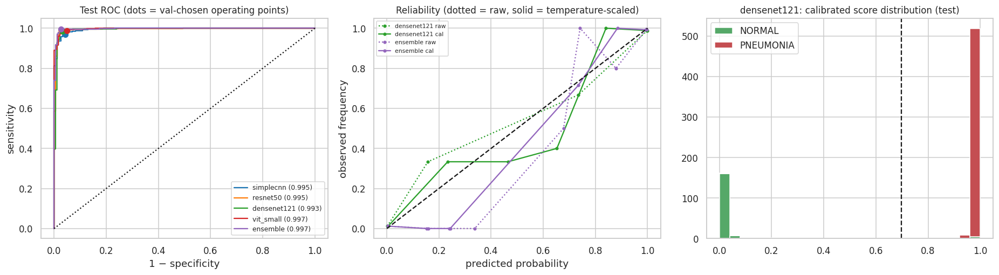

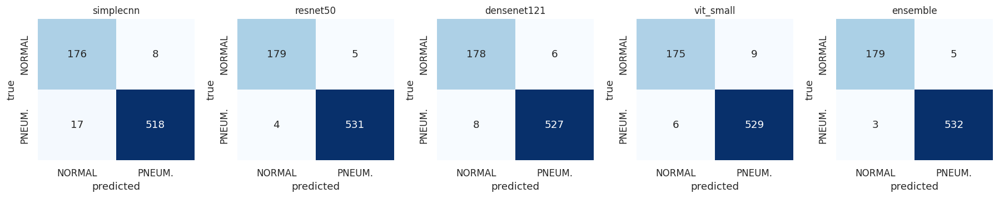

,recall[bacteria],recall[virus],specificity[normal]
simplecnn,0.983,0.939,0.957
resnet50,0.997,0.983,0.973
densenet121,0.997,0.961,0.967
vit_small,0.992,0.983,0.951
ensemble,1.000,0.983,0.973


In [ ]:
BEST_FAM = max(CFG["families"], key=lambda f: FINAL[f]["best"]["auroc"]); print("Best single family on validation:", BEST_FAM)
rows_ = []
for m in MODELS:
    if m == BEST_FAM: continue
    d = np.array([fast_auc(yt[i], EVAL[m]["pt"][i]) - fast_auc(yt[i], EVAL[BEST_FAM]["pt"][i]) for i in BOOT])
    rows_.append(dict(model=m, vs=BEST_FAM, delta_AUROC=d.mean(), ci_lo=np.percentile(d, 2.5), ci_hi=np.percentile(d, 97.5), p_boot=2 * min((d <= 0).mean(), (d >= 0).mean())))
PAIRED = pd.DataFrame(rows_).set_index("model").round(4); display(PAIRED)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); cols = sns.color_palette("tab10", len(MODELS))
for c, m in zip(cols, MODELS):
    fpr, tpr, _ = roc_curve(yt, EVAL[m]["pt"]); ax[0].plot(fpr, tpr, c=c, label=f"{m} ({RES.loc[m,'AUROC']:.3f})")
    mt = metrics_at(yt, EVAL[m]["pt"], EVAL[m]["thr"]); ax[0].scatter(1 - mt["specificity"], mt["sensitivity"], c=[c], s=40, zorder=5)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="1 − specificity", ylabel="sensitivity", title="Test ROC (dots = val-chosen operating points)"); ax[0].legend(fontsize=8, loc="lower right")
for c, m in zip(cols, MODELS):
    for yy, (pp, ls) in {"raw": (EVAL[m]["lt_raw_p"], ":"), "cal": (EVAL[m]["pt"], "-")}.items():
        edges = np.linspace(0, 1, 11); ix = np.clip(np.digitize(pp, edges) - 1, 0, 9); xs = [pp[ix == b].mean() for b in range(10) if (ix == b).sum() >= 3]; ys = [yt[ix == b].mean() for b in range(10) if (ix == b).sum() >= 3]
        if m in (BEST_FAM, "ensemble"): ax[1].plot(xs, ys, ls, c=c, marker="o", ms=3, label=f"{m} {yy}")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set(xlabel="predicted probability", ylabel="observed frequency", title="Reliability (dotted = raw, solid = temperature-scaled)"); ax[1].legend(fontsize=7)
ax[2].hist([EVAL[BEST_FAM]["pt"][yt == 0], EVAL[BEST_FAM]["pt"][yt == 1]], bins=25, label=["NORMAL", "PNEUMONIA"], color=["#55a868", "#c44e52"], stacked=True); ax[2].axvline(EVAL[BEST_FAM]["thr"], c="k", ls="--"); ax[2].set_title(f"{BEST_FAM}: calibrated score distribution (test)"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_roc_calibration.png"); plt.show()

fig, axs = plt.subplots(1, len(MODELS), figsize=(3.3 * len(MODELS), 3.4))
for ax_, m in zip(axs, MODELS):
    mt = metrics_at(yt, EVAL[m]["pt"], EVAL[m]["thr"]); cm = np.array([[mt["tn"], mt["fp"]], [mt["fn"], mt["tp"]]])
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax_, xticklabels=["NORMAL", "PNEUM."], yticklabels=["NORMAL", "PNEUM."]); ax_.set(title=m, xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_confusion.png"); plt.show()

sub_t = manifest.subtype.values[ROWS["test"]]
EA = {}
for m in MODELS:
    pred = (EVAL[m]["pt"] >= EVAL[m]["thr"]).astype(int)
    EA[m] = {f"recall[{s}]": (pred[(sub_t == s)] == (1 if s != "normal" else 0)).mean() for s in ["bacteria", "virus", "normal"] if (sub_t == s).any()}
display(pd.DataFrame(EA).T.round(3).rename(columns=lambda c: c.replace("recall[normal]", "specificity[normal]")))


In [ ]:
for m in MODELS:
    with mlf_run("eval", m, "test"):
        mlflow.log_metrics({f"test_{k}": float(RES.loc[m, k]) for k in ["AUROC", "AUROC_lo", "AUROC_hi", "AUPRC", "sensitivity", "specificity", "balanced_acc", "f1", "ECE_raw", "ECE_cal", "Brier"]})
        mlflow.log_params({"threshold_val_youden": round(EVAL[m]["thr"], 4), "temperature": round(EVAL[m]["T"], 4)})
        mlflow.log_artifact(str(FIG_DIR / "eval_roc_calibration.png"))
CALIB = {m: dict(temperature=EVAL[m]["T"], threshold=EVAL[m]["thr"]) for m in MODELS}
(ART_DIR / "calibration_and_thresholds.json").write_text(json.dumps(CALIB, indent=2))
for m in MODELS: np.save(ART_DIR / "models" / f"{m}_test_logits.npy", EVAL[m]["lt"])
print("saved calibration + thresholds + test logits")


saved calibration + thresholds + test logits


12b. Duplicate sensitivity

In [ ]:
dg_t   = manifest.dup_group.values[ROWS["test"]]
lab_nu = manifest.groupby("dup_group").y.nunique()
conflict_groups = set(lab_nu[lab_nu > 1].index)
first_of_cluster = ~pd.Series(dg_t).duplicated(keep="first").values
in_conflict      = np.isin(dg_t, list(conflict_groups))
keep = first_of_cluster & ~in_conflict
n_full, n_keep = len(yt), int(keep.sum())
print(f"test images: {n_full:,} -> {n_keep:,} after de-duplication "
      f"(removed {int((~first_of_cluster).sum())} repeated copies, excluded {int((first_of_cluster & in_conflict).sum())} label-conflict clusters)")

gid_k = manifest.group_id.values[ROWS["test"]][keep]; Gk = [np.where(gid_k == g)[0] for g in np.unique(gid_k)]
rngk = np.random.RandomState(SEED); BOOT_K = [np.concatenate([Gk[i] for i in rngk.randint(0, len(Gk), len(Gk))]) for _ in range(CFG["n_boot"])]

rows_dd = []
for m in MODELS:
    pk, yk = EVAL[m]["pt"][keep], yt[keep]
    mt = metrics_at(yk, pk, EVAL[m]["thr"]); auc = fast_auc(yk, pk)
    bs = [fast_auc(yk[i], pk[i]) for i in BOOT_K if 0 < yk[i].sum() < len(i)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    full_lo, full_hi = RES.loc[m, "AUROC_lo"], RES.loc[m, "AUROC_hi"]
    rows_dd.append(dict(model=m, AUROC_full=RES.loc[m, "AUROC"], AUROC_dedup=auc, dedup_ci_lo=lo, dedup_ci_hi=hi,
                        sens_full=RES.loc[m, "sensitivity"], sens_dedup=mt["sensitivity"],
                        spec_full=RES.loc[m, "specificity"], spec_dedup=mt["specificity"],
                        dedup_AUROC_inside_full_CI=bool(full_lo <= auc <= full_hi)))
DEDUP = pd.DataFrame(rows_dd).set_index("model").round(4); display(DEDUP)
DEDUP.to_csv(ART_DIR / "duplicate_sensitivity_test.csv")

max_gap = float((DEDUP.AUROC_full - DEDUP.AUROC_dedup).abs().max())
same = bool(DEDUP.dedup_AUROC_inside_full_CI.all()) and max_gap < 0.005
DEDUP_NOTE = (f"Duplicates were retained but grouped (no cluster crosses a split). Recomputing test metrics on {n_keep:,} de-duplicated images "
              f"(from {n_full:,}) " + (f"gives AUROC inside the full-test 95% CI for every model and a largest AUROC change of {max_gap:.4f}, so duplicates do not materially affect the reported results."
              if same else f"changes AUROC by up to {max_gap:.4f} or leaves the full-test CI for at least one model, so duplicates DO affect the reported results - report the de-duplicated table."))
(ART_DIR / "duplicate_sensitivity.md").write_text(DEDUP_NOTE + "\n"); print("\n" + DEDUP_NOTE)


test images: 719 -> 712 after de-duplication (removed 7 repeated copies, excluded 0 label-conflict clusters)


,AUROC_full,AUROC_dedup,dedup_ci_lo,dedup_ci_hi,sens_full,sens_dedup,spec_full,spec_dedup,dedup_AUROC_inside_full_CI
model,,,,,,,,,
simplecnn,0.9952,0.9952,0.9911,0.9980,0.9682,0.9681,0.9565,0.9609,True
resnet50,0.9954,0.9953,0.9893,0.9992,0.9925,0.9925,0.9728,0.9721,True
densenet121,0.9931,0.9930,0.9841,0.9986,0.9850,0.9850,0.9674,0.9665,True
vit_small,0.9972,0.9971,0.9947,0.9991,0.9888,0.9887,0.9511,0.9553,True
ensemble,0.9972,0.9971,0.9932,0.9995,0.9944,0.9944,0.9728,0.9721,True



Duplicates were retained but grouped (no cluster crosses a split). Recomputing test metrics on 712 de-duplicated images (from 719) gives AUROC inside the full-test 95% CI for every model and a largest AUROC change of 0.0001, so duplicates do not materially affect the reported results.


13. Explainability

In [ ]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, LayerCAM, HiResCAM
import torchvision.transforms.v2.functional as TF
from scipy.stats import spearmanr
from contextlib import contextmanager
IMG = CFG["img_size"]

def target_layers(m):
    return {"simplecnn": lambda: [m.backbone.features[-2]], "resnet50": lambda: [m.backbone.layer4[-1]],
            "densenet121": lambda: [m.backbone.features.norm5], "vit_small": lambda: [m.backbone.blocks[-1].norm1]}[m.family]()
def vit_reshape(t, h=IMG // 16, w=IMG // 16): return t[:, 1:, :].reshape(t.size(0), h, w, t.size(2)).permute(0, 3, 1, 2)
class SignedLogit:
    def __init__(self, sign): self.sign = sign
    def __call__(self, out): return self.sign * out.reshape(-1)[0]

CAM_CLS = {"GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus, "LayerCAM": LayerCAM, "HiResCAM": HiResCAM}
@contextmanager
def cam_ctx(model, name):
    model.eval().to(DEVICE)
    cam = CAM_CLS[name](model=model, target_layers=target_layers(model), reshape_transform=vit_reshape if model.family == "vit_small" else None)
    try: yield cam
    finally: cam.__exit__(None, None, None)

def _norm01(a):
    a = a.astype(np.float32); lo = a.reshape(len(a), -1).min(1)[:, None, None]; hi = a.reshape(len(a), -1).max(1)[:, None, None]
    return (a - lo) / np.maximum(hi - lo, 1e-8)
def _grad(model, x, sign):
    x = x.clone().requires_grad_(True); out = model(x); (sign.reshape(-1) * out).sum().backward(); return x.grad.detach()
def smoothgrad(model, x, signs, n=12, sigma=.15):
    model.eval(); sd = sigma * (x.max() - x.min()); acc = 0
    for _ in range(n): acc = acc + _grad(model, x + torch.randn_like(x) * sd, signs.view(-1, 1, 1, 1))
    return (acc / n).abs().mean(1)
def integrated_gradients(model, x, signs, steps=20):
    model.eval(); base = torch.zeros_like(x); acc = 0
    for a in torch.linspace(1 / steps, 1, steps): acc = acc + _grad(model, base + a * (x - base), signs.view(-1, 1, 1, 1))
    return ((x - base) * acc / steps).abs().sum(1)
def _smooth(a, k=7): return cv2.GaussianBlur(a, (k, k), 0)

METHODS = ["GradCAM", "GradCAM++", "LayerCAM", "HiResCAM", "IntegratedGradients", "SmoothGrad", "Random"]
def explain(model, x, signs, method, rng=None):
    x = x.to(DEVICE); signs = signs.to(DEVICE)
    if method in CAM_CLS:
        with cam_ctx(model, method) as cam:
            maps = cam(input_tensor=x, targets=[SignedLogit(float(s)) for s in signs.tolist()])
        return _norm01(np.asarray(maps))
    if method == "Random": return _norm01((rng or np.random.RandomState(0)).rand(len(x), IMG, IMG)).astype(np.float32)
    g = integrated_gradients(model, x, signs) if method == "IntegratedGradients" else smoothgrad(model, x, signs)
    g = g.detach().cpu().numpy(); g = np.minimum(g, np.percentile(g.reshape(len(g), -1), 99, axis=1)[:, None, None])
    return _norm01(np.stack([_smooth(m) for m in g]))

def get_x(rows):
    return normalise(torch.from_numpy(IMGS[rows]).float().div(255).unsqueeze(1))
def p_of(model, x, bs=64):
    with torch.no_grad(): return torch.cat([torch.sigmoid(model(x[i:i + bs].to(DEVICE)).float()).cpu() for i in range(0, len(x), bs)]).numpy()

bm = FINAL[BEST_FAM]["model"].eval().to(DEVICE); e_best = EVAL[BEST_FAM]
pred_t = (e_best["pt"] >= e_best["thr"]).astype(int)
outcome = np.where((yt == 1) & (pred_t == 1), "TP", np.where((yt == 0) & (pred_t == 0), "TN", np.where((yt == 0) & (pred_t == 1), "FP", "FN")))
rs = np.random.RandomState(SEED); pick = []
for o in ["TP", "TN", "FP", "FN"]:
    ix = np.where(outcome == o)[0]; pick += list(rs.choice(ix, min(len(ix), CFG["n_explain"] // 4), replace=False))
rest = np.setdiff1d(np.arange(len(yt)), pick); pick += list(rs.choice(rest, max(0, min(len(rest), CFG["n_explain"] - len(pick))), replace=False))
EX_IDX = np.array(sorted(pick)); EX_ROWS = ROWS["test"][EX_IDX]; EX_X = get_x(EX_ROWS)
EX_SIGN = torch.tensor(np.where(pred_t[EX_IDX] == 1, 1., -1.), dtype=torch.float32)
print(f"{len(EX_IDX)} explanation images from {BEST_FAM} — outcomes:", dict(Counter(outcome[EX_IDX])))
EX_MAPS = {m: np.concatenate([explain(bm, EX_X[i:i + 16], EX_SIGN[i:i + 16], m, np.random.RandomState(i)) for i in range(0, len(EX_X), 16)]) for m in METHODS}
print({m: v.shape for m, v in EX_MAPS.items()})


120 explanation images from densenet121 — outcomes: {np.str_('TN'): 38, np.str_('FP'): 6, np.str_('TP'): 68, np.str_('FN'): 8}
{'GradCAM': (120, 224, 224), 'GradCAM++': (120, 224, 224), 'LayerCAM': (120, 224, 224), 'HiResCAM': (120, 224, 224), 'IntegratedGradients': (120, 224, 224), 'SmoothGrad': (120, 224, 224), 'Random': (120, 224, 224)}


13.2 Faithfulness: deletion and insertion

,deletion_AUC,insertion_AUC,del_sd,ins_sd,ins−del (higher=better)
GradCAM++,0.691,0.889,0.367,0.154,0.198
GradCAM,0.691,0.889,0.365,0.157,0.198
HiResCAM,0.690,0.887,0.366,0.163,0.196
LayerCAM,0.693,0.889,0.366,0.154,0.196
IntegratedGradients,0.693,0.830,0.392,0.236,0.137
SmoothGrad,0.729,0.840,0.346,0.233,0.111
Random,0.711,0.715,0.372,0.367,0.004


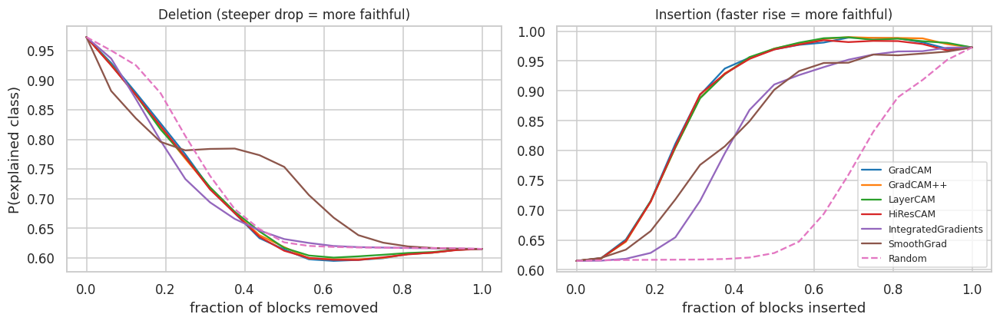

Most faithful method on this model: GradCAM++


In [ ]:
trap = getattr(np, "trapezoid", None) or np.trapz
def del_ins(model, x1, sal, sign, steps=16, block=8):
    H = x1.shape[-1]; nb = H // block; bs = sal.reshape(nb, block, nb, block).mean((1, 3)); order = np.argsort(-bs.ravel())
    sg = H / 16; k = 2 * int(3 * sg) + 1; base = TF.gaussian_blur(x1, kernel_size=[k, k], sigma=[sg, sg])
    fs = np.linspace(0, 1, steps + 1); D, I = [], []
    for f in fs:
        m = np.zeros(nb * nb, np.float32); m[order[:int(round(f * nb * nb))]] = 1
        M = torch.from_numpy(m.reshape(nb, nb)).repeat_interleave(block, 0).repeat_interleave(block, 1)[None, None].to(x1.device)
        D.append(x1 * (1 - M) + base * M); I.append(base * (1 - M) + x1 * M)
    with torch.no_grad(): pr = torch.sigmoid(sign * model(torch.cat(D + I)).float()).cpu().numpy()
    return trap(pr[:steps + 1], fs), trap(pr[steps + 1:], fs), pr[:steps + 1], pr[steps + 1:]

bm.eval(); FAITH = {m: [] for m in METHODS}; CURVES = {m: [] for m in METHODS}
for i in range(len(EX_IDX)):
    x1 = EX_X[i:i + 1].to(DEVICE); s = float(EX_SIGN[i])
    for m in METHODS:
        d, ins, cd, ci = del_ins(bm, x1, EX_MAPS[m][i], s); FAITH[m].append((d, ins)); CURVES[m].append((cd, ci))
FT = pd.DataFrame({m: dict(deletion_AUC=np.mean([a for a, _ in v]), insertion_AUC=np.mean([b for _, b in v]), **{"del_sd": np.std([a for a, _ in v]), "ins_sd": np.std([b for _, b in v])}) for m, v in FAITH.items()}).T
FT["ins−del (higher=better)"] = FT.insertion_AUC - FT.deletion_AUC; FT = FT.sort_values("ins−del (higher=better)", ascending=False); display(FT.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); fs_ = np.linspace(0, 1, 17); pal = dict(zip(METHODS, sns.color_palette("tab10", len(METHODS))))
for m in METHODS:
    ax[0].plot(fs_, np.mean([c[0] for c in CURVES[m]], 0), c=pal[m], ls="--" if m == "Random" else "-", label=m); ax[1].plot(fs_, np.mean([c[1] for c in CURVES[m]], 0), c=pal[m], ls="--" if m == "Random" else "-", label=m)
ax[0].set(title="Deletion (steeper drop = more faithful)", xlabel="fraction of blocks removed", ylabel="P(explained class)"); ax[1].set(title="Insertion (faster rise = more faithful)", xlabel="fraction of blocks inserted"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "xai_faithfulness.png"); plt.show()
BEST_METHOD = FT.drop(index="Random").index[0]; print("Most faithful method on this model:", BEST_METHOD)


13.3 Randomization sanity check

,GradCAM,GradCAM++,LayerCAM,IntegratedGradients,SmoothGrad
original,1.000,1.000,1.000,1.000,1.000
1 layer-groups randomised,0.084,0.475,0.476,0.661,0.234
2 layer-groups randomised,-0.056,0.106,0.173,0.473,0.186
3 layer-groups randomised,0.136,0.153,0.062,0.496,0.216
4 layer-groups randomised,0.040,-0.342,-0.393,0.414,-0.221
5 layer-groups randomised,0.165,0.306,0.201,0.335,0.162


Model-randomisation sanity check (mean |rho| over 3-5 randomised layer-groups < 0.25 = pass): {'GradCAM': True, 'GradCAM++': False, 'LayerCAM': True, 'IntegratedGradients': False, 'SmoothGrad': True}


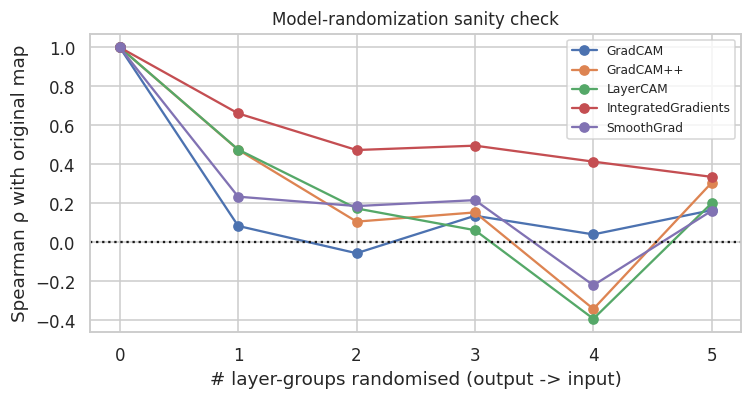

In [ ]:
def randomised_copy(model, n_levels, G=5):
    mm = copy.deepcopy(model).cpu(); mods = [m for _, m in mm.named_modules() if len(list(m.parameters(recurse=False))) > 0]
    groups = np.array_split(np.arange(len(mods)), G); done = []
    for g in reversed(groups[G - n_levels:] if n_levels else []): done += list(g)
    for i in done:
        m = mods[i]
        if hasattr(m, "reset_parameters"): m.reset_parameters()
        else:
            for p in m.parameters(recurse=False): nn.init.normal_(p, 0, .02)
    return mm.eval().to(DEVICE)
def lowres(a, n=28): return np.stack([cv2.resize(x, (n, n), interpolation=cv2.INTER_AREA) for x in a])
def corr(a, b):
    c = [spearmanr(x.ravel(), y.ravel())[0] for x, y in zip(a, b)]; return float(np.nanmean(np.nan_to_num(c)))

RAND_M = ["GradCAM", "GradCAM++", "LayerCAM", "IntegratedGradients", "SmoothGrad"]; nR = min(24, len(EX_IDX)); LV = [0, 1, 2, 3, 4, 5]; RAND = {m: [] for m in RAND_M}
for lv in LV:
    mr = randomised_copy(bm, lv) if lv else bm
    for m in RAND_M:
        mp = explain(mr, EX_X[:nR], EX_SIGN[:nR], m) if lv else EX_MAPS[m][:nR]
        RAND[m].append(corr(lowres(EX_MAPS[m][:nR]), lowres(mp)))
    if lv: del mr
RAND_DF = pd.DataFrame(RAND, index=[f"{l} layer-groups randomised" if l else "original" for l in LV]); display(RAND_DF.round(3))
RAND_PASS = {m: bool(np.mean(np.abs(RAND[m][3:])) < .25) for m in RAND_M}
print("Model-randomisation sanity check (mean |rho| over 3-5 randomised layer-groups < 0.25 = pass):", RAND_PASS)
fig, ax = plt.subplots(figsize=(7, 3.8))
for m in RAND_M: ax.plot(LV, RAND[m], marker="o", label=m)
ax.axhline(0, c="k", ls=":"); ax.set(xlabel="# layer-groups randomised (output -> input)", ylabel="Spearman ρ with original map", title="Model-randomization sanity check"); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "xai_randomization.png"); plt.show()


13.4 Stability

In [ ]:
def top_iou(a, b, q=80):
    A = a >= np.percentile(a, q); B = b >= np.percentile(b, q); return float((A & B).sum() / max((A | B).sum(), 1))
torch.manual_seed(SEED); Xp = (EX_X + torch.randn_like(EX_X) * .05 / 0.226).clone()
Xp = Xp * 1.03
STAB = {}
for m in [x for x in METHODS if x != "Random"]:
    mp = np.concatenate([explain(bm, Xp[i:i + 16], EX_SIGN[i:i + 16], m) for i in range(0, len(Xp), 16)])
    STAB[m] = dict(spearman=corr(lowres(EX_MAPS[m]), lowres(mp)), top20_IoU=float(np.mean([top_iou(a, b) for a, b in zip(lowres(EX_MAPS[m]), lowres(mp))])))
STAB_DF = pd.DataFrame(STAB).T.sort_values("spearman", ascending=False); display(STAB_DF.round(3))


,spearman,top20_IoU
IntegratedGradients,0.816,0.498
SmoothGrad,0.790,0.515
LayerCAM,0.776,0.544
GradCAM++,0.773,0.539
HiResCAM,0.756,0.531
GradCAM,0.746,0.514


13.5 Shortcut audit

region,border,thorax_box,upper_corners
method,,,
GradCAM,0.70,1.25,0.66
GradCAM++,0.69,1.26,0.65
HiResCAM,0.69,1.26,0.65
IntegratedGradients,0.68,1.28,0.88
LayerCAM,0.68,1.27,0.65
Random,1.00,1.00,1.00
SmoothGrad,0.59,1.33,0.61


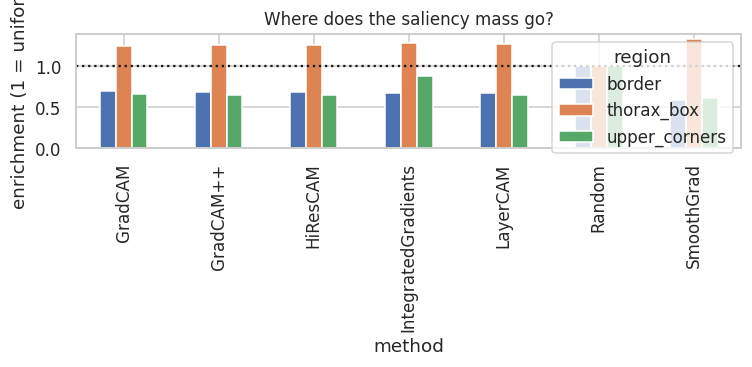

,original,centre_only,corners_masked,border_only,border_only_black,patch_shuffle_4x4,patch_shuffle_8x8
simplecnn,0.995,0.992,0.995,0.875,0.833,0.981,0.836
resnet50,0.995,0.992,0.995,0.953,0.947,0.986,0.869
densenet121,0.993,0.987,0.991,0.948,0.956,0.961,0.760
vit_small,0.997,0.992,0.997,0.932,0.924,0.987,0.882


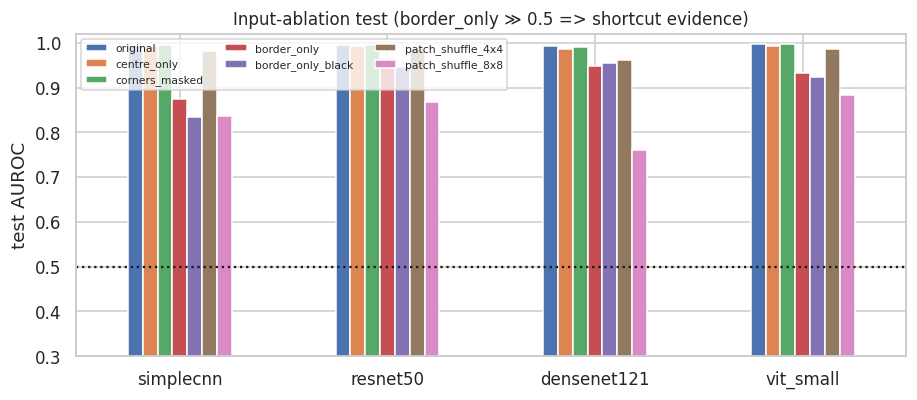

Shortcut flags: {'simplecnn': ' border-only AUROC 0.88', 'resnet50': ' border-only AUROC 0.95', 'densenet121': ' border-only AUROC 0.95', 'vit_small': ' border-only AUROC 0.93'}
Texture-reliance flags: {'simplecnn': 'patch-shuffle 4x4 AUROC 0.98 (only 0.015 below original): texture/global-statistics reliance', 'resnet50': 'patch-shuffle 4x4 AUROC 0.99 (only 0.009 below original): texture/global-statistics reliance', 'densenet121': 'ok', 'vit_small': 'patch-shuffle 4x4 AUROC 0.99 (only 0.010 below original): texture/global-statistics reliance'}


In [ ]:
yy_, xx_ = np.mgrid[0:IMG, 0:IMG] / IMG
M_BORDER = (xx_ < .12) | (xx_ > .88) | (yy_ < .12) | (yy_ > .88)
M_CORNER = ((yy_ < .22) & ((xx_ < .22) | (xx_ > .78)))
M_THORAX = (xx_ >= .15) & (xx_ <= .85) & (yy_ >= .12) & (yy_ <= .88)
def mass_share(maps, mask): s = maps / np.maximum(maps.sum((1, 2), keepdims=True), 1e-8); return (s * mask).sum((1, 2))
SH = []
for m in [x for x in METHODS]:
    for name, mk in [("border", M_BORDER), ("upper_corners", M_CORNER), ("thorax_box", M_THORAX)]:
        ms = mass_share(EX_MAPS[m], mk); SH.append(dict(method=m, region=name, mass_share=ms.mean(), enrichment=ms.mean() / mk.mean()))
SH = pd.DataFrame(SH); piv = SH.pivot(index="method", columns="region", values="enrichment").round(2); display(piv)
fig, ax = plt.subplots(figsize=(7, 3.5)); piv.plot.bar(ax=ax); ax.axhline(1, c="k", ls=":"); ax.set_ylabel("enrichment (1 = uniform)"); ax.set_title("Where does the saliency mass go?"); plt.tight_layout(); plt.savefig(FIG_DIR / "xai_saliency_regions.png"); plt.show()

def ablate(x01, kind, fill="blur"):
    if kind.endswith("_black"): kind, fill = kind[:-6], "black"
    B, _, H, W = x01.shape; yg, xg = torch.meshgrid(torch.arange(H) / H, torch.arange(W) / W, indexing="ij")
    if kind == "original": return x01
    if kind.startswith("patch_shuffle_"):
        n = int(kind.split("_")[-1].split("x")[0]); g = H // n; N = n * n
        t = x01[..., :n * g, :n * g].unfold(2, g, g).unfold(3, g, g).contiguous().view(B, 1, N, g, g)
        perm = torch.randperm(N, generator=torch.Generator().manual_seed(SEED)); t = t[:, :, perm]
        out = x01.clone(); out[..., :n * g, :n * g] = t.view(B, 1, n, n, g, g).permute(0, 1, 2, 4, 3, 5).reshape(B, 1, n * g, n * g)
        return out
    if kind == "border_only": mk = ((xg < .12) | (xg > .88) | (yg < .12) | (yg > .88)).float()
    elif kind == "centre_only": mk = ((xg >= .15) & (xg <= .85) & (yg >= .12) & (yg <= .88)).float()
    elif kind == "corners_masked": mk = 1 - ((yg < .22) & ((xg < .22) | (xg > .78))).float()
    else: raise ValueError(kind)
    mk = mk.to(x01.device)
    if fill == "black": return x01 * mk
    sg = H / 16; k = 2 * int(3 * sg) + 1; base = TF.gaussian_blur(x01, kernel_size=[k, k], sigma=[sg, sg])
    return x01 * mk + base * (1 - mk)
@torch.no_grad()
def logits_variant(model, rows, kind, bs=128):
    model.eval().to(DEVICE); out = []
    for i in range(0, len(rows), bs):
        x = torch.from_numpy(IMGS[rows[i:i + bs]]).float().div(255).unsqueeze(1); out.append(model(normalise(ablate(x, kind)).to(DEVICE)).float().cpu())
    return torch.cat(out).numpy()
KINDS = ["original", "centre_only", "corners_masked", "border_only", "border_only_black", "patch_shuffle_4x4", "patch_shuffle_8x8"]; ABL = {}
for fam in FAMILIES_ALL:
    mdl = FINAL[fam]["model"]; thr = EVAL[fam]["thr"]; T = EVAL[fam]["T"]; row = {}
    for k in KINDS:
        p = sigmoid(logits_variant(mdl, ROWS["test"], k) / T); row[k] = roc_auc_score(yt, p)
    ABL[fam] = row
ABL = pd.DataFrame(ABL).T[KINDS]; display(ABL.round(3))
fig, ax = plt.subplots(figsize=(8.5, 3.8)); ABL.plot.bar(ax=ax, rot=0); ax.axhline(.5, c="k", ls=":"); ax.set(ylabel="test AUROC", title="Input-ablation test (border_only ≫ 0.5 => shortcut evidence)", ylim=(.3, 1.02)); ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.savefig(FIG_DIR / "xai_ablation.png"); plt.show()
SHORTCUT_FLAGS = {f: (" border-only AUROC {:.2f}".format(ABL.loc[f, "border_only"]) if ABL.loc[f, "border_only"] >= .75 else "ok") for f in ABL.index}
print("Shortcut flags:", SHORTCUT_FLAGS)
TEXTURE_FLAGS = {f: ("patch-shuffle 4x4 AUROC {:.2f} (only {:.3f} below original): texture/global-statistics reliance".format(ABL.loc[f, "patch_shuffle_4x4"], ABL.loc[f, "original"] - ABL.loc[f, "patch_shuffle_4x4"])
                     if ABL.loc[f, "original"] - ABL.loc[f, "patch_shuffle_4x4"] < .02 else "ok") for f in ABL.index}
print("Texture-reliance flags:", TEXTURE_FLAGS)


13.5b Does the model still work when metadata gives no hint?

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
def grouped_oof(X, y, groups, k=5):
    oof = np.zeros(len(y))
    for tr, te in GroupKFold(k).split(X, y, groups):
        m = HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, random_state=SEED).fit(X.iloc[tr], y[tr])
        oof[te] = m.predict_proba(X.iloc[te])[:, 1]
    return oof
meta_oof = grouped_oof(manifest[meta_cols], manifest.y.values, manifest.group_id.values)
ms_t = meta_oof[ROWS["test"]]
def qbins(v, q): return pd.qcut(pd.Series(v).rank(method="first"), q, labels=False).values
BINSETS = {"metadata-score deciles": qbins(ms_t, 10)}
for c_, nm_ in [("width", "width quartiles"), ("file_bytes", "file-size quartiles"), ("mean_int", "mean-intensity quartiles"), ("std_int", "contrast quartiles")]:
    BINSETS[nm_] = qbins(manifest[c_].values[ROWS["test"]], 4)
MIN_EACH = 3 if SMOKE else 10
def binned_auc(y, p, b, min_each=MIN_EACH):
    num = den = 0.0
    for k in np.unique(b):
        m = b == k; n1 = int(y[m].sum()); n0 = int(m.sum()) - n1
        if n1 >= min_each and n0 >= min_each: num += m.sum() * fast_auc(y[m], p[m]); den += m.sum()
    return (num / den if den else np.nan), den
rows_m = []
for m in MODELS:
    p = EVAL[m]["pt"]; row = {"overall AUROC": RES.loc[m, "AUROC"]}
    for nm_, b_ in BINSETS.items():
        a_, den_ = binned_auc(yt, p, b_); row[nm_] = a_; row[f"coverage[{nm_}]"] = den_ / len(yt)
    vals = np.array([binned_auc(yt[i], p[i], BINSETS["metadata-score deciles"][i])[0] for i in BOOT], float); vals = vals[~np.isnan(vals)]
    row["metadata-score CI lo"], row["metadata-score CI hi"] = (np.percentile(vals, [2.5, 97.5]) if len(vals) else (np.nan, np.nan))
    rows_m.append(pd.Series(row, name=m))
MATCHED = pd.DataFrame(rows_m); display(MATCHED.round(3)); MATCHED.to_csv(ART_DIR / "matched_bin_auroc.csv")
b0 = BINSETS["metadata-score deciles"]; det = []
for k in np.unique(b0):
    mk_ = b0 == k; n1 = int(yt[mk_].sum()); n0 = int(mk_.sum()) - n1
    det.append(dict(decile=int(k), n=int(mk_.sum()), n_pneumonia=n1, n_normal=n0, metadata_P_pneumonia=ms_t[mk_].mean(),
                    ensemble_AUROC=(fast_auc(yt[mk_], EVAL["ensemble"]["pt"][mk_]) if min(n1, n0) >= MIN_EACH else np.nan)))
display(pd.DataFrame(det).round(3))
cov0 = float(MATCHED["coverage[metadata-score deciles]"].iloc[0])
print(f"Bins with >= {MIN_EACH} images of EACH class cover {cov0:.0%} of the test set.")
if cov0 < .3: print("  -> metadata alone separates the classes so well that only a small slice of the test set can be compared at equal metadata score. That is itself the shortcut finding.")
for m in MODELS:
    o, a_ = MATCHED.loc[m, "overall AUROC"], MATCHED.loc[m, "metadata-score deciles"]
    verdict = "n/a (no informative bins)" if np.isnan(a_) else ("holds up" if a_ >= o - .02 else "DROPS: part of the score comes from cues metadata can see")
    print(f"  {m:12s} overall {o:.3f} -> matched-on-metadata {a_:.3f}  {verdict}")


,overall AUROC,metadata-score deciles,coverage[metadata-score deciles],width quartiles,coverage[width quartiles],file-size quartiles,coverage[file-size quartiles],mean-intensity quartiles,coverage[mean-intensity quartiles],contrast quartiles,coverage[contrast quartiles],metadata-score CI lo,metadata-score CI hi
simplecnn,0.995,0.961,0.1,0.986,0.499,0.967,0.499,0.993,1.0,0.993,0.75,0.898,0.990
resnet50,0.995,0.982,0.1,0.988,0.499,0.962,0.499,0.994,1.0,0.993,0.75,0.899,0.999
densenet121,0.993,0.974,0.1,0.988,0.499,0.960,0.499,0.992,1.0,0.993,0.75,0.900,0.997
vit_small,0.997,0.984,0.1,0.992,0.499,0.981,0.499,0.995,1.0,0.995,0.75,0.934,1.000
ensemble,0.997,0.985,0.1,0.992,0.499,0.976,0.499,0.996,1.0,0.996,0.75,0.921,1.000


,decile,n,n_pneumonia,n_normal,metadata_P_pneumonia,ensemble_AUROC
0,0,72,0,72,0.000,NaN
1,1,72,1,71,0.001,NaN
2,2,72,39,33,0.532,0.985
3,3,72,65,7,0.981,NaN
4,4,72,71,1,0.998,NaN
5,5,71,71,0,0.999,NaN
6,6,72,72,0,1.000,NaN
7,7,72,72,0,1.000,NaN
8,8,72,72,0,1.000,NaN
9,9,72,72,0,1.000,NaN


Bins with >= 10 images of EACH class cover 10% of the test set.
  -> metadata alone separates the classes so well that only a small slice of the test set can be compared at equal metadata score. That is itself the shortcut finding.
  simplecnn    overall 0.995 -> matched-on-metadata 0.961  DROPS: part of the score comes from cues metadata can see
  resnet50     overall 0.995 -> matched-on-metadata 0.982  holds up
  densenet121  overall 0.993 -> matched-on-metadata 0.974  holds up
  vit_small    overall 0.997 -> matched-on-metadata 0.984  holds up
  ensemble     overall 0.997 -> matched-on-metadata 0.985  holds up


In [ ]:
@torch.no_grad()
def logits_from_arrays(model, arr_u8, bs=128):
    model.eval().to(DEVICE); out = []
    for i in range(0, len(arr_u8), bs):
        x = torch.from_numpy(np.ascontiguousarray(arr_u8[i:i + bs])).float().div(255).unsqueeze(1)
        out.append(model(normalise(x).to(DEVICE)).float().cpu())
    return torch.cat(out).numpy()
rng_s = np.random.RandomState(SEED); pos_t = np.where(yt == 1)[0]; neg_t = np.where(yt == 0)[0]
n_sw = int(min(200, len(pos_t), len(neg_t)))
A0 = IMGS[ROWS["test"][rng_s.choice(pos_t, n_sw, replace=False)]]; B0 = IMGS[ROWS["test"][rng_s.choice(neg_t, n_sw, replace=False)]]
A1 = np.where(M_BORDER[None], B0, A0); B1 = np.where(M_BORDER[None], A0, B0)
A2 = np.where(M_BORDER[None], A0[rng_s.permutation(n_sw)], A0); B2 = np.where(M_BORDER[None], B0[rng_s.permutation(n_sw)], B0)
ZS = {}
for f in FAMILIES_ALL: ZS[f] = {k: logits_from_arrays(FINAL[f]["model"], v) / EVAL[f]["T"] for k, v in dict(A0=A0, A1=A1, A2=A2, B0=B0, B1=B1, B2=B2).items()}
ZS["ensemble"] = {k: np.mean([ZS[f][k] for f in CFG["families"]], 0) / EVAL["ensemble"]["T"] for k in ("A0", "A1", "A2", "B0", "B1", "B2")}
rows_s = []
for m, z in ZS.items():
    thr_l = float(np.log(EVAL[m]["thr"] / (1 - EVAL[m]["thr"])))
    gap = float((EVAL[m]["lt"][yt == 1].mean() - EVAL[m]["lt"][yt == 0].mean()) / EVAL[m]["T"])
    d_pos, d_neg = float((z["A1"] - z["A0"]).mean()), float((z["B1"] - z["B0"]).mean())
    rows_s.append(dict(model=m, class_logit_gap=gap, pneumonia_img_with_normal_border=d_pos, normal_img_with_pneumonia_border=d_neg,
                       seam_control_pneumonia=float((z["A2"] - z["A0"]).mean()), seam_control_normal=float((z["B2"] - z["B0"]).mean()),
                       share_of_class_gap_explained_by_border=(d_neg - d_pos) / (2 * gap) if gap else np.nan,
                       pneumonia_flipped_to_normal=float(((z["A0"] >= thr_l) & (z["A1"] < thr_l)).sum() / max((z["A0"] >= thr_l).sum(), 1)),
                       normal_flipped_to_pneumonia=float(((z["B0"] < thr_l) & (z["B1"] >= thr_l)).sum() / max((z["B0"] < thr_l).sum(), 1))))
BSWAP = pd.DataFrame(rows_s).set_index("model"); display(BSWAP.round(3)); BSWAP.to_csv(ART_DIR / "border_swap_counterfactual.csv")
print(f"{n_sw} image pairs. Shifts are in calibrated-logit units; the seam controls swap borders between images of the SAME class (should be ~0). "
      "A large 'share_of_class_gap_explained_by_border' (0 = border irrelevant, 1 = border alone decides) is direct evidence of a border shortcut.")


,class_logit_gap,pneumonia_img_with_normal_border,normal_img_with_pneumonia_border,seam_control_pneumonia,seam_control_normal,share_of_class_gap_explained_by_border,pneumonia_flipped_to_normal,normal_flipped_to_pneumonia
model,,,,,,,,
simplecnn,12.126,-2.500,1.711,-0.527,0.079,0.174,0.111,0.051
resnet50,13.270,-3.074,2.919,-0.429,0.377,0.226,0.060,0.073
densenet121,14.812,-2.631,4.384,-0.628,1.227,0.237,0.060,0.062
vit_small,10.983,-1.069,2.928,0.357,0.469,0.182,0.055,0.131
ensemble,14.121,-2.449,3.698,-0.253,0.749,0.218,0.043,0.084


184 image pairs. Shifts are in calibrated-logit units; the seam controls swap borders between images of the SAME class (should be ~0). A large 'share_of_class_gap_explained_by_border' (0 = border irrelevant, 1 = border alone decides) is direct evidence of a border shortcut.


13.6 Cross-model agreement

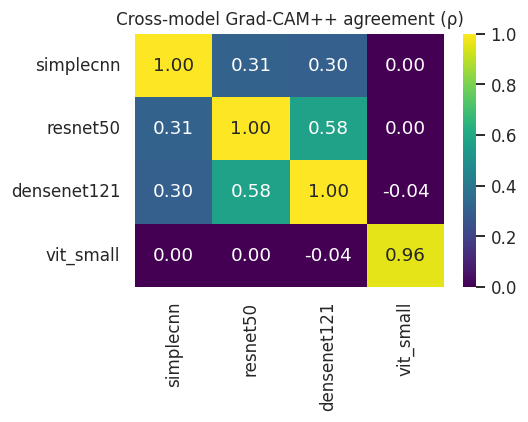

Per-image mean agreement among ['resnet50', 'densenet121', 'vit_small']: median 0.16 | low-agreement images (ρ<0.2): 69/120


In [ ]:
CROSS = {}
for fam in FAMILIES_ALL:
    mdl = FINAL[fam]["model"].eval().to(DEVICE)
    CROSS[fam] = np.concatenate([explain(mdl, EX_X[i:i + 16], EX_SIGN[i:i + 16], "GradCAM++") for i in range(0, len(EX_X), 16)])
AG = pd.DataFrame(index=FAMILIES_ALL, columns=FAMILIES_ALL, dtype=float)
for a, b in itertools.product(FAMILIES_ALL, FAMILIES_ALL): AG.loc[a, b] = corr(lowres(CROSS[a]), lowres(CROSS[b]))
fig, ax = plt.subplots(figsize=(5, 4)); sns.heatmap(AG.astype(float), annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax); ax.set_title("Cross-model Grad-CAM++ agreement (ρ)"); plt.tight_layout(); plt.savefig(FIG_DIR / "xai_agreement.png"); plt.show()
CONSENSUS = _norm01(np.mean([CROSS[f] for f in CFG["families"]], 0))
AGREE_IMG = np.mean([[corr(lowres(CROSS[a][i:i + 1]), lowres(CROSS[b][i:i + 1])) for a, b in itertools.combinations(CFG["families"], 2)] for i in range(len(EX_IDX))], 1)
print(f"Per-image mean agreement among {CFG['families']}: median {np.median(AGREE_IMG):.2f} | low-agreement images (ρ<0.2): {(AGREE_IMG < .2).sum()}/{len(AGREE_IMG)}")


13.7 Gallery by outcome

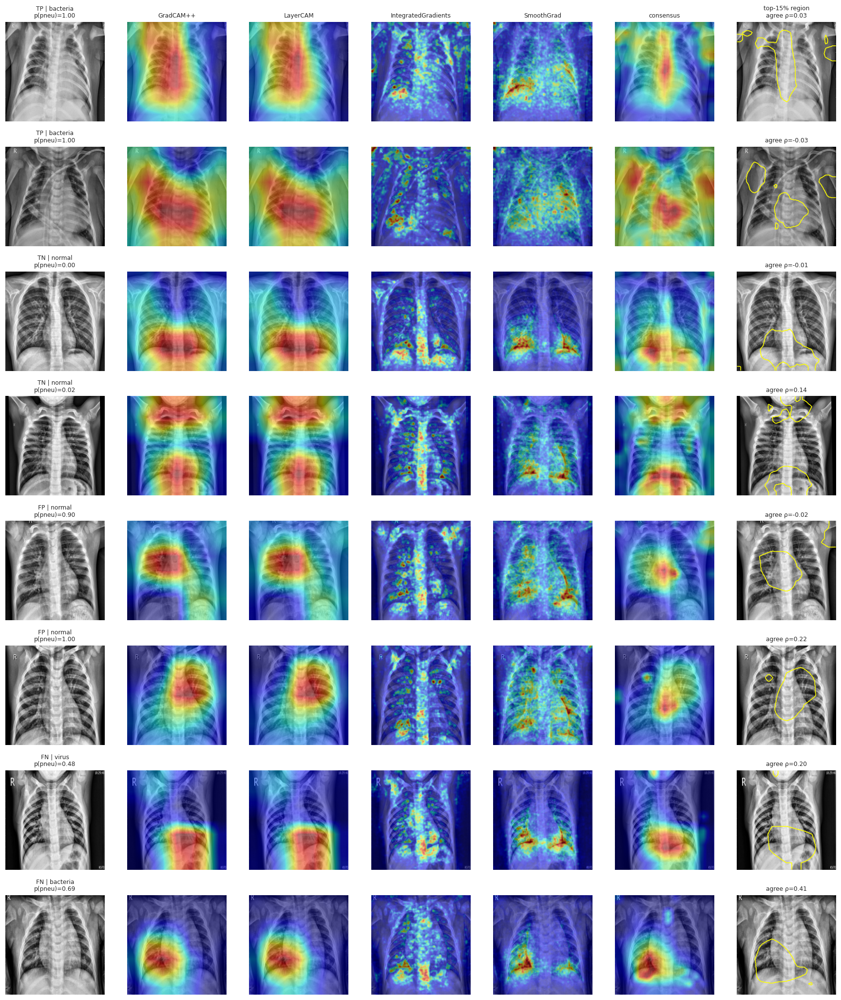

In [ ]:
def overlay(ax, img, sal, title=None, alpha=.5):
    ax.imshow(img, cmap="gray"); ax.imshow(sal, cmap="jet", alpha=alpha, vmin=0, vmax=1); ax.axis("off")
    if title: ax.set_title(title, fontsize=8)
show_m = ["GradCAM++", "LayerCAM", "IntegratedGradients", "SmoothGrad"]; cases = []
for o in ["TP", "TN", "FP", "FN"]:
    ii = [k for k, g in enumerate(EX_IDX) if outcome[g] == o]; cases += ii[:2]
fig, axs = plt.subplots(len(cases), len(show_m) + 3, figsize=(2.3 * (len(show_m) + 3), 2.35 * len(cases)))
axs = np.atleast_2d(axs)
for r, k in enumerate(cases):
    g = EX_IDX[k]; img = IMGS[EX_ROWS[k]]
    axs[r, 0].imshow(img, cmap="gray"); axs[r, 0].axis("off"); axs[r, 0].set_title(f"{outcome[g]} | {manifest.subtype.values[EX_ROWS[k]]}\np(pneu)={e_best['pt'][g]:.2f}", fontsize=8)
    for c, m in enumerate(show_m): overlay(axs[r, c + 1], img, EX_MAPS[m][k], m if r == 0 else None)
    overlay(axs[r, -2], img, CONSENSUS[k], "consensus" if r == 0 else None); axs[r, -2].set_xlabel("")
    axs[r, -1].imshow(img, cmap="gray"); axs[r, -1].contour(CONSENSUS[k] >= np.percentile(CONSENSUS[k], 85), colors="yellow", linewidths=1); axs[r, -1].axis("off"); axs[r, -1].set_title(f"top-15% region\nagree ρ={AGREE_IMG[k]:.2f}" if r == 0 else f"agree ρ={AGREE_IMG[k]:.2f}", fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "xai_gallery.png", bbox_inches="tight"); plt.show()


13.8 Uncertainty and risk-coverage

ensemble threshold: single-pass 0.7015 -> TTA-mean 0.6365


,val AURC (lower = better)
confidence,0.0006
TTA_std,0.0006
combined,0.0006


Chosen uncertainty score (on validation): combined
AURC values are tied (range < 0.001), so this choice is arbitrary


,n,error_rate,sensitivity,specificity,fn,fp
all cases,719.0,0.014,0.996,0.957,2.0,8.0
answered (not flagged),658.0,0.005,0.998,0.986,1.0,2.0
flagged low-confidence,61.0,0.115,0.960,0.833,1.0,6.0


Test coverage 91.5% | errors falling in the flagged set: 7/10 (flagged share of all cases 8.5%)  (abstention-quality metric from the proposal)


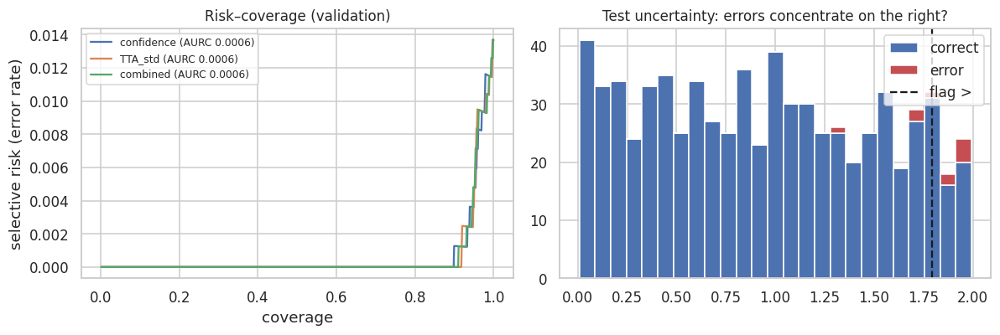

In [ ]:
def tta_params(K, seed=SEED):
    r = np.random.RandomState(seed); return [dict(angle=float(r.uniform(-5, 5)), tx=int(r.randint(-.04 * IMG, .04 * IMG + 1)), ty=int(r.randint(-.04 * IMG, .04 * IMG + 1)), scale=float(r.uniform(.95, 1.05)), br=float(r.uniform(.92, 1.08))) for _ in range(K)]
TTA = tta_params(CFG["tta_k"])
@torch.no_grad()
def tta_logits(model, rows, bs=128):
    model.eval().to(DEVICE); out = []
    for t in TTA:
        L = []
        for i in range(0, len(rows), bs):
            x = torch.from_numpy(IMGS[rows[i:i + bs]]).float().div(255).unsqueeze(1)
            x = TF.affine(x, angle=t["angle"], translate=[t["tx"], t["ty"]], scale=t["scale"], shear=[0., 0.]).mul(t["br"]).clamp(0, 1)
            L.append(model(normalise(x).to(DEVICE)).float().cpu())
        out.append(torch.cat(L).numpy())
    return np.stack(out)
UNC = {}
for split, rows in [("val", ROWS["val"]), ("test", ROWS["test"])]:
    L = np.stack([tta_logits(FINAL[f]["model"], rows) / EVAL[f]["T"] for f in CFG["families"]]).mean(0)
    P = sigmoid(L / EVAL["ensemble"]["T"]); UNC[split] = dict(p_mean=P.mean(0), p_std=P.std(0), L=L)
def conf_score(p): return 1 - np.maximum(p, 1 - p)
def rankavg(a, ref): return np.array([(ref < v).mean() for v in a])
def risk_coverage(y, p, u, thr):
    o = np.argsort(u); err = ((p >= thr).astype(int) != y)[o]; cov = np.arange(1, len(y) + 1) / len(y); risk = np.cumsum(err) / np.arange(1, len(y) + 1); return cov, risk
sc = {"confidence": lambda s, ref=None: conf_score(UNC[s]["p_mean"]), "TTA_std": lambda s, ref=None: UNC[s]["p_std"]}
thr_single = EVAL["ensemble"]["thr"]
thr_e = youden_threshold(yv, UNC["val"]["p_mean"])
EVAL["ensemble"]["thr_tta"] = thr_e; print(f"ensemble threshold: single-pass {thr_single:.4f} -> TTA-mean {thr_e:.4f}")
RC = {}
for name in ["confidence", "TTA_std", "combined"]:
    if name == "combined":
        u_v = rankavg(sc["confidence"]("val"), sc["confidence"]("val")) + rankavg(sc["TTA_std"]("val"), sc["TTA_std"]("val"))
    else: u_v = sc[name]("val")
    cov, risk = risk_coverage(yv, UNC["val"]["p_mean"], u_v, thr_e); RC[name] = dict(AURC=float(np.trapz(risk, cov) if not hasattr(np, "trapezoid") else np.trapezoid(risk, cov)), cov=cov, risk=risk)
AURC = pd.Series({k: v["AURC"] for k, v in RC.items()}, name="val AURC (lower = better)"); display(AURC.round(4).to_frame()); UNC_CHOICE = AURC.idxmin(); print("Chosen uncertainty score (on validation):", UNC_CHOICE)
if AURC.max() - AURC.min() < 1e-3: print("AURC values are tied (range < 0.001), so this choice is arbitrary")

def u_score(split):
    if UNC_CHOICE == "combined": return rankavg(sc["confidence"](split), sc["confidence"]("val")) + rankavg(sc["TTA_std"](split), sc["TTA_std"]("val"))
    return sc[UNC_CHOICE](split)
u_val, u_test = u_score("val"), u_score("test"); ABSTAIN_THR = float(np.quantile(u_val, .90))
abst = u_test > ABSTAIN_THR; acc_mask = ~abst; pred_e = (UNC["test"]["p_mean"] >= thr_e).astype(int)
def sel(m):
    mt = metrics_at(yt[m], UNC["test"]["p_mean"][m], thr_e); return dict(n=int(m.sum()), error_rate=float(1 - mt["accuracy"]), sensitivity=mt["sensitivity"], specificity=mt["specificity"], fn=mt["fn"], fp=mt["fp"])
SEL = pd.DataFrame({"all cases": sel(np.ones(len(yt), bool)), "answered (not flagged)": sel(acc_mask), "flagged low-confidence": sel(abst) if abst.sum() else {}}).T.round(3); display(SEL)
print(f"Test coverage {acc_mask.mean():.1%} | errors falling in the flagged set: {int(((pred_e != yt) & abst).sum())}/{int((pred_e != yt).sum())} "
      f"(flagged share of all cases {abst.mean():.1%})  (abstention-quality metric from the proposal)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, v in RC.items(): ax[0].plot(v["cov"], v["risk"], label=f"{k} (AURC {v['AURC']:.4f})")
ax[0].set(xlabel="coverage", ylabel="selective risk (error rate)", title="Risk–coverage (validation)"); ax[0].legend(fontsize=8)
ax[1].hist([u_test[(pred_e == yt)], u_test[(pred_e != yt)]], bins=25, stacked=True, label=["correct", "error"], color=["#4c72b0", "#c44e52"]); ax[1].axvline(ABSTAIN_THR, c="k", ls="--", label="flag >"); ax[1].set_title("Test uncertainty: errors concentrate on the right?"); ax[1].legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "xai_abstention.png"); plt.show()


13.8b Reported vs deployed decision rule, and how stable it is

In [ ]:
p_tta_t, p_tta_v = UNC["test"]["p_mean"], UNC["val"]["p_mean"]
mt_single, mt_old, mt_new = metrics_at(yt, EVAL["ensemble"]["pt"], thr_single), metrics_at(yt, p_tta_t, thr_single), metrics_at(yt, p_tta_t, thr_e)
cols_ = ("sensitivity", "specificity", "balanced_acc", "fn", "fp")
DEPLOY_VS_REPORT = pd.DataFrame({
    "reported: single pass, threshold from val single-pass": {"threshold": thr_single, "AUROC": roc_auc_score(yt, EVAL["ensemble"]["pt"]), **{k: mt_single[k] for k in cols_}},
    "TTA mean with the OLD threshold (the mismatch)":         {"threshold": thr_single, "AUROC": roc_auc_score(yt, p_tta_t), **{k: mt_old[k] for k in cols_}},
    "deployed: TTA mean, threshold refit on val TTA":         {"threshold": thr_e, "AUROC": roc_auc_score(yt, p_tta_t), **{k: mt_new[k] for k in cols_}}}).round(4)
display(DEPLOY_VS_REPORT); DEPLOY_VS_REPORT.to_csv(ART_DIR / "ensemble_single_vs_tta.csv")
CALIB["ensemble"]["threshold_single_pass"] = thr_single; CALIB["ensemble"]["threshold_tta_mean"] = thr_e
(ART_DIR / "calibration_and_thresholds.json").write_text(json.dumps(CALIB, indent=2))

gid_v = manifest.group_id.values[ROWS["val"]]; Gv = [np.where(gid_v == g)[0] for g in np.unique(gid_v)]
rng_v = np.random.RandomState(SEED); thr_b, sens_b, spec_b = [], [], []
for _ in range(min(CFG["n_boot"], 500)):
    idx = np.concatenate([Gv[i] for i in rng_v.randint(0, len(Gv), len(Gv))])
    if not (0 < yv[idx].mean() < 1): continue
    tb = youden_threshold(yv[idx], p_tta_v[idx]); mb = metrics_at(yt, p_tta_t, tb); thr_b.append(tb); sens_b.append(mb["sensitivity"]); spec_b.append(mb["specificity"])
VAL_UNC = pd.DataFrame({"threshold": thr_b, "test sensitivity": sens_b, "test specificity": spec_b}).quantile([.025, .5, .975]).round(4); VAL_UNC.index = ["2.5%", "median", "97.5%"]
display(VAL_UNC); VAL_UNC.to_csv(ART_DIR / "operating_point_uncertainty_from_validation.csv")
print(f"validation: {len(yv)} images ({int(yv.sum())} pneumonia / {int((1 - yv).sum())} normal) in {len(Gv)} groups. The range above is the extra uncertainty in test sensitivity/specificity "
      "caused by choosing the threshold on this small validation set; the test CIs in Section 12 do not include it. A larger validation split or nested cross-validation would remove it.")


,"reported: single pass, threshold from val single-pass",TTA mean with the OLD threshold (the mismatch),"deployed: TTA mean, threshold refit on val TTA"
threshold,0.7015,0.7015,0.6365
AUROC,0.9972,0.9973,0.9973
sensitivity,0.9944,0.9963,0.9963
specificity,0.9728,0.9565,0.9565
balanced_acc,0.9836,0.9764,0.9764
fn,3.0000,2.0000,2.0000
fp,5.0000,8.0000,8.0000


,threshold,test sensitivity,test specificity
2.5%,0.5168,0.9738,0.9348
median,0.6614,0.9963,0.9565
97.5%,0.9551,0.9963,0.9891


validation: 878 images (656 pneumonia / 222 normal) in 404 groups. The range above is the extra uncertainty in test sensitivity/specificity caused by choosing the threshold on this small validation set; the test CIs in Section 12 do not include it. A larger validation split or nested cross-validation would remove it.


13.9-13.14 Image-knowledge mining

In [ ]:
rows_t = ROWS["test"]; Xt = get_x(rows_t)
sign_all = torch.tensor(np.where(UNC["test"]["p_mean"] >= thr_e, 1., -1.), dtype=torch.float32)
CAMS = {f: np.concatenate([explain(FINAL[f]["model"], Xt[i:i + 32], sign_all[i:i + 32], "GradCAM++") for i in range(0, len(Xt), 32)]) for f in CFG["families"]}
CONS = _norm01(np.mean(list(CAMS.values()), 0)); low = {f: lowres(v) for f, v in CAMS.items()}
AGREE = np.array([np.mean([np.nan_to_num(spearmanr(low[a][i].ravel(), low[b][i].ravel())[0]) for a, b in itertools.combinations(CFG["families"], 2)]) for i in range(len(rows_t))])
pred_e = (UNC["test"]["p_mean"] >= thr_e).astype(int)
OUT_E = np.where((yt == 1) & (pred_e == 1), "TP", np.where((yt == 0) & (pred_e == 0), "TN", np.where((yt == 0) & (pred_e == 1), "FP", "FN")))
print("ensemble outcomes on test:", dict(Counter(OUT_E)), "| median cross-model agreement ρ =", round(float(np.median(AGREE)), 3))

def cluster_boot(fn, pos, n=None):
    n = n or CFG["n_boot"]; g = manifest.group_id.values[pos]; ug = np.unique(g); by = {u: np.where(g == u)[0] for u in ug}; r = np.random.RandomState(SEED); v = []
    for _ in range(n):
        idx = np.concatenate([by[u] for u in r.choice(ug, len(ug))])
        try: v.append(fn(pos[idx]))
        except Exception: pass
    return tuple(np.percentile(v, [2.5, 97.5])) if v else (np.nan, np.nan)


ensemble outcomes on test: {np.str_('TN'): 176, np.str_('FP'): 8, np.str_('TP'): 533, np.str_('FN'): 2} | median cross-model agreement ρ = 0.171


13.10 Subtype model

,3-class subtype (test) - INFLATED: embeddings were trained to separate normal from pneumonia
macro OvR AUROC,0.941 (0.924–0.956)
balanced accuracy,0.837
chance balanced acc,0.333
chosen C,0.001
recall[normal],0.951
recall[bacteria],0.84
recall[virus],0.721


Virus-vs-bacteria within pneumonia (test): AUROC 0.864 (95% CI 0.819–0.901) — above chance, but exploratory: see the metadata-only baseline below before reading it as anatomy.


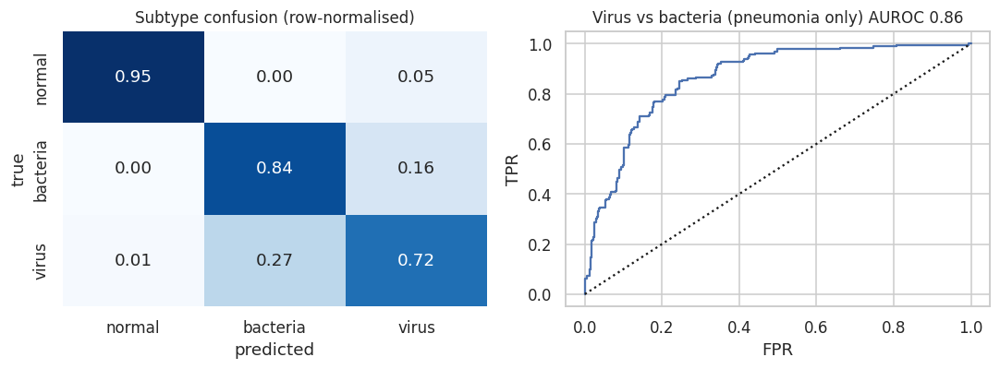

In [ ]:
EMB_ALL = {}
for fam in FAMILIES_ALL:
    EMB_ALL[fam] = predict_logits(FINAL[fam]["model"], manifest.row.values, return_embed=True)[2]
def l2n(E): return E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-8)
EMB_CAT = np.concatenate([l2n(EMB_ALL[f]) for f in CFG["families"]], 1) / np.sqrt(len(CFG["families"]))
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
sub_map = {"normal": 0, "bacteria": 1, "virus": 2}; ysub = manifest.subtype.map(sub_map).fillna(-1).astype(int).values; ok_sub = ysub >= 0
SIDX = {s: np.where((manifest.split.values == s) & ok_sub)[0] for s in ("train", "val", "test")}
scs = StandardScaler().fit(EMB_CAT[SIDX["train"]]); Zs = lambda s: scs.transform(EMB_CAT[SIDX[s]])
best = (-1, None)
for C in [1e-3, 1e-2, 1e-1]:
    clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(Zs("train"), ysub[SIDX["train"]]); a = roc_auc_score(ysub[SIDX["val"]], clf.predict_proba(Zs("val")), multi_class="ovr", average="macro")
    if a > best[0]: best = (a, clf, C)
clf3 = best[1]; P3 = clf3.predict_proba(Zs("test")); y3 = ysub[SIDX["test"]]; pred3 = P3.argmax(1)
from sklearn.metrics import balanced_accuracy_score
auc3 = roc_auc_score(y3, P3, multi_class="ovr", average="macro"); ci3 = cluster_boot(lambda p: roc_auc_score(ysub[p], clf3.predict_proba(scs.transform(EMB_CAT[p])), multi_class="ovr", average="macro"), SIDX["test"])
SUB = {"macro OvR AUROC": f"{auc3:.3f} ({ci3[0]:.3f}–{ci3[1]:.3f})", "balanced accuracy": round(balanced_accuracy_score(y3, pred3), 3), "chance balanced acc": round(1 / 3, 3), "chosen C": best[2]}
for nm, k in sub_map.items(): SUB[f"recall[{nm}]"] = round(float((pred3[y3 == k] == k).mean()), 3) if (y3 == k).any() else None
display(pd.Series(SUB, name="3-class subtype (test) - INFLATED: embeddings were trained to separate normal from pneumonia").to_frame())
pn = {s: SIDX[s][ysub[SIDX[s]] > 0] for s in SIDX}; scp = StandardScaler().fit(EMB_CAT[pn["train"]]); bv = {}
for C in [1e-3, 1e-2, 1e-1]:
    m = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(scp.transform(EMB_CAT[pn["train"]]), ysub[pn["train"]] == 2)
    bv[C] = (roc_auc_score(ysub[pn["val"]] == 2, m.predict_proba(scp.transform(EMB_CAT[pn["val"]]))[:, 1]), m)
Cb = max(bv, key=lambda c: bv[c][0]); mbv = bv[Cb][1]; sbv = mbv.predict_proba(scp.transform(EMB_CAT[pn["test"]]))[:, 1]; ybv = ysub[pn["test"]] == 2
auc_bv = roc_auc_score(ybv, sbv); ci_bv = cluster_boot(lambda p: roc_auc_score(ysub[p] == 2, mbv.predict_proba(scp.transform(EMB_CAT[p]))[:, 1]), pn["test"])
print(f"Virus-vs-bacteria within pneumonia (test): AUROC {auc_bv:.3f} (95% CI {ci_bv[0]:.3f}–{ci_bv[1]:.3f}) — "
      + ("CI includes 0.5: NOT distinguishable from chance with this data/features." if ci_bv[0] <= .5 else "above chance, but exploratory: see the metadata-only baseline below before reading it as anatomy."))
SUBTYPE_HEADLINE = dict(virus_vs_bacteria_auroc=float(auc_bv), ci=[float(ci_bv[0]), float(ci_bv[1])], note="3-class macro AUROC is inflated by the easy normal class; this within-pneumonia number is the honest one")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8)); cm = confusion_matrix(y3, pred3, normalize="true", labels=[0, 1, 2])
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[0], xticklabels=["normal", "bacteria", "virus"], yticklabels=["normal", "bacteria", "virus"]); ax[0].set(title="Subtype confusion (row-normalised)", xlabel="predicted", ylabel="true")
fpr, tpr, _ = roc_curve(ybv, sbv); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set(title=f"Virus vs bacteria (pneumonia only) AUROC {auc_bv:.2f}", xlabel="FPR", ylabel="TPR"); plt.tight_layout(); plt.savefig(FIG_DIR / "subtype_model.png"); plt.show()


In [ ]:
Xm_ = manifest[meta_cols]
mb_ = HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, random_state=SEED).fit(Xm_.iloc[pn["train"]], ysub[pn["train"]] == 2)
auc_bv_meta = roc_auc_score(ybv, mb_.predict_proba(Xm_.iloc[pn["test"]])[:, 1])
ci_bv_meta = cluster_boot(lambda p: roc_auc_score(ysub[p] == 2, mb_.predict_proba(Xm_.iloc[p])[:, 1]), pn["test"])
print(f"Virus-vs-bacteria from metadata only (size, file size, intensity): AUROC {auc_bv_meta:.3f} (95% CI {ci_bv_meta[0]:.3f}-{ci_bv_meta[1]:.3f}) vs embeddings {auc_bv:.3f}")
print("Metadata alone reaches a similar level: the subtype signal is probably confounded by acquisition, not shown to be anatomical." if auc_bv_meta >= auc_bv - .05 else "Embeddings beat metadata-only clearly: some of the signal is not explained by file properties.")


Virus-vs-bacteria from metadata only (size, file size, intensity): AUROC 0.765 (95% CI 0.698-0.822) vs embeddings 0.864
Embeddings beat metadata-only clearly: some of the signal is not explained by file properties.


In [ ]:
P_VIRUS_ALL = mbv.predict_proba(scp.transform(EMB_CAT))[:, 1]
SUBHEAD = dict(status="exploratory", families=list(CFG["families"]), mean=[float(v) for v in scp.mean_], scale=[float(v) for v in scp.scale_],
               coef=[float(v) for v in mbv.coef_[0]], intercept=float(mbv.intercept_[0]), threshold=0.5,
               test_auroc=float(auc_bv), test_auroc_ci=[float(ci_bv[0]), float(ci_bv[1])], metadata_only_auroc=float(auc_bv_meta))
print("subtype head:", len(SUBHEAD["coef"]), "weights | test AUROC", round(SUBHEAD["test_auroc"], 3), "| metadata-only", round(SUBHEAD["metadata_only_auroc"], 3))

subtype head: 3456 weights | test AUROC 0.864 | metadata-only 0.765


13.11 Embedding space

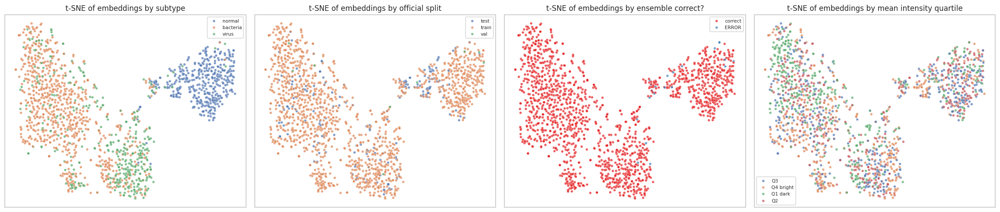

,NMI with 8 k-means clusters
label (NORMAL/PNEUMONIA),0.452
subtype,0.422
official split,0.029
image width (quartile),0.170
mean intensity (quartile),0.036
file size (quartile),0.317


Silhouette (cosine): {'label': np.float64(0.821), 'subtype': np.float64(0.34)}
Nuisance NMI: {'image width (quartile)': 0.17, 'mean intensity (quartile)': 0.036, 'file size (quartile)': 0.317} | label NMI: 0.452
 embedding clusters track acquisition variables (width / brightness / file size) about as much as the label - treat attention and retrieval with extra caution. (File size also reflects image content, so this is a warning, not proof.)


In [ ]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
CORRECT_ALL = np.full(len(manifest), np.nan); CORRECT_ALL[ROWS["val"]] = ((UNC["val"]["p_mean"] >= thr_e).astype(int) == yv); CORRECT_ALL[ROWS["test"]] = (pred_e == yt)
vt = np.where(manifest.split.isin(["val", "test"]).values)[0]; sel = vt if len(vt) <= 2500 else np.random.RandomState(SEED).choice(vt, 2500, replace=False)
Zt = TSNE(2, perplexity=min(30, max(5, (len(sel) - 1) // 3)), init="pca", random_state=SEED).fit_transform(EMB_CAT[sel])
fig, ax = plt.subplots(1, 4, figsize=(21, 4.6))
for a, (name, vals) in zip(ax, [("subtype", manifest.subtype.values[sel]), ("official split", manifest.orig_split.values[sel]), ("ensemble correct?", np.where(np.isnan(CORRECT_ALL[sel]), "?", np.where(CORRECT_ALL[sel] == 1, "correct", "ERROR"))), ("mean intensity quartile", pd.qcut(manifest.mean_int.values[sel], 4, labels=["Q1 dark", "Q2", "Q3", "Q4 bright"], duplicates="drop").astype(str))]):
    sns.scatterplot(x=Zt[:, 0], y=Zt[:, 1], hue=vals, s=14, alpha=.7, ax=a, palette="Set1" if name == "ensemble correct?" else None); a.set_title(f"t-SNE of embeddings by {name}"); a.set_xticks([]); a.set_yticks([]); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "embedding_tsne.png"); plt.show()
km = KMeans(8, n_init=5, random_state=SEED).fit_predict(EMB_CAT)
qc_ = lambda s, q=4: pd.qcut(s, q, labels=False, duplicates="drop")
NMI = pd.Series({"label (NORMAL/PNEUMONIA)": normalized_mutual_info_score(manifest.y, km), "subtype": normalized_mutual_info_score(manifest.subtype, km),
                 "official split": normalized_mutual_info_score(manifest.orig_split, km), "image width (quartile)": normalized_mutual_info_score(qc_(manifest.width), km),
                 "mean intensity (quartile)": normalized_mutual_info_score(qc_(manifest.mean_int), km), "file size (quartile)": normalized_mutual_info_score(qc_(manifest.file_bytes), km)}, name="NMI with 8 k-means clusters").round(3)
display(NMI.to_frame())
sil = {n: silhouette_score(EMB_CAT[::max(1, len(manifest) // 2500)], v[::max(1, len(manifest) // 2500)], metric="cosine") for n, v in [("label", manifest.y.values), ("subtype", manifest.subtype.values)]}
print("Silhouette (cosine):", {k: round(v, 3) for k, v in sil.items()})
NUIS = ["image width (quartile)", "mean intensity (quartile)", "file size (quartile)"]
EMB_WARN = bool(NMI[NUIS].sum() > NMI["label (NORMAL/PNEUMONIA)"] or NMI[NUIS].max() > 0.5 * NMI["label (NORMAL/PNEUMONIA)"])
print("Nuisance NMI:", NMI[NUIS].round(3).to_dict(), "| label NMI:", NMI["label (NORMAL/PNEUMONIA)"])
print(" embedding clusters track acquisition variables (width / brightness / file size) about as much as the label - treat attention and retrieval with extra caution. (File size also reflects image content, so this is a warning, not proof.)" if EMB_WARN else "Clusters align more with the label than with width / brightness / file size (reassuring, not proof).")


13.12 Lung proxy and concept features

In [ ]:
try:
    import torchxrayvision as xrv
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchxrayvision"], check=True)
    import torchxrayvision as xrv
SEG = xrv.baseline_models.chestx_det.PSPNet().to(DEVICE).eval()
_I_RIGHT, _I_LEFT = SEG.targets.index("Right Lung"), SEG.targets.index("Left Lung")
LUNG_SEG_MODEL = "torchxrayvision chestx_det PSPNet (adult CXR training data)"
MIN_LUNG_AREA = 0.02
_MASK_CACHE = {}
def _key(a): return hashlib.md5(np.ascontiguousarray(a).tobytes()).hexdigest()
def _pack(m): return np.packbits(m.ravel())
def _unpack(p, S): return np.unpackbits(p)[: S * S].reshape(S, S).astype(bool)

@torch.no_grad()
def _segment_batch(arrs):
    S = arrs[0].shape[0]
    x = np.stack([cv2.resize(a, (512, 512), interpolation=cv2.INTER_LINEAR) for a in arrs]).astype(np.float32)
    x = torch.from_numpy((2 * (x / 255.0) - 1.0) * 1024.0)[:, None].to(DEVICE)
    out = SEG(x).float()
    if out.min() < 0 or out.max() > 1: out = torch.sigmoid(out)
    res = []
    for o in out[:, [_I_RIGHT, _I_LEFT]].cpu().numpy():
        res.append(tuple(cv2.resize(ch, (S, S), interpolation=cv2.INTER_LINEAR) > 0.5 for ch in o))
    return res

def build_lung_mask_cache(imgs, bs=16):
    t0 = time.time()
    for s in range(0, len(imgs), bs):
        chunk = list(imgs[s:s + bs])
        for a, (mL, mR) in zip(chunk, _segment_batch(chunk)): _MASK_CACHE[_key(a)] = (_pack(mL), _pack(mR))
    print(f"segmented {len(imgs):,} images in {time.time()-t0:.0f}s with {LUNG_SEG_MODEL}")

def lung_proxy(a):
    k = _key(a)
    if k not in _MASK_CACHE:
        (mL, mR), = _segment_batch([a]); _MASK_CACHE[k] = (_pack(mL), _pack(mR))
    S = a.shape[0]; mL, mR = (_unpack(p, S) for p in _MASK_CACHE[k])
    if mL.mean() < MIN_LUNG_AREA or mR.mean() < MIN_LUNG_AREA: return None
    return mL, mR
build_lung_mask_cache(IMGS)
def glcm_feats(crop, mask, levels=16):
    q = np.clip((crop.astype(np.float32) / 256 * levels).astype(int), 0, levels - 1); P = np.zeros((levels, levels)); H, W = crop.shape
    for dy, dx in ((0, 1), (1, 0)):
        a_, b_ = q[:H - dy, :W - dx], q[dy:, dx:]; mk = mask[:H - dy, :W - dx] & mask[dy:, dx:]; np.add.at(P, (a_[mk], b_[mk]), 1)
    P = P + P.T; P /= max(P.sum(), 1); i, j = np.indices(P.shape); nz = P[P > 0]
    mi, mj = (P * i).sum(), (P * j).sum(); si, sj = np.sqrt((P * (i - mi) ** 2).sum()), np.sqrt((P * (j - mj) ** 2).sum())
    return dict(glcm_contrast=(P * (i - j) ** 2).sum(), glcm_homogeneity=(P / (1 + (i - j) ** 2)).sum(), glcm_energy=(P ** 2).sum(), glcm_entropy=-(nz * np.log2(nz)).sum(), glcm_correlation=(P * (i - mi) * (j - mj)).sum() / max(si * sj, 1e-8))
CONCEPT_NAMES = ["area_imgL", "area_imgR", "mean_imgL", "mean_imgR", "std_imgL", "std_imgR", "p90_imgL", "p90_imgR", "lower_upper_ratio_imgL", "lower_upper_ratio_imgR", "asym_area", "asym_mean",
                 "lung_mean", "lung_std", "lung_vs_surround_contrast", "edge_density", "glcm_contrast", "glcm_homogeneity", "glcm_energy", "glcm_entropy", "glcm_correlation"]
def concept_features(a):
    f = {k: np.nan for k in CONCEPT_NAMES}; r = lung_proxy(a); f["lung_ok"] = float(r is not None)
    if r is None: return f
    Lm, Rm = r; af = a.astype(np.float32)
    for nm, M in (("imgL", Lm), ("imgR", Rm)):
        ys, xs = np.where(M); y0, y1 = ys.min(), ys.max(); h = max(y1 - y0, 1); up = M.copy(); up[y0 + h // 3:] = False; lo = M.copy(); lo[:y1 - h // 3] = False
        f[f"area_{nm}"] = M.sum() / M_THORAX.sum(); f[f"mean_{nm}"] = af[M].mean(); f[f"std_{nm}"] = af[M].std(); f[f"p90_{nm}"] = np.percentile(af[M], 90)
        f[f"lower_upper_ratio_{nm}"] = af[lo].mean() / max(af[up].mean(), 1) if lo.any() and up.any() else np.nan
    f["asym_area"] = abs(f["area_imgL"] - f["area_imgR"]) / max(f["area_imgL"] + f["area_imgR"], 1e-6); f["asym_mean"] = abs(f["mean_imgL"] - f["mean_imgR"]) / max((f["mean_imgL"] + f["mean_imgR"]) / 2, 1)
    LR = Lm | Rm; f["lung_mean"] = af[LR].mean(); f["lung_std"] = af[LR].std(); f["lung_vs_surround_contrast"] = af[(~LR) & M_THORAX].mean() - f["lung_mean"] if ((~LR) & M_THORAX).any() else np.nan
    gx, gy = cv2.Sobel(af, cv2.CV_32F, 1, 0), cv2.Sobel(af, cv2.CV_32F, 0, 1); f["edge_density"] = float(np.hypot(gx, gy)[LR].mean())
    ys, xs = np.where(LR); f.update(glcm_feats(a[ys.min():ys.max() + 1, xs.min():xs.max() + 1], LR[ys.min():ys.max() + 1, xs.min():xs.max() + 1])); return f
t0 = time.time(); CONCEPTS = pd.DataFrame([concept_features(IMGS[i]) for i in range(len(IMGS))], index=manifest.index)
CONCEPTS.to_csv(DS_DIR / "concept_features.csv"); print(f"concept features for {len(CONCEPTS):,} images in {time.time()-t0:.0f}s | lung-mask success rate {CONCEPTS.lung_ok.mean():.1%}")
print("success rate by class:", CONCEPTS.groupby(manifest.label_name).lung_ok.mean().round(3).to_dict(), "(a large gap would mean the masks themselves are label-dependent)")
_area = CONCEPTS.area_imgL + CONCEPTS.area_imgR
print("mean lung area (share of thorax box) by class:", _area.groupby(manifest.label_name).mean().round(3).to_dict(), "- a clear gap would mean masks still depend on the label")
rs_ = np.concatenate([np.random.RandomState(SEED).choice(np.where(manifest.y.values == c)[0], 4, replace=False) for c in (0, 1)])
for a, i in zip(axs.ravel(), rs_):
    a.imshow(IMGS[i], cmap="gray"); r = lung_proxy(IMGS[i]); a.axis("off"); a.set_title(f"{manifest.label_name[i][:4]} | {'OK' if r else 'FAILED'}", fontsize=8)
    if r: [a.contour(m_.astype(float), levels=[.5], colors=c) for m_, c in zip(r, ["cyan", "yellow"])]
plt.suptitle("Lung masks from pretrained segmenter (cyan = image-left, yellow = image-right) — visual QC", y=1.0); plt.tight_layout(); plt.savefig(FIG_DIR / "lung_proxy_qc.png"); plt.show()


If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /root/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]
segmented 5,856 images in 80s with torchxrayvision chestx_det PSPNet (adult CXR training data)
concept features for 5,856 images in 39s | lung-mask success rate 99.3%
success rate by class: {'NORMAL': 0.999, 'PNEUMONIA': 0.99} (a large gap would mean the masks themselves are label-dependent)
mean lung area (share of thorax box) by class: {'NORMAL': 0.625, 'PNEUMONIA': 0.66} - a clear gap would mean masks still depend on the label


<Figure size 704x528 with 0 Axes>

13.12b More thorough QC of the lung proxy

success 99.3% | implausible-looking successes (tiny/huge area or strong asymmetry): 205
success rate by label  : {'NORMAL': 0.999, 'PNEUMONIA': 0.99}
success rate by subtype: {'bacteria': 0.988, 'normal': 0.999, 'virus': 0.994}
success rate by width quartile: {Interval(383.999, 1056.0, closed='right'): 0.979, Interval(1056.0, 1281.0, closed='right'): 0.996, Interval(1281.0, 1560.0, closed='right'): 0.997, Interval(1560.0, 2916.0, closed='right'): 0.999}


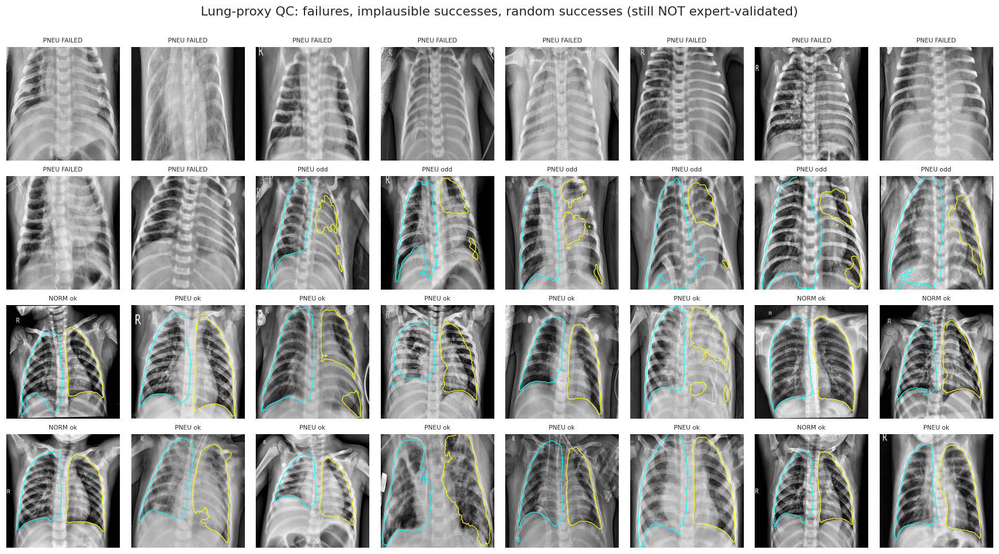

These masks come from a pretrained adult-CXR segmenter applied to paediatric images. Before relying on them for claims about lungs, compare them with ~50 expert-drawn masks.


In [ ]:
ok_arr = CONCEPTS.lung_ok.values == 1; fail_idx = np.where(~ok_arr)[0]; ok_idx = np.where(ok_arr)[0]; rs_q = np.random.RandomState(SEED)
area_ = CONCEPTS[["area_imgL", "area_imgR"]]
implaus = ok_arr & ((area_.min(axis=1) < .04) | (area_.max(axis=1) > .6) | (CONCEPTS.asym_area > .5))
print(f"success {ok_arr.mean():.1%} | implausible-looking successes (tiny/huge area or strong asymmetry): {int(implaus.sum())}")
print("success rate by label  :", CONCEPTS.groupby(manifest.label_name).lung_ok.mean().round(3).to_dict())
print("success rate by subtype:", CONCEPTS.groupby(manifest.subtype).lung_ok.mean().round(3).to_dict())
print("success rate by width quartile:", CONCEPTS.groupby(pd.qcut(manifest.width, 4, duplicates="drop")).lung_ok.mean().round(3).to_dict())
show = list(rs_q.choice(fail_idx, min(10, len(fail_idx)), replace=False)) + list(rs_q.choice(np.where(implaus)[0], min(6, int(implaus.sum())), replace=False)) + list(rs_q.choice(ok_idx, min(16, len(ok_idx)), replace=False))
if show:
    ncol = 8; nrow = int(np.ceil(len(show) / ncol)); fig, axs = plt.subplots(nrow, ncol, figsize=(2.0 * ncol, 2.2 * nrow), squeeze=False)
    for a_ in axs.ravel(): a_.axis("off")
    for a_, i_ in zip(axs.ravel(), show):
        a_.imshow(IMGS[i_], cmap="gray"); r_ = lung_proxy(IMGS[i_]); tag = "FAILED" if r_ is None else ("odd" if implaus.iloc[i_] else "ok")
        a_.set_title(f"{manifest.label_name[i_][:4]} {tag}", fontsize=7)
        if r_ is not None: [a_.contour(m_.astype(float), levels=[.5], colors=c_, linewidths=.8) for m_, c_ in zip(r_, ["cyan", "yellow"])]
    plt.suptitle("Lung-proxy QC: failures, implausible successes, random successes (still NOT expert-validated)", y=1.0); plt.tight_layout(); plt.savefig(FIG_DIR / "lung_proxy_qc_extended.png"); plt.show()
print("These masks come from a pretrained adult-CXR segmenter applied to paediatric images. Before relying on them for claims about lungs, compare them with ~50 expert-drawn masks.")


,train AUROC (concept alone; 0.5 = none)
glcm_homogeneity,0.918
edge_density,0.083
glcm_contrast,0.089
glcm_energy,0.908
glcm_entropy,0.093
glcm_correlation,0.802
lung_mean,0.790
std_imgL,0.214
mean_imgR,0.778
lung_std,0.224


,AUROC
simplecnn,0.995
resnet50,0.995
densenet121,0.993
vit_small,0.997
ensemble,0.997
concept model (21 human-readable features),0.976


Concept-only model AUROC 0.976 (95% CI 0.967–0.985) vs best deep 0.993: simple lung-region measurements recover 97% of the deep model's above-chance signal.


,Spearman ρ with ensemble logit (test)
edge_density,-0.663
glcm_homogeneity,0.653
glcm_energy,0.653
glcm_entropy,-0.650
glcm_contrast,-0.645
std_imgL,-0.542
lung_std,-0.519
lung_vs_surround_contrast,-0.446
std_imgR,-0.428
glcm_correlation,0.407


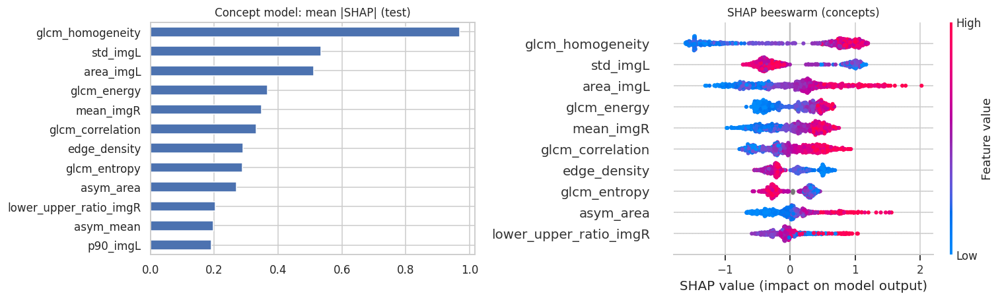

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
trp = manifest.row.values[manifest.split.values == "train"]; vap = ROWS["val"]; tep = ROWS["test"]; C_ = CONCEPTS[CONCEPT_NAMES]
uni = {c: (lambda v: roc_auc_score(Y[trp][~np.isnan(v)], v[~np.isnan(v)]))(C_[c].values[trp]) for c in CONCEPT_NAMES if np.nanstd(C_[c].values[trp]) > 0 and len(np.unique(Y[trp][~np.isnan(C_[c].values[trp])])) == 2}
UNI = pd.Series(uni, name="train AUROC (concept alone; 0.5 = none)").sort_values(key=lambda s: (s - .5).abs(), ascending=False).round(3); display(UNI.head(10).to_frame())
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=.06, max_depth=3, l2_regularization=1.0, class_weight="balanced", random_state=SEED).fit(C_.values[trp], Y[trp])
pc = hgb.predict_proba(C_.values[tep])[:, 1]; auc_c = roc_auc_score(yt, pc); ci_c = boot_ci(roc_auc_score, pc)
cmp_ = pd.DataFrame({"AUROC": {**{m: RES.loc[m, "AUROC"] for m in MODELS}, f"concept model ({len(CONCEPT_NAMES)} human-readable features)": auc_c}}).round(3); display(cmp_)
print(f"Concept-only model AUROC {auc_c:.3f} (95% CI {ci_c[0]:.3f}–{ci_c[1]:.3f}) vs best deep {RES.loc[BEST_FAM,'AUROC']:.3f}: simple lung-region measurements recover "
      f"{(auc_c - .5) / max(RES.loc[BEST_FAM, 'AUROC'] - .5, 1e-9):.0%} of the deep model's above-chance signal.")
lg = EVAL["ensemble"]["lt"]; CORR = pd.Series({c: spearmanr(C_[c].values[tep], lg, nan_policy="omit")[0] for c in CONCEPT_NAMES}, name="Spearman ρ with ensemble logit (test)").sort_values(key=abs, ascending=False).round(3); display(CORR.head(10).to_frame())
import shap
try:
    Xs = C_.iloc[tep].copy(); ex_ = shap.TreeExplainer(hgb)(Xs); imp_ = pd.Series(np.abs(ex_.values).mean(0), index=CONCEPT_NAMES).sort_values().tail(12)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.3)); imp_.plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Concept model: mean |SHAP| (test)"); plt.sca(ax[1]); shap.summary_plot(ex_.values, Xs, max_display=10, show=False, plot_size=None); ax[1].set_title("SHAP beeswarm (concepts)"); plt.tight_layout(); plt.savefig(FIG_DIR / "concept_shap.png"); plt.show()
except Exception as e: print("SHAP on concept model skipped:", type(e).__name__, e)


In [ ]:
ok_t = np.where(CONCEPTS.lung_ok.values[tep] == 1)[0]; LM = {}
for j in ok_t: r = lung_proxy(IMGS[tep[j]]); LM[j] = r[0] | r[1]
def lung_enrich(cam_stack, j): m = LM[j]; return float(mass_share(cam_stack[j:j + 1], m)[0] / m.mean())
ATT = pd.DataFrame({"consensus enrichment": [lung_enrich(CONS, j) for j in ok_t], "outcome": OUT_E[ok_t], **{f"{f}": [lung_enrich(CAMS[f], j) for j in ok_t] for f in CFG["families"]}})
display(ATT.groupby("outcome").mean().round(2).assign(n=ATT.groupby("outcome").size())); print("enrichment = Grad-CAM++ mass inside proxy lungs ÷ lung area share (1 = no preference; >1 = lung-focused)")

def blur_base(x1): sg = x1.shape[-1] / 16; k = 2 * int(3 * sg) + 1; return TF.gaussian_blur(x1, kernel_size=[k, k], sigma=[sg, sg])
@torch.no_grad()
def lung_ablation(model, thr_logit_sign, T=1.0, seed=SEED, control="random"):
    model.eval().to(DEVICE); rr = np.random.RandomState(seed); S = IMG; nb = S // 8; d_l, d_c = [], []
    for j in ok_t:
        x01 = torch.from_numpy(IMGS[tep[j]]).float().div(255)[None, None]; xn = normalise(x01); base = blur_base(xn); m = LM[j]
        blk = m.reshape(nb, 8, nb, 8).mean((1, 3)) > .5; k = int(blk.sum()); cand = np.argwhere((~blk) & M_THORAX.reshape(nb, 8, nb, 8).mean((1, 3)).astype(bool))
        if k == 0 or len(cand) == 0: continue
        if control == "matched": pick = cand[np.argsort(np.abs(cand[:, 0] - np.median(np.argwhere(blk)[:, 0])) + rr.rand(len(cand)) * .5)[:min(k, len(cand))]]
        else: pick = cand[rr.choice(len(cand), min(k, len(cand)), replace=False)]
        ctrl = np.zeros((nb, nb), bool); ctrl[pick[:, 0], pick[:, 1]] = True
        up = lambda b: torch.from_numpy(b.astype(np.float32)).repeat_interleave(8, 0).repeat_interleave(8, 1)[None, None]
        Ml, Mc = up(blk), up(ctrl); xs = torch.cat([xn, xn * (1 - Ml) + base * Ml, xn * (1 - Mc) + base * Mc]).to(DEVICE); l = model(xs).float().cpu().numpy(); s = thr_logit_sign[j]
        d_l.append(s * (l[0] - l[1])); d_c.append(s * (l[0] - l[2]))
    return np.array(d_l), np.array(d_c)
from scipy.stats import wilcoxon
sgn_t = np.where(pred_e == 1, 1., -1.); ABL_L = {}
for fam in FAMILIES_ALL:
    dl, dc = lung_ablation(FINAL[fam]["model"], sgn_t); p_ = wilcoxon(dl, dc).pvalue if len(dl) > 5 and np.any(dl != dc) else np.nan
    dl2, dc2 = lung_ablation(FINAL[fam]["model"], sgn_t, control="matched"); p2_ = wilcoxon(dl2, dc2).pvalue if len(dl2) > 5 and np.any(dl2 != dc2) else np.nan
    ABL_L[fam] = dict(n=len(dl), drop_remove_lungs=dl.mean(), drop_remove_equal_area_outside=dc.mean(), frac_lung_gt_control=float((dl > dc).mean()), wilcoxon_p=p_,
                      drop_remove_matched_control=dc2.mean(), frac_lung_gt_matched=float((dl2 > dc2).mean()), wilcoxon_p_matched=p2_)
ABL_L = pd.DataFrame(ABL_L).T; display(ABL_L.round(4))
print("drop = decrease in the model's logit evidence for its own decision. If removing the lungs does NOT hurt more than removing an equal-area non-lung region, the model is not relying on lung content.")


,consensus enrichment,resnet50,densenet121,vit_small,n
outcome,,,,,
FN,1.13,1.35,1.10,0.94,2
FP,1.46,1.43,1.46,1.25,8
TN,1.24,1.38,1.23,1.07,176
TP,1.24,1.31,1.33,0.70,528


enrichment = Grad-CAM++ mass inside proxy lungs ÷ lung area share (1 = no preference; >1 = lung-focused)


,n,drop_remove_lungs,drop_remove_equal_area_outside,frac_lung_gt_control,wilcoxon_p,drop_remove_matched_control,frac_lung_gt_matched,wilcoxon_p_matched
simplecnn,714.0,1.2710,0.7634,0.4286,0.8251,0.7324,0.4286,0.9895
resnet50,714.0,4.9116,2.0809,0.7689,0.0000,2.0737,0.7787,0.0000
densenet121,714.0,4.6657,2.5078,0.8067,0.0000,2.5447,0.7969,0.0000
vit_small,714.0,0.3822,0.2149,0.5994,0.0001,0.2123,0.5994,0.0001


drop = decrease in the model's logit evidence for its own decision. If removing the lungs does NOT hurt more than removing an equal-area non-lung region, the model is not relying on lung content.


13.13 Seed variance

In [ ]:
BEST_HP = FINAL[BEST_FAM]["hp"]; SEEDS = [SEED + 1] if SMOKE else [SEED + 1, SEED + 2]; SEED_MODELS = {SEED: FINAL[BEST_FAM]["model"]}
for s in SEEDS:
    mdl, _, _, _ = train_model(BEST_FAM, BEST_HP, CFG["final_epochs"], f"seed{s}", "final", seed=s, verbose=False); SEED_MODELS[s] = mdl
    torch.save(mdl.state_dict(), ART_DIR / "models" / f"{BEST_FAM}_seed{s}_{CFG['data_version']}.pt")
LT_S = {s: predict_logits(m, ROWS["test"])[0] for s, m in SEED_MODELS.items()}
sa = {s: roc_auc_score(yt, l) for s, l in LT_S.items()}; ens_s = roc_auc_score(yt, np.mean(list(LT_S.values()), 0))
print(f"{BEST_FAM} test AUROC by seed: { {s: round(a, 4) for s, a in sa.items()} } | mean {np.mean(list(sa.values())):.4f} ± {np.std(list(sa.values())):.4f} | seed-ensemble {ens_s:.4f}")
mp = {s: np.concatenate([explain(m, EX_X[i:i + 16], EX_SIGN[i:i + 16], "GradCAM++") for i in range(0, len(EX_X), 16)]) for s, m in SEED_MODELS.items()}
seed_agree = np.mean([corr(lowres(mp[a]), lowres(mp[b])) for a, b in itertools.combinations(list(mp), 2)])
fam_agree = np.mean([AG.loc[a, b] for a, b in itertools.combinations(CFG["families"], 2)])
SEEDX = pd.Series({"same family, different seeds (mean ρ)": seed_agree, "different families (mean ρ)": fam_agree}, name="Grad-CAM++ agreement").round(3); display(SEEDX.to_frame())
print("-> attributions are " + ("**as variable across seeds as across architectures**: use consensus/ensemble maps and report agreement." if seed_agree < fam_agree + .1 else "more stable across seeds than across architectures (single-model maps are reasonably reproducible)."))


densenet121 test AUROC by seed: {42: np.float64(0.9931), 43: np.float64(0.996), 44: np.float64(0.9956)} | mean 0.9949 ± 0.0013 | seed-ensemble 0.9957


,Grad-CAM++ agreement
"same family, different seeds (mean ρ)",0.756
different families (mean ρ),0.177


-> attributions are more stable across seeds than across architectures (single-model maps are reasonably reproducible).


13.14 Error drivers and suspect labels

FN vs TP (missed pneumonia): too few cases (2 vs 533)


,comparison,concept,n_err,n_ok,rank_biserial,p,median_err,median_ok
0,FP vs TN (false alarms),edge_density,8,176,0.6676,0.0007,104.7243,113.9174
1,FP vs TN (false alarms),glcm_energy,8,176,-0.6065,0.0025,0.0274,0.0251
2,FP vs TN (false alarms),glcm_entropy,8,176,0.6051,0.0026,5.6014,5.7500
3,FP vs TN (false alarms),glcm_contrast,8,176,0.5426,0.0078,1.0573,1.2486
4,FP vs TN (false alarms),glcm_homogeneity,8,176,-0.5398,0.0081,0.7009,0.6812


(exploratory: small error counts, many concepts tested, no multiplicity correction — use as hypotheses, not findings)


mean  size
subtype       bacteria  0.000   356
              normal    0.043   184
              virus     0.011   179
width_q       Q1 small  0.000   181
              Q2        0.006   181
              Q3        0.017   177
              Q4 large  0.033   180
outlier       False     0.013   691
              True      0.036    28
lung_proxy_ok False     0.000     5
              True      0.014   714
low_agreement False     0.009   321
              True      0.018   398

118 suspect labels (2.0%) -> artifacts/suspect_labels.csv | by label: {'PNEUMONIA': 71, 'NORMAL': 47} | by official split: {'train': 79, 'test': 38, 'val': 1}


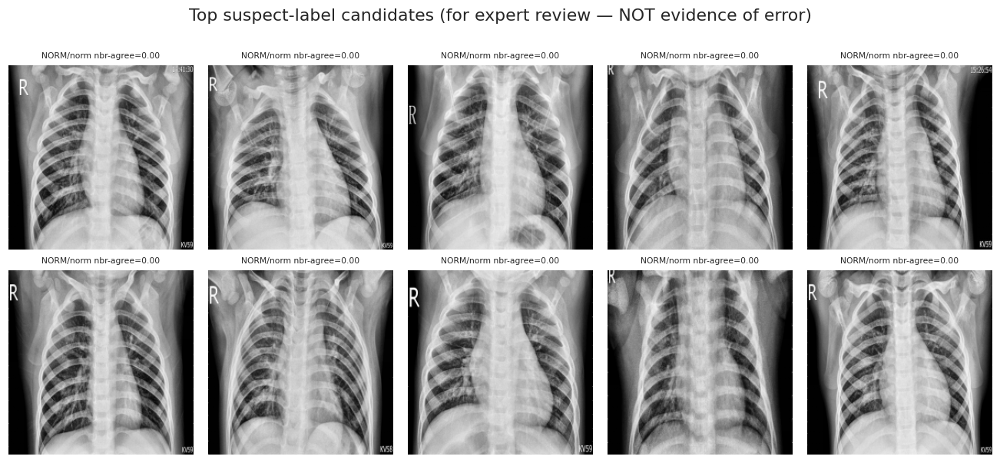

In [ ]:
from scipy.stats import mannwhitneyu
CT = C_.iloc[tep].reset_index(drop=True); ED = []
for nm, a_, b_ in [("FN vs TP (missed pneumonia)", "FN", "TP"), ("FP vs TN (false alarms)", "FP", "TN")]:
    ma, mb = OUT_E == a_, OUT_E == b_
    if ma.sum() < 3 or mb.sum() < 3: print(f"{nm}: too few cases ({ma.sum()} vs {mb.sum()})"); continue
    for c in CONCEPT_NAMES:
        va, vb = CT[c][ma].dropna(), CT[c][mb].dropna()
        if len(va) >= 3 and len(vb) >= 3 and (va.nunique() + vb.nunique()) > 2:
            u, p = mannwhitneyu(va, vb); ED.append(dict(comparison=nm, concept=c, n_err=len(va), n_ok=len(vb), rank_biserial=1 - 2 * u / (len(va) * len(vb)), p=p, median_err=va.median(), median_ok=vb.median()))
ED = pd.DataFrame(ED)
if len(ED): display(ED.sort_values("p").groupby("comparison").head(5).round(4).reset_index(drop=True)); print("(exploratory: small error counts, many concepts tested, no multiplicity correction — use as hypotheses, not findings)")
ER = pd.DataFrame({"error": (pred_e != yt).astype(int), "outlier": manifest.is_outlier.values[tep], "subtype": manifest.subtype.values[tep], "width_q": pd.qcut(manifest.width.values[tep], 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"], duplicates="drop").astype(str),
                   "lung_proxy_ok": CONCEPTS.lung_ok.values[tep], "low_agreement": AGREE < .2}); display(pd.concat({c: ER.groupby(c).error.agg(["mean", "size"]).round(3) for c in ["subtype", "width_q", "outlier", "lung_proxy_ok", "low_agreement"]}))

from sklearn.neighbors import NearestNeighbors
KS = 10; grp = manifest.group_id.values
def knn_agreement(E, KS=KS):
    nn_ = NearestNeighbors(n_neighbors=min(KS * 4, len(manifest)), metric="cosine").fit(E); _, idx = nn_.kneighbors(E); out = np.full(len(manifest), np.nan)
    for i in range(len(manifest)):
        c = idx[i][grp[idx[i]] != grp[i]][:KS]
        if len(c): out[i] = (Y[c] == Y[i]).mean()
    return out
@torch.no_grad()
def frozen_embeddings(family="densenet121", bs=128):
    net = Net(family, 0.0, CFG["pretrained"], CFG["img_size"]).to(DEVICE).eval(); out = []
    for i in range(0, len(IMGS), bs):
        x = normalise(torch.from_numpy(np.ascontiguousarray(IMGS[i:i + bs])).float().div(255).unsqueeze(1)).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"): e = net.embed(x)
        out.append(e.float().cpu())
    return l2n(torch.cat(out).numpy())
EMB_FROZEN = frozen_embeddings()
ag_ft = knn_agreement(EMB_CAT); ag = knn_agreement(EMB_FROZEN)
SUS = manifest[["image_id", "patient_id", "orig_split", "split", "label_name", "subtype"]].copy(); SUS["knn_label_agreement"] = ag.round(3); SUS["knn_label_agreement_finetuned_embeddings"] = ag_ft.round(3); SUS["model_p_pneumonia"] = np.nan
SUS.loc[manifest.index[ROWS["val"]], "model_p_pneumonia"] = EVAL["ensemble"]["pv"].round(4); SUS.loc[manifest.index[ROWS["test"]], "model_p_pneumonia"] = EVAL["ensemble"]["pt"].round(4)
SUS["model_confidently_contradicts"] = ((SUS.model_p_pneumonia - manifest.y).abs() > .9)
SUS["suspect"] = (SUS.knn_label_agreement <= .2) | SUS.model_confidently_contradicts; SUS = SUS.sort_values(["suspect", "knn_label_agreement"], ascending=[False, True])
SUS.to_csv(ART_DIR / "suspect_labels.csv", index=False)
print(f"{int(SUS.suspect.sum())} suspect labels ({SUS.suspect.mean():.1%}) -> artifacts/suspect_labels.csv | by label:", SUS[SUS.suspect].label_name.value_counts().to_dict(), "| by official split:", SUS[SUS.suspect].orig_split.value_counts().to_dict())
top = SUS[SUS.suspect].head(10); fig, axs = plt.subplots(2, 5, figsize=(12, 5.6))
for a, (_, r) in zip(axs.ravel(), top.iterrows()): a.imshow(IMGS[manifest.index[manifest.image_id == r.image_id][0]], cmap="gray"); a.set_title(f"{r.label_name[:4]}/{r.subtype[:4]} nbr-agree={r.knn_label_agreement:.2f}", fontsize=7); a.axis("off")
for a in axs.ravel()[len(top):]: a.axis("off")
plt.suptitle("Top suspect-label candidates (for expert review — NOT evidence of error)", y=1.0); plt.tight_layout(); plt.savefig(FIG_DIR / "suspect_labels.png"); plt.show()


In [ ]:
KNOW = dict(
  detection=dict(best_family=BEST_FAM, test_auroc=float(RES.loc[BEST_FAM, "AUROC"]), ensemble_auroc=float(RES.loc["ensemble", "AUROC"])),
  subtype=dict(note="3-class macro AUROC is inflated by the easy normal class; headline = virus_vs_bacteria", macro_auroc_3class=float(auc3), metadata_only_virus_vs_bacteria_auroc=float(auc_bv_meta), virus_vs_bacteria_auroc=float(auc_bv), virus_vs_bacteria_ci=[float(ci_bv[0]), float(ci_bv[1])]),
  shortcut=dict(metadata_only_auroc=float(audit["metadata_only_AUROC"]), border_only_auroc={k: float(v) for k, v in ABL["border_only"].items()}, embedding_clusters_track_acquisition=bool(EMB_WARN), patch_shuffle_auroc={k: float(v) for k, v in ABL["patch_shuffle_4x4"].items()}, matched_bin_auroc=MATCHED["metadata-score deciles"].to_dict()),
  concepts=dict(lung_proxy_success=float(CONCEPTS.lung_ok.mean()), concept_model_auroc=float(auc_c), top_concepts=UNI.head(5).to_dict()),
  lung_reliance={f: dict(drop_lungs=float(ABL_L.loc[f, "drop_remove_lungs"]), drop_control=float(ABL_L.loc[f, "drop_remove_equal_area_outside"])) for f in ABL_L.index},
  explanation_stability=dict(seed_agreement=float(seed_agree), family_agreement=float(fam_agree), median_image_agreement=float(np.median(AGREE))),
  data_quality=dict(suspect_label_fraction=float(SUS.suspect.mean())))
(ART_DIR / "image_knowledge_summary.json").write_text(json.dumps(KNOW, indent=2, default=float))
L = [f"**Detection:** {BEST_FAM} AUROC {KNOW['detection']['test_auroc']:.3f}; ensemble {KNOW['detection']['ensemble_auroc']:.3f}.",
     f"**Subtype:** headline = virus-vs-bacteria AUROC {auc_bv:.3f} (CI {ci_bv[0]:.2f}-{ci_bv[1]:.2f}); the 3-class macro AUROC {auc3:.3f} is inflated by the easy normal class; metadata-only reaches {auc_bv_meta:.3f}.",
     f"**Interpretable concepts:** 21 lung-region measurements alone reach AUROC {auc_c:.3f}; top single concepts: {', '.join(UNI.head(3).index)}.",
     f"**Lung reliance (causal ablation):** " + "; ".join(f"{f}: lungs {ABL_L.loc[f,'drop_remove_lungs']:.2f} vs control {ABL_L.loc[f,'drop_remove_equal_area_outside']:.2f}" for f in ABL_L.index) + " (logit drop; lung masks are an unvalidated proxy).",
     f"**Shortcut risk:** metadata-only AUROC {audit['metadata_only_AUROC']:.2f}; border-only AUROC {ABL['border_only'].round(2).to_dict()}.",
     f"**Explanation reliability:** seed-to-seed agreement ρ={seed_agree:.2f} vs cross-architecture ρ={fam_agree:.2f}; median per-image consensus agreement {np.median(AGREE):.2f}.",
     f"**Label quality:** {SUS.suspect.mean():.1%} of images flagged as suspect for expert review."]
display(Markdown("### Image-knowledge summary\n" + "\n".join(f"- {t}" for t in L)))


### Image-knowledge summary
- **Detection:** densenet121 AUROC 0.993; ensemble 0.997.
- **Subtype:** headline = virus-vs-bacteria AUROC 0.864 (CI 0.82-0.90); the 3-class macro AUROC 0.941 is inflated by the easy normal class; metadata-only reaches 0.765.
- **Interpretable concepts:** 21 lung-region measurements alone reach AUROC 0.976; top single concepts: glcm_homogeneity, edge_density, glcm_contrast.
- **Lung reliance (causal ablation):** simplecnn: lungs 1.27 vs control 0.76; resnet50: lungs 4.91 vs control 2.08; densenet121: lungs 4.67 vs control 2.51; vit_small: lungs 0.38 vs control 0.21 (logit drop; lung masks are an unvalidated proxy).
- **Shortcut risk:** metadata-only AUROC 0.98; border-only AUROC {'simplecnn': 0.88, 'resnet50': 0.95, 'densenet121': 0.95, 'vit_small': 0.93}.
- **Explanation reliability:** seed-to-seed agreement ρ=0.76 vs cross-architecture ρ=0.18; median per-image consensus agreement 0.17.
- **Label quality:** 2.0% of images flagged as suspect for expert review.

14. Model-output export
Per-image JSON lines in artifacts/model_outputs/, joined on image_id.

In [ ]:
SCOPE = dict(population="paediatric (age 1-5) chest radiographs, single site (Kaggle chest-xray-pneumonia)", task="binary NORMAL vs pneumonia-pattern", adult_or_mimic_transfer=False, clinical_use=False)
EV_DIR = ART_DIR / "model_outputs"; (EV_DIR / "overlays").mkdir(parents=True, exist_ok=True)
def regions(cam, q=85, topk=3):
    bw = (cam >= np.percentile(cam, q)).astype(np.uint8); n, lab, stats, cent = cv2.connectedComponentsWithStats(bw, connectivity=8); tot = cam.sum(); out = []
    for k in range(1, n):
        x, y, w, h, a = stats[k]; cx, cy = cent[k] / IMG; msk = lab == k
        out.append(dict(bbox_xywh_norm=[round(x / IMG, 3), round(y / IMG, 3), round(w / IMG, 3), round(h / IMG, 3)], centroid_norm=[round(float(cx), 3), round(float(cy), 3)],
                        zone=f"{'image_left' if cx < .5 else 'image_right'}_{['upper', 'mid', 'lower'][min(int(cy * 3), 2)]}", mass_share=round(float(cam[msk].sum() / tot), 4), peak=round(float(cam[msk].max()), 3)))
    return sorted(out, key=lambda r: -r["mass_share"])[:topk]

_nm = CONCEPTS[(manifest.split.values == "train") & (manifest.y.values == 0)]
CONC_MU, CONC_SD = _nm[CONCEPT_NAMES].mean(), _nm[CONCEPT_NAMES].std().replace(0, np.nan)
KEY_CONCEPTS = ["asym_area", "asym_mean", "lower_upper_ratio_imgL", "lower_upper_ratio_imgR", "lung_mean", "lung_vs_surround_contrast", "glcm_contrast", "glcm_homogeneity", "edge_density"]
CONCEPT_REC = []
for j in range(len(rows_t)):
    cr = CONCEPTS.iloc[rows_t[j]]; d = {"lung_proxy_ok": bool(cr.lung_ok)}
    for c in KEY_CONCEPTS: v = cr[c]; d[c] = None if pd.isna(v) else dict(value=round(float(v), 4), z_vs_train_normals=None if pd.isna(CONC_SD[c]) else round(float((v - CONC_MU[c]) / CONC_SD[c]), 2))
    CONCEPT_REC.append(d)
KNOWN_LIMITS = ["single-site paediatric (age 1-5) AP chest radiographs", "binary NORMAL vs PNEUMONIA-pattern model only", "attention maps are model attention, not lesion segmentations",
                "zones are in image coordinates (image_left = viewer's left), coarse thirds, not anatomy", "lung masks come from a pretrained adult-CXR segmenter applied to paediatric images; not expert-validated",
                "the size/brightness/border shortcut means the headline AUROC overstates real-world performance"]
KNOWN_LIMITS.append(f"bacteria-vs-virus is an exploratory second step (test AUROC {SUBHEAD['test_auroc']:.2f}; metadata-only baseline {SUBHEAD['metadata_only_auroc']:.2f}); not a diagnosis")
if not globals().get("RAND_PASS", {}).get("GradCAM++", True): KNOWN_LIMITS.append("Grad-CAM++ failed the model-randomisation sanity check on the best model; treat maps as indicative only")
KNOWN_LIMITS.append(f"attention maps differ across architectures (median cross-model agreement rho={np.median(AGREE):.2f}); never read them as lesion locations")
KNOWN_LIMITS += [f"{m} failed the model-randomisation sanity check (its map barely changes when weights are scrambled)" for m, ok in globals().get("RAND_PASS", {}).items() if not ok]
_BE = np.array([float(mass_share(CONS[j][None], M_BORDER)[0]) / M_BORDER.mean() for j in range(len(rows_t))])
PERIPH_THR, AGREE_THR = float(np.percentile(_BE, 90)), float(np.percentile(AGREE, 25))
_dg = manifest.dup_group.values; _dgc = pd.Series(_dg).map(pd.Series(_dg).value_counts()).values
def subtype_rec(r, pos):
    pv = float(P_VIRUS_ALL[r])
    return dict(status="exploratory", applies=bool(pos), p_virus_given_pneumonia=round(pv, 4), predicted=("VIRUS" if pv >= SUBHEAD["threshold"] else "BACTERIA") if pos else None,
                test_auroc=round(SUBHEAD["test_auroc"], 3), note="second step, meaningful only when the main call is pneumonia; may reflect acquisition cues, not anatomy; not a diagnosis")
def make_record(j):
    r = rows_t[j]; mrow = manifest.iloc[r]; p = float(UNC["test"]["p_mean"][j]); cam = CONS[j]; bshare = float(mass_share(cam[None], M_BORDER)[0])
    return dict(schema_version="2.1", scope=SCOPE, image_id=mrow.image_id, patient_id=mrow.patient_id, split="test", data_version=CFG["data_version"], split_sha=SPLIT_SHA,
        models=dict(ensemble_members=CFG["families"], temperature=round(EVAL["ensemble"]["T"], 4), threshold=round(thr_e, 4), operating_point="Youden-J on validation, applied to the TTA-mean ensemble probability"),
        probabilities=dict(ensemble_calibrated=round(p, 4), per_model={f: round(float(EVAL[f]["pt"][j]), 4) for f in CFG["families"]}),
        predicted_class="PNEUMONIA" if p >= thr_e else "NORMAL", subtype=subtype_rec(r, p >= thr_e),
        findings={"pneumonia_pattern": dict(probability=round(p, 4), threshold=round(thr_e, 4), positive=bool(p >= thr_e))},
        uncertainty=dict(score_name=UNC_CHOICE, score=round(float(u_test[j]), 4), candidate_flag_threshold=round(ABSTAIN_THR, 4), low_confidence=bool(abst[j]), tta_prob_std=round(float(UNC["test"]["p_std"][j]), 4), tta_k=CFG["tta_k"]),
        explanation=dict(method="Grad-CAM++ on 3 models, per-image min-max, mean = consensus", explained_class="PNEUMONIA" if p >= thr_e else "NORMAL", top_regions=regions(cam), cross_model_agreement_rho=round(float(AGREE[j]), 3),
                         border_mass_share=round(bshare, 3), border_enrichment=round(bshare / M_BORDER.mean(), 2), periphery_warning=bool(bshare / M_BORDER.mean() > PERIPH_THR), low_agreement_warning=bool(AGREE[j] < AGREE_THR),
                         lung_attention_enrichment=(round(lung_enrich(CONS, int(j)), 2) if int(j) in LM else None), overlay_path=f"overlays/{mrow.image_id}.png"),
        image_concepts=CONCEPT_REC[j], qc=dict(duplicate_group=str(mrow.dup_group), n_copies_in_group=int(_dgc[r]), width=int(mrow.width), height=int(mrow.height), is_outlier=bool(mrow.is_outlier), near_blank=bool(mrow.near_blank)),
        known_limitations=KNOWN_LIMITS)

def write_overlay(j, rec):
    g = IMGS[rows_t[j]]; hm = cv2.applyColorMap((CONS[j] * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]; out = (0.55 * np.stack([g] * 3, -1) + 0.45 * hm).astype(np.uint8).copy()
    for rg in rec["explanation"]["top_regions"][:1]:
        x, y, w, h = [int(round(v * IMG)) for v in rg["bbox_xywh_norm"]]; cv2.rectangle(out, (x, y), (x + w, y + h), (255, 255, 0), 1)
    cv2.imwrite(str(EV_DIR / rec["explanation"]["overlay_path"]), out[..., ::-1])
RECS = []
for j in range(len(rows_t)): rec = make_record(j); RECS.append(rec); write_overlay(j, rec)
with open(EV_DIR / "image_model_outputs.jsonl", "w") as f:
    for rec in RECS: f.write(json.dumps(rec) + "\n")

EVAL_DIR = WORK / "evaluation_only"; EVAL_DIR.mkdir(exist_ok=True); _m = manifest.set_index("image_id")
EVAL_LABELS = {r["image_id"]: dict(image_id=r["image_id"], patient_id=r["patient_id"], y=int(_m.y[r["image_id"]]), label=_m.label_name[r["image_id"]], subtype=_m.subtype[r["image_id"]]) for r in RECS}
with open(EVAL_DIR / "eval_labels.jsonl", "w") as f:
    for v in EVAL_LABELS.values(): f.write(json.dumps(v) + "\n")
(EVAL_DIR / "README.txt").write_text("Ground-truth labels for the exported test records. For EVALUATION ONLY. Do not give to the assistant/RAG team or put in a retrieval index.\n")
np.savez_compressed(EV_DIR / "consensus_cam.npz", image_ids=manifest.image_id.values[rows_t], cam56=lowres(CONS, 56).astype(np.float16))
pd.DataFrame([("probabilities.ensemble_calibrated", "temperature-scaled mean of 3 families' logits -> P(PNEUMONIA), averaged over the TTA copies"), ("predicted_class", "ensemble_calibrated >= threshold (Youden-J chosen on validation)"),
              ("uncertainty.score / low_confidence", "uncertainty score (see score_name) and a candidate flag at the validation 90%-coverage cut; policy for flagged cases is NOT decided here"),
              ("explanation.top_regions", "connected components of the top-15% consensus Grad-CAM++ mass: normalised bbox, coarse zone, mass share"),
              ("explanation.cross_model_agreement_rho", "mean Spearman correlation of Grad-CAM++ maps between the 3 families (low = attention unreliable)"),
              ("explanation.periphery_warning / low_agreement_warning", f"RELATIVE flags, not absolute safety signals: top-10% border enrichment (>{PERIPH_THR:.2f}) / bottom-25% cross-model agreement (<{AGREE_THR:.2f}). The size/brightness shortcut is global, so no per-image flag detects it"), ("image_concepts", "measurements inside lung masks from a pretrained adult-CXR segmenter (not expert-validated on paediatric images), with z-scores vs training NORMAL images"),
              ("subtype", "exploratory second step: p_virus_given_pneumonia from a linear head on the 3 families' embeddings; predicted VIRUS/BACTERIA only when the main call is pneumonia; may reflect acquisition cues"), ("schema_version / scope / findings", "schema 2.1. findings is a dict keyed by finding name, so a multi-label model (e.g. MIMIC-CXR) can emit the same record. scope states the population this model is valid for"),
              ("ground truth", "NOT in this file. See evaluation_only/eval_labels.jsonl (kept out so an assistant cannot read the answer)")], columns=["field", "meaning"]).to_csv(EV_DIR / "field_notes.csv", index=False)
print(f"{len(RECS)} records -> {EV_DIR/'image_model_outputs.jsonl'} | predicted: {dict(Counter(r['predicted_class'] for r in RECS))} | low-confidence flagged: {sum(r['uncertainty']['low_confidence'] for r in RECS)} | "
      f"periphery warnings: {sum(r['explanation']['periphery_warning'] for r in RECS)} | low-agreement: {sum(r['explanation']['low_agreement_warning'] for r in RECS)}")


719 records -> /content/cxr_work/artifacts/model_outputs/image_model_outputs.jsonl | predicted: {'NORMAL': 178, 'PNEUMONIA': 541} | low-confidence flagged: 61 | periphery warnings: 72 | low-agreement: 180


14b. Image embeddings

In [ ]:
np.savez_compressed(EV_DIR / "image_embeddings.npz", image_ids=manifest.image_id.values, patient_id=manifest.patient_id.values, split=manifest.split.values, y=manifest.y.values,
                    **{f"emb_{f}": EMB_ALL[f].astype(np.float16) for f in CFG["families"]})
print({f: EMB_ALL[f].shape for f in CFG["families"]}, "->", EV_DIR / "image_embeddings.npz")


{'resnet50': (5856, 2048), 'densenet121': (5856, 1024), 'vit_small': (5856, 384)} -> /content/cxr_work/artifacts/model_outputs/image_embeddings.npz


In [ ]:
_allrows = manifest.row.values
def _logits_all(fam):
    L, R = predict_logits(FINAL[fam]["model"], _allrows); out = np.empty(len(manifest), np.float32); out[R] = L; return out
LG = {f: _logits_all(f) / EVAL[f]["T"] for f in CFG["families"]}
P_ENS = sigmoid(np.mean(list(LG.values()), 0) / EVAL["ensemble"]["T"])
PRED_ALL = pd.DataFrame(dict(image_id=manifest.image_id.values, patient_id=manifest.patient_id.values, split=manifest.split.values,
    role=manifest.split.map({"train": "fitted_by_models", "val": "used_for_calibration_and_threshold", "test": "held_out"}).values,
    p_pneumonia_ensemble_single_pass=P_ENS.round(5), predicted_class=np.where(P_ENS >= thr_single, "PNEUMONIA", "NORMAL"),
    threshold_single_pass=round(float(thr_single), 4), **{f"p_{f}": sigmoid(LG[f]).round(5) for f in CFG["families"]}))
if all(k in globals() for k in ("clf3", "scs", "EMB_CAT", "mbv", "scp")):
    _p3 = clf3.predict_proba(scs.transform(EMB_CAT))
    PRED_ALL["exploratory_p_normal"], PRED_ALL["exploratory_p_bacteria"], PRED_ALL["exploratory_p_virus"] = _p3.round(4).T
    PRED_ALL["exploratory_p_virus_given_pneumonia"] = mbv.predict_proba(scp.transform(EMB_CAT))[:, 1].round(4)
PRED_ALL.to_csv(EV_DIR / "predictions_all_splits.csv", index=False)
for _r, _g in PRED_ALL.groupby("role"):
    print(f"{_r:36s} n={len(_g):5d}  AUROC={roc_auc_score(manifest.y.values[_g.index], _g.p_pneumonia_ensemble_single_pass):.4f}")
print("->", EV_DIR / "predictions_all_splits.csv", "(only the held_out rows are an honest estimate of performance)")


fitted_by_models                     n= 4259  AUROC=1.0000
held_out                             n=  719  AUROC=0.9972
used_for_calibration_and_threshold   n=  878  AUROC=0.9986
-> /content/cxr_work/artifacts/model_outputs/predictions_all_splits.csv (only the held_out rows are an honest estimate of performance)


In [ ]:
def _safe(fn, default="not computed in this run"):
    try: return fn()
    except Exception: return default
_v = dict(
    n=f"{len(manifest):,}", splits=_safe(lambda: SPLIT_SUMMARY.images.to_dict()), meta=_safe(lambda: round(float(audit["metadata_only_AUROC"]), 3)),
    border=_safe(lambda: ABL["border_only"].round(3).to_dict()), matched=_safe(lambda: MATCHED["metadata-score deciles"].round(3).to_dict()),
    cover=_safe(lambda: MATCHED["coverage[metadata-score deciles]"].round(2).to_dict()), rand=_safe(lambda: RAND_PASS),
    sub=_safe(lambda: {k: (round(v, 3) if isinstance(v, float) else v) for k, v in SUBTYPE_HEADLINE.items() if k != "note"}),
    nd=_safe(lambda: {k: NEAR_AUDIT[k] for k in ("not_identical_cross_patient", "with_label_conflict", "groups_that_merge_several_patients", "largest_group_sizes")}),
    lung=_safe(lambda: _lung_unclear if "_lung_unclear" in globals() else "see MODEL_CARD.md"), ver=CFG["data_version"], sha=SPLIT_SHA)
HANDOFF = """# Hand-off: image-model pipeline (Part 1), data version @@ver@@, split sha @@sha@@
Research prototype. NOT a medical device. NOT validated for clinical use.

## 0. Read this before using anything
1. **Scope.** Paediatric (age 1-5), single-site, AP chest radiographs (Kaggle chest-xray-pneumonia, @@n@@ images, split @@splits@@). Task: NORMAL vs pneumonia pattern.
2. **Nothing here transfers to MIMIC as a model.** MIMIC-CXR is adult and multi-label (CheXpert labels), DICOM/JPG, many sites. The weights, embeddings, temperatures and thresholds are NOT valid there. What DOES transfer: the pipeline structure, the leakage-safe splitting by patient and duplicate group, the audit/QC cells, MLflow conventions, the output schema (v2.1) and the model/dataset card templates. Retrain on MIMIC-CXR.
3. **Headline accuracy is overstated.** Image size/brightness metadata alone predicts the label (grouped-CV AUROC @@meta@@). Border-only input AUROC per model: @@border@@. Equal-metadata-bin AUROC: @@matched@@ (share of test set covered: @@cover@@; low coverage is itself evidence of a shortcut). Do not quote AUROC ~0.995 as expected clinical performance.
4. **Heatmaps are weak evidence.** Grad-CAM++ is model attention, not a lesion map. Zones are image-coordinate thirds, not anatomy. Randomisation sanity check (True = pass): @@rand@@. Cross-model agreement is low. Never turn a heatmap region into an anatomical claim.
5. **Lung masks / image_concepts.** Masks come from a pretrained ADULT chest-X-ray segmenter applied to paediatric images (visual QC only, no expert masks). Models without clear evidence of relying on lung content: @@lung@@. Treat image_concepts as weak descriptive features.
6. **Virus vs bacteria is exploratory.** Reported as @@sub@@ (AUROC, 95% CI). It is built on embeddings from the pneumonia-vs-normal models and may be confounded by acquisition. In the records it is the subtype field (status=exploratory); in the CSV the columns are prefixed exploratory_. Never present it as a diagnosis.
7. **Data limits.** patient_id is parsed from filenames (unverifiable). No timestamps, so study order is NOT chronological. No clinical metadata. Near-duplicate grouping (pHash Hamming <= 4) is loose: @@nd@@ (safe for leakage, smaller effective sample).

## 1. Files
| Path | What | Who |
|---|---|---|
| artifacts/model_outputs/image_model_outputs.jsonl | per-image record, schema 2.1, TEST split only (no ground truth inside) | assistant/RAG team |
| artifacts/model_outputs/field_notes.csv | meaning of every field | everyone |
| artifacts/model_outputs/predictions_all_splits.csv | probabilities for ALL images with a role column (fitted_by_models / used_for_calibration_and_threshold / held_out) | fusion team (use held_out rows for any performance claim) |
| artifacts/model_outputs/image_embeddings.npz | embeddings for all images (resnet50 2048, densenet121 1024, vit_small 384), float16 | fusion team (Kaggle-domain only) |
| artifacts/model_outputs/overlays/, consensus_cam.npz | Grad-CAM++ overlays and low-res maps (test) | display only, see warning 4 |
| artifacts/inference_package/ | self-contained inference (cxr_inference.py, weights, pipeline_config.json, requirements.txt); reproduces the export | anyone running the model |
| artifacts/MODEL_CARD.md, dataset_v1.0/DATASET_CARD.md | cards | everyone |
| evaluation_only/eval_labels.jsonl | ground-truth labels for the exported test records | evaluation ONLY, do not give to the RAG/assistant team |
| ARTIFACT_MANIFEST.json, mlflow.db | file hashes, experiment tracking | reproducibility |

## 2. Record schema (v2.1)
schema_version, scope (population, task, adult_or_mimic_transfer=false, clinical_use=false), image_id, patient_id, split, data_version, split_sha, models (ensemble members, temperature, threshold), probabilities (ensemble_calibrated, per_model), predicted_class (kept for compatibility), subtype (exploratory bacteria/virus second step), findings (dict keyed by finding name; here only pneumonia_pattern with probability, threshold, positive), uncertainty (score, low_confidence flag, TTA std), explanation (top_regions, cross_model_agreement_rho, periphery/low-agreement warnings, overlay_path), image_concepts, qc, known_limitations.
For a multi-label MIMIC model, add more keys under findings with the same sub-fields; consumers should loop over findings rather than read predicted_class.

## 3. Run the model
    pip install -r artifacts/inference_package/requirements.txt
    python artifacts/inference_package/cxr_inference.py path/to/image.jpeg
or `CXRPipeline(folder).predict(path)` and `.heatmap(path)`. Output includes p_pneumonia, predicted, low_confidence and QC warnings (out-of-distribution image size/brightness).

## 4. For the multimodal / MIMIC team
- Reuse: manifest/audit/split code, leakage assertions, schema v2.0, model card template. Replace the data loader, the label space and the preprocessing choices; re-run the shortcut audit (metadata-only AUROC, border-only, matched bins) on MIMIC before trusting any score.
- Split by subject_id (patient), never by image or study.
- Out-of-fold or held-out predictions only when stacking or fusing; never train a fusion model on predictions for images the image model was fitted on.

## 5. For the assistant / RAG team
- Show the uncertainty flag and the warnings next to every suggestion; low_confidence=true means the model should not be the basis of a statement.
- Do not state a diagnosis or an anatomical location from these outputs. The subtype field is exploratory: show it only as a hint labelled exploratory, and only when the main call is pneumonia.
- Do not index or read evaluation_only/ when building or testing retrieval.
- Pass known_limitations along with each record.

## 6. Reproduce
SEED 42, config in CFG (first cells), SMOKE=1 gives a fast code-path test with meaningless numbers. Versions are pinned in inference_package/requirements.txt.
"""
for _k, _val in _v.items(): HANDOFF = HANDOFF.replace(f"@@{_k}@@", str(_val))
(ART_DIR / "HANDOFF.md").write_text(HANDOFF)
print("wrote", ART_DIR / "HANDOFF.md", f"({len(HANDOFF):,} chars)")


wrote /content/cxr_work/artifacts/HANDOFF.md (6,529 chars)


15. Model card and manifest

In [ ]:
try: _lung_unclear = [m for m in ABL_L.index if not (ABL_L.loc[m, "wilcoxon_p_matched"] < .05 and ABL_L.loc[m, "frac_lung_gt_matched"] > .5)]
except Exception: _lung_unclear = ["not computed"]
best_row = RES.loc[BEST_FAM]; _dep = DEPLOY_VS_REPORT["deployed: TTA mean, threshold refit on val TTA"]; _shuf = TEXTURE_FLAGS
MODEL_CARD = f"""# Model card — Smart Clinical Imaging Assistant, image models {CFG['data_version']}
**Status: research prototype. Not a medical device. Not validated for clinical use.**
**Read HANDOFF.md before reusing any model, embedding or output. Nothing here transfers to adult data (e.g. MIMIC-CXR) as a model.**

## Intended use
Research on evidence-linked decision support for chest X-ray review. Outputs are *pattern suggestions with uncertainty and attention maps* for physician review.
**Out of scope:** diagnosis, triage in live care, adults, other scanners/sites, any pathology other than a binary pneumonia pattern.

## Data
Kaggle chest-xray-pneumonia (Kermany et al. 2018), {len(manifest):,} paediatric AP radiographs, pooled and re-split by patient/duplicate group (split sha {SPLIT_SHA}).
No clinical metadata. See DATASET_CARD.md for provenance, preprocessing and leakage checks.

## Models (test split, 95% patient-clustered bootstrap CI; threshold = Youden-J on validation)
{TABLE.to_string()}

Deployed ensemble rule (mean of TTA probabilities, threshold {_dep['threshold']:.3f} refit on validation TTA): sensitivity {_dep['sensitivity']:.3f}, specificity {_dep['specificity']:.3f}. Section 12 rows use single-pass probabilities (see ensemble_single_vs_tta.csv).

Best single family on validation: **{BEST_FAM}** — test AUROC {best_row.AUROC:.3f} ({best_row.AUROC_lo:.3f}–{best_row.AUROC_hi:.3f}), sensitivity {best_row.sensitivity:.3f}, specificity {best_row.specificity:.3f}.

## Explainability findings
- Most faithful attribution method on {BEST_FAM} (insertion−deletion): **{BEST_METHOD}**.
- Border-only ablation AUROC per model: {ABL['border_only'].round(3).to_dict()} (≈0.5 expected if no shortcut). Flags: {SHORTCUT_FLAGS}
- Patch-shuffle (anatomy destroyed) flags: {_shuf}
- Matched-bin AUROC (test images with equal metadata score): {MATCHED['metadata-score deciles'].round(3).to_dict()}
- Metadata-only (size/brightness) label AUROC: {audit['metadata_only_AUROC']:.3f} (confounder risk).
- Bacteria-vs-virus (exploratory second step on pneumonia): AUROC {auc_bv:.3f} (95% CI {ci_bv[0]:.3f}-{ci_bv[1]:.3f}); metadata-only baseline {auc_bv_meta:.3f}. Not a diagnosis.
- Low-confidence flag (90% validation coverage): non-flagged-case error {SEL.loc['answered (not flagged)','error_rate']:.3f} vs all-case error {SEL.loc['all cases','error_rate']:.3f}.

## Limitations & risks
Single-site paediatric data -> expect large performance drop elsewhere; JPEG not DICOM; patient IDs parsed from filenames; near-duplicate grouping (pHash Hamming <= 4) is loose and merges different patients into shared groups (safe for leakage, smaller effective sample); lung masks come from a pretrained adult-CXR segmenter applied to paediatric images (visual QC only, not expert-validated); models without clear evidence of relying on lung content (vs a matched control region): {_lung_unclear}; labels not adjudicated per image; heatmaps are not lesion segmentations;
the Kaggle-derived ground truth has no subtype-level adjudication; temperature-scaling/thresholds were fit on a small validation set (see CIs); multimodal results are NOT available (no clinical data).
Automation-bias risk: always show uncertainty and evidence before the suggested label.
"""
(ART_DIR / "MODEL_CARD.md").write_text(MODEL_CARD)

def sha(p):
    h = hashlib.sha256(); h.update(Path(p).read_bytes()); return h.hexdigest()[:16]
big = {".npy"}
MANIFEST = [dict(path=str(p.relative_to(WORK)), bytes=p.stat().st_size, sha256_16=sha(p) if p.stat().st_size < 300e6 else "skipped(large)") for root_ in (ART_DIR, FIG_DIR, DS_DIR) for p in sorted(root_.rglob("*")) if p.is_file() and "overlays" not in p.parts]
(WORK / "ARTIFACT_MANIFEST.json").write_text(json.dumps(dict(data_version=CFG["data_version"], split_sha=SPLIT_SHA, created=time.strftime("%Y-%m-%d %H:%M"), files=MANIFEST), indent=1))
shutil.make_archive(str(WORK / "handoff_artifacts"), "zip", ART_DIR)
print(f"{len(MANIFEST)} files indexed -> {WORK/'ARTIFACT_MANIFEST.json'}\nhand-off zip: {WORK/'handoff_artifacts.zip'}")
print("\nMLflow UI:  mlflow ui --backend-store-uri", MLFLOW_URI)
print("\n" + MODEL_CARD[:1800])


73 files indexed -> /content/cxr_work/ARTIFACT_MANIFEST.json
hand-off zip: /content/cxr_work/handoff_artifacts.zip

MLflow UI:  mlflow ui --backend-store-uri sqlite:////content/cxr_work/mlflow.db

# Model card — Smart Clinical Imaging Assistant, image models v1.0
**Status: research prototype. Not a medical device. Not validated for clinical use.**
**Read HANDOFF.md before reusing any model, embedding or output. Nothing here transfers to adult data (e.g. MIMIC-CXR) as a model.**

## Intended use
Research on evidence-linked decision support for chest X-ray review. Outputs are *pattern suggestions with uncertainty and attention maps* for physician review.
**Out of scope:** diagnosis, triage in live care, adults, other scanners/sites, any pathology other than a binary pneumonia pattern.

## Data
Kaggle chest-xray-pneumonia (Kermany et al. 2018), 5,856 paediatric AP radiographs, pooled and re-split by patient/duplicate group (split sha 0f9ef780d5c7).
No clinical metadata. See DATASET_CARD.m

Inference package

In [ ]:
import torchvision, importlib.metadata as imd
PKG = ART_DIR / "inference_package"; (PKG / "weights").mkdir(parents=True, exist_ok=True)
assert UNC_CHOICE in ("confidence", "TTA_std", "combined"), UNC_CHOICE

for f in CFG["families"]:
    shutil.copy(ART_DIR / "models" / f"{f}_{CFG['data_version']}.pt", PKG / "weights" / f"{f}.pt")

PIPE = dict(
    package_version="1.1", data_version=CFG["data_version"], split_sha=SPLIT_SHA, created=time.strftime("%Y-%m-%d %H:%M"),
    preprocessing=dict(grayscale=True, clahe=CFG["use_clahe"], clahe_clip=2.0, clahe_tile=[8, 8], resize=CFG["resize_mode"], size=CFG["img_size"]),
    normalisation=dict(mean=IMNET_MEAN.flatten().tolist(), std=IMNET_STD.flatten().tolist()),
    models={f: dict(weights=f"weights/{f}.pt", temperature=float(EVAL[f]["T"])) for f in CFG["families"]},
    ensemble=dict(temperature=float(EVAL["ensemble"]["T"]), threshold=float(thr_e), decision="tta_mean"),
    tta=TTA,
    uncertainty=dict(score=UNC_CHOICE, flag_threshold=float(ABSTAIN_THR), ref_confidence=[float(v) for v in conf_score(UNC["val"]["p_mean"])], ref_tta_std=[float(v) for v in UNC["val"]["p_std"]]),
    subtype=SUBHEAD,
    qc={k: [float(v) for v in np.percentile(manifest[k], [1, 99])] for k in ("width", "height", "mean_int", "std_int")},
    labels={"0": "NORMAL", "1": "PNEUMONIA"},
    versions=dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
                  timm=imd.version("timm"), opencv=cv2.__version__, numpy=np.__version__, pillow=imd.version("pillow")))
(PKG / "pipeline_config.json").write_text(json.dumps(PIPE, indent=2))
v = PIPE["versions"]
(PKG / "requirements.txt").write_text(f"torch=={v['torch'].split('+')[0]}\ntorchvision=={v['torchvision'].split('+')[0]}\ntimm=={v['timm']}\nopencv-python-headless\nnumpy\npillow\ngrad-cam\n")
print("config + weights written to", PKG)


config + weights written to /content/cxr_work/artifacts/inference_package


In [ ]:
INFER_PY = r'''"""Self-contained inference for the chest X-ray image models"""
import io, json, sys
from pathlib import Path
import numpy as np, cv2, torch, torch.nn as nn
import torchvision.models as tvm
import torchvision.transforms.v2.functional as TF
from PIL import Image

def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

class Net(nn.Module):
    def __init__(self, family, img_size=224):
        super().__init__(); self.family = family
        if family == "resnet50":
            self.backbone = tvm.resnet50(weights=None); D = self.backbone.fc.in_features; self.backbone.fc = nn.Identity()
        elif family == "densenet121":
            self.backbone = tvm.densenet121(weights=None); D = self.backbone.classifier.in_features; self.backbone.classifier = nn.Identity()
        elif family == "vit_small":
            import timm
            self.backbone = timm.create_model("vit_small_patch16_224.augreg_in21k_ft_in1k", pretrained=False, num_classes=0, img_size=img_size); D = self.backbone.num_features
        else: raise ValueError(family)
        self.drop = nn.Dropout(0.0); self.fc = nn.Linear(D, 1)
    def forward(self, x): return self.fc(self.drop(self.backbone(x))).squeeze(-1)

class CXRPipeline:
    def __init__(self, folder, device=None):
        self.dir = Path(folder); self.cfg = json.loads((self.dir / "pipeline_config.json").read_text())
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        size = self.cfg["preprocessing"]["size"]; self.models = {}
        for f, m in self.cfg["models"].items():
            net = Net(f, size); net.load_state_dict(torch.load(self.dir / m["weights"], map_location="cpu")); self.models[f] = net.eval().to(self.device)
        self.mean = torch.tensor(self.cfg["normalisation"]["mean"]).view(1, 3, 1, 1); self.std = torch.tensor(self.cfg["normalisation"]["std"]).view(1, 3, 1, 1)

    @staticmethod
    def _open(src):
        if isinstance(src, Image.Image): return src
        if isinstance(src, (bytes, bytearray)): return Image.open(io.BytesIO(src))
        return Image.open(src)

    def preprocess(self, g):
        p = self.cfg["preprocessing"]
        if p["clahe"]: g = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=tuple(p["clahe_tile"])).apply(g)
        if p["resize"] != "squash": raise NotImplementedError("only the squash resize was used for training")
        return cv2.resize(g, (p["size"], p["size"]), interpolation=cv2.INTER_AREA)

    def _norm(self, x01): return (x01.repeat(1, 3, 1, 1) - self.mean) / self.std

    def qc_warnings(self, g, mode, size):
        w = []
        if mode not in ("L", "I;16"): w.append(f"file mode {mode} (training files were greyscale)")
        for k, v in dict(width=size[0], height=size[1], mean_int=float(g.mean()), std_int=float(g.std())).items():
            lo, hi = self.cfg["qc"][k]
            if not lo <= v <= hi: w.append(f"{k}={v:.0f} outside the training 1st-99th percentile ({lo:.0f}-{hi:.0f})")
        if g.std() < 10: w.append("almost blank image")
        return w

    def predict(self, src):
        im = self._open(src); g = np.asarray(im.convert("L")); warnings = self.qc_warnings(g, im.mode, im.size)
        a = self.preprocess(g); x01 = torch.from_numpy(a).float().div(255)[None, None]
        tta = [TF.affine(x01, angle=t["angle"], translate=[t["tx"], t["ty"]], scale=t["scale"], shear=[0., 0.]).mul(t["br"]).clamp(0, 1) for t in self.cfg["tta"]]
        xs = self._norm(torch.cat(tta)).to(self.device); x1 = self._norm(x01).to(self.device)
        Lk, L1, pf, E = [], [], {}, []
        with torch.no_grad():
            for f, net in self.models.items():
                T = self.cfg["models"][f]["temperature"]
                Lk.append(net(xs).float().cpu().numpy() / T)
                l1 = float(net(x1).float().cpu().numpy()[0]) / T; L1.append(l1); pf[f] = float(sigmoid(l1))
                E.append(net.backbone(x1).float().cpu().numpy()[0])
        Te = self.cfg["ensemble"]["temperature"]; thr = self.cfg["ensemble"]["threshold"]
        P = sigmoid(np.mean(Lk, 0) / Te); p, sd = float(P.mean()), float(P.std()); p_single = float(sigmoid(np.mean(L1) / Te))
        us = self.cfg["uncertainty"]; conf = 1 - max(p, 1 - p)
        if us["score"] == "confidence": u = conf
        elif us["score"] == "TTA_std": u = sd
        else: u = float((np.array(us["ref_confidence"]) < conf).mean() + (np.array(us["ref_tta_std"]) < sd).mean())
        sub = None
        if self.cfg.get("subtype"):
            sh = self.cfg["subtype"]; e = np.concatenate([v / max(float(np.linalg.norm(v)), 1e-8) for v in E]) / np.sqrt(len(E))
            pv = float(sigmoid(float(((e - np.array(sh["mean"])) / np.array(sh["scale"])) @ np.array(sh["coef"])) + sh["intercept"]))
            sub = dict(status=sh["status"], applies=bool(p >= thr), p_virus_given_pneumonia=pv, predicted=("VIRUS" if pv >= sh["threshold"] else "BACTERIA") if p >= thr else None)
        return dict(p_pneumonia=p, predicted=self.cfg["labels"]["1" if p >= thr else "0"], threshold=thr, p_single_pass=p_single, per_model=pf,
                    tta_std=sd, uncertainty=float(u), low_confidence=bool(u > us["flag_threshold"]), warnings=warnings, subtype=sub)

    def heatmap(self, src, pneumonia=None):
        from pytorch_grad_cam import GradCAMPlusPlus
        im = self._open(src); a = self.preprocess(np.asarray(im.convert("L")))
        x = self._norm(torch.from_numpy(a).float().div(255)[None, None]).to(self.device)
        if pneumonia is None: pneumonia = self.predict(src)["predicted"] == "PNEUMONIA"
        sign = 1.0 if pneumonia else -1.0; size = self.cfg["preprocessing"]["size"]; maps = []
        for f, net in self.models.items():
            layer = {"resnet50": lambda: [net.backbone.layer4[-1]], "densenet121": lambda: [net.backbone.features.norm5], "vit_small": lambda: [net.backbone.blocks[-1].norm1]}[f]()
            rt = (lambda t, h=size // 16: t[:, 1:, :].reshape(t.size(0), h, h, t.size(2)).permute(0, 3, 1, 2)) if f == "vit_small" else None
            with torch.enable_grad(), GradCAMPlusPlus(model=net, target_layers=layer, reshape_transform=rt) as cam:
                m = cam(input_tensor=x, targets=[lambda out, s=sign: s * out.reshape(-1)[0]])[0]
            maps.append((m - m.min()) / max(m.max() - m.min(), 1e-8))
        c = np.mean(maps, 0); return a, (c - c.min()) / max(c.max() - c.min(), 1e-8)

if __name__ == "__main__":
    print(json.dumps(CXRPipeline(Path(__file__).parent).predict(sys.argv[1]), indent=2))
'''
(PKG / "cxr_inference.py").write_text(INFER_PY)
print("wrote", PKG / "cxr_inference.py")


wrote /content/cxr_work/artifacts/inference_package/cxr_inference.py


In [ ]:
import subprocess
pm = np.array([r["probabilities"]["ensemble_calibrated"] for r in RECS]); lowc = np.array([r["uncertainty"]["low_confidence"] for r in RECS])
n_each = 3 if SMOKE else 10
sel_ = list(np.argsort(-pm)[:n_each]) + list(np.argsort(pm)[:n_each]) + list(np.argsort(np.abs(pm - thr_e))[:n_each]) + list(np.where(lowc)[0][:n_each])
sel_ = sorted(set(int(i) for i in sel_)); recs = [RECS[i] for i in sel_]
paths = manifest.set_index("image_id").loc[[r["image_id"] for r in recs], "path"].tolist()
script = f"""
import sys, json; sys.path.insert(0, r"{PKG}")
from cxr_inference import CXRPipeline
pipe = CXRPipeline(r"{PKG}")
keep = ("p_pneumonia", "predicted", "low_confidence", "uncertainty", "subtype")
print(json.dumps([{{k: v for k, v in pipe.predict(p).items() if k in keep}} for p in {paths!r}]))
"""
r = subprocess.run([sys.executable, "-c", script], capture_output=True, text=True)
if r.returncode: print(r.stderr[-1500:])
new = json.loads(r.stdout.strip().splitlines()[-1]); bad = []
for rec, o in zip(recs, new):
    e = rec["probabilities"]["ensemble_calibrated"]; d = abs(e - o["p_pneumonia"])
    same_cls = o["predicted"] == rec["predicted_class"]; same_flag = o["low_confidence"] == rec["uncertainty"]["low_confidence"]
    dv = abs(rec["subtype"]["p_virus_given_pneumonia"] - o["subtype"]["p_virus_given_pneumonia"]); same_sub = (o["subtype"]["predicted"] == rec["subtype"]["predicted"]) or abs(rec["subtype"]["p_virus_given_pneumonia"] - SUBHEAD["threshold"]) < 1e-2
    near_thr = abs(e - thr_e) < 1e-3; near_flag = abs(rec["uncertainty"]["score"] - ABSTAIN_THR) < 1e-3
    print(f"{rec['image_id'][-38:]:38s} ref={EVAL_LABELS[rec['image_id']]['y']} export {e:.4f} | package {o['p_pneumonia']:.4f} | diff {d:.5f} | class {'ok' if same_cls else 'DIFF'} | flag {'ok' if same_flag else 'DIFF'} | p_virus diff {dv:.5f}")
    if d >= 1e-3 or (not same_cls and not near_thr) or (not same_flag and not near_flag) or dv >= 1e-2 or not same_sub: bad.append(rec["image_id"])
assert not bad, f"package does not reproduce the export for: {bad}"
shutil.make_archive(str(WORK / "inference_package"), "zip", PKG)
print(f"OK: package reproduces the export on {len(recs)} stratified records (probability, class, low-confidence flag and subtype) ->", WORK / "inference_package.zip")

test__NORMAL__IM-0079-0001.jpeg        ref=0 export 0.7617 | package 0.7617 | diff 0.00002 | class ok | flag ok | p_virus diff 0.00073
test__NORMAL__IM-0085-0001.jpeg        ref=0 export 0.9409 | package 0.9409 | diff 0.00004 | class ok | flag ok | p_virus diff 0.00001
test__NORMAL__IM-0091-0001.jpeg        ref=0 export 0.3635 | package 0.3636 | diff 0.00007 | class ok | flag ok | p_virus diff 0.00005
est__NORMAL__NORMAL2-IM-0135-0001.jpeg ref=0 export 0.2271 | package 0.2271 | diff 0.00002 | class ok | flag ok | p_virus diff 0.00003
est__NORMAL__NORMAL2-IM-0145-0001.jpeg ref=0 export 0.3766 | package 0.3766 | diff 0.00001 | class ok | flag ok | p_virus diff 0.00068
est__NORMAL__NORMAL2-IM-0238-0001.jpeg ref=0 export 0.3759 | package 0.3759 | diff 0.00001 | class ok | flag ok | p_virus diff 0.00043
est__NORMAL__NORMAL2-IM-0280-0001.jpeg ref=0 export 0.6106 | package 0.6106 | diff 0.00001 | class ok | flag ok | p_virus diff 0.00037
est__NORMAL__NORMAL2-IM-0283-0001.jpeg ref=0 export 0.4

16. Try an image
Upload a JPEG or PNG to get a prediction and heatmap.

In [ ]:
import io
import torchvision.transforms.v2.functional as TF

def _prep(src):
    im = src if isinstance(src, Image.Image) else Image.open(src)
    return np.asarray(im.convert("L")), dict(mode=im.mode, width=im.size[0], height=im.size[1])

def _qc(g, info):
    w = []
    if info["mode"] not in ("L", "I;16"): w.append(f"file mode {info['mode']} (training files were greyscale) - colour photo or screenshot?")
    for k, v in dict(width=info["width"], height=info["height"], mean_int=float(g.mean()), std_int=float(g.std())).items():
        lo, hi = np.percentile(manifest[k], [1, 99])
        if not lo <= v <= hi: w.append(f"{k}={v:.0f} is outside the training 1st-99th percentile ({lo:.0f}-{hi:.0f}) -> out-of-distribution")
    if g.std() < 10: w.append("almost blank image")
    return w

@torch.no_grad()
def predict_image(src, show=True):
    g, info = _prep(src)
    a = preprocess_gray(g, CFG["img_size"], CFG["use_clahe"], CFG["resize_mode"])
    x01 = torch.from_numpy(a).float().div(255)[None, None]
    tta = [TF.affine(x01, angle=t["angle"], translate=[t["tx"], t["ty"]], scale=t["scale"], shear=[0., 0.]).mul(t["br"]).clamp(0, 1) for t in TTA]
    xs = torch.cat([normalise(v) for v in tta]).to(DEVICE); L_f, p_f, E_ = {}, {}, []
    for f in CFG["families"]:
        m = FINAL[f]["model"].eval().to(DEVICE)
        with torch.no_grad():
            L_f[f] = m(xs).float().cpu().numpy() / EVAL[f]["T"]
            p_f[f] = float(sigmoid(m(normalise(x01).to(DEVICE)).float().cpu().numpy()[0] / EVAL[f]["T"]))
            E_.append(m.embed(normalise(x01).to(DEVICE)).float().cpu().numpy()[0])
    P = sigmoid(np.mean(list(L_f.values()), 0) / EVAL["ensemble"]["T"]); p, sd = float(P.mean()), float(P.std())
    if UNC_CHOICE == "confidence": u = float(conf_score(np.array([p]))[0])
    elif UNC_CHOICE == "TTA_std": u = sd
    else: u = float(rankavg(conf_score(np.array([p])), sc["confidence"]("val"))[0] + rankavg(np.array([sd]), sc["TTA_std"]("val"))[0])
    e_ = np.concatenate([v / max(float(np.linalg.norm(v)), 1e-8) for v in E_]) / np.sqrt(len(E_)); pv_ = float(mbv.predict_proba(scp.transform(e_[None]))[0, 1])
    sub_ = dict(p_virus_given_pneumonia=pv_, predicted=("VIRUS" if pv_ >= .5 else "BACTERIA") if p >= thr_e else None)
    sign = torch.tensor([1.0 if p >= thr_e else -1.0]); xn = normalise(x01)
    with torch.enable_grad():
        cams = [explain(FINAL[f]["model"], xn, sign, "GradCAM++")[0] for f in CFG["families"]]
    cons = _norm01(np.mean(cams, 0)[None])[0]
    agree = float(np.mean([np.nan_to_num(spearmanr(lowres(cams[i][None])[0].ravel(), lowres(cams[j][None])[0].ravel())[0]) for i, j in itertools.combinations(range(len(cams)), 2)]))
    res = dict(p_pneumonia=p, predicted="PNEUMONIA" if p >= thr_e else "NORMAL", threshold=thr_e, per_family=p_f, tta_std=sd, uncertainty=u,
               low_confidence=bool(u > ABSTAIN_THR), cross_model_agreement=agree, top_regions=regions(cons), warnings=_qc(g, info), subtype=sub_)
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(9, 4.3)); ax[0].imshow(g, cmap="gray"); ax[0].set_title("input"); ax[0].axis("off")
        ax[1].imshow(a, cmap="gray"); ax[1].imshow(cons, cmap="jet", alpha=.45); ax[1].axis("off")
        ax[1].set_title(f"{res['predicted']}  p={p:.3f}" + ("  [LOW CONFIDENCE]" if res["low_confidence"] else "") + (f"  | {sub_['predicted']} p_virus={pv_:.2f} " if sub_["predicted"] else "")); plt.tight_layout(); plt.show()
        print(f"P(pneumonia)={p:.4f} (threshold {thr_e:.3f}) | per model: { {k: round(v, 3) for k, v in p_f.items()} } | TTA std {sd:.4f} | model agreement rho={agree:.2f}")
        for w in res["warnings"]: print("WARNING:", w)
    return res

def upload_and_predict():
    try: from google.colab import files
    except ImportError: raise RuntimeError('not in Colab: call predict_image("/path/to/image.jpeg") instead')
    up = files.upload()
    for name, data in up.items(): print(name); predict_image(io.BytesIO(data))

def verify_against_export(n=5):
    rows = manifest[(manifest.split == "test") ].sample(n, random_state=0)
    by_id = {r["image_id"]: r for r in RECS}
    for _, r in rows.iterrows():
        res = predict_image(r.path, show=False); rec = by_id[r.image_id]
        print(f"{r.image_id[-40:]:40s} true={r.label_name:9s} pred={res['predicted']:9s} p={res['p_pneumonia']:.4f} | exported p={rec['probabilities']['ensemble_calibrated']:.4f} | diff={abs(res['p_pneumonia'] - rec['probabilities']['ensemble_calibrated']):.5f}")

def stress_test(src):
    g, _ = _prep(src); im = Image.fromarray(g); buf = io.BytesIO(); im.save(buf, "JPEG", quality=20); buf.seek(0)
    variants = {"original": im, "downscaled 50% and back": im.resize((im.width // 2, im.height // 2)).resize(im.size), "JPEG quality 20": Image.open(buf).convert("L"), "gaussian blur": Image.fromarray(cv2.GaussianBlur(g, (0, 0), 3))}
    for k, v in variants.items(): print(f"{k:26s} p(pneumonia) = {predict_image(v, show=False)['p_pneumonia']:.3f}")


Saving V.jpeg to V (1).jpeg
V (1).jpeg


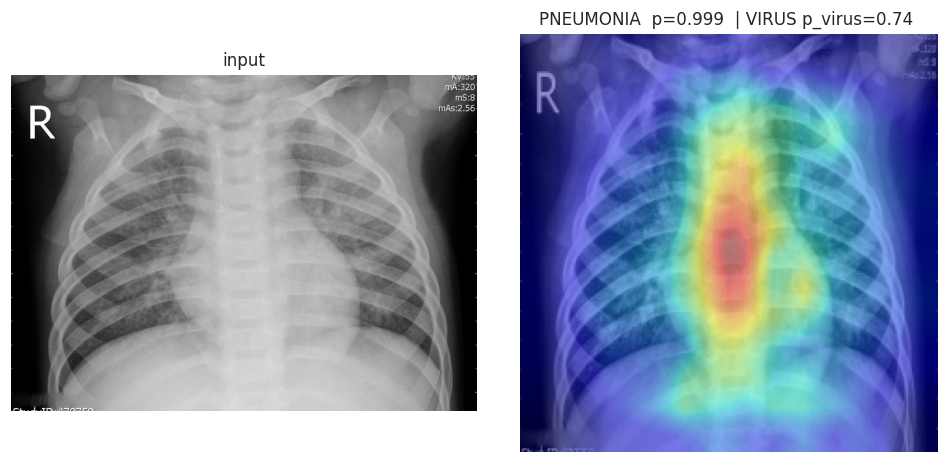

P(pneumonia)=0.9988 (threshold 0.636) | per model: {'resnet50': 0.998, 'densenet121': 1.0, 'vit_small': 0.991} | TTA std 0.0006 | model agreement rho=0.61


In [ ]:
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB: upload_and_predict()
else: print("Not running in Colab: call predict_image(\"/path/to/image.jpeg\") on any chest X-ray file.")


In [ ]:
IN_COLAB = importlib.util.find_spec("google.colab") is not None
shutil.make_archive(str(WORK / "figures"), "zip", FIG_DIR)
shutil.make_archive(str(WORK / "mlruns_artifacts"), "zip", WORK / "mlruns_artifacts")
shutil.make_archive(str(WORK / "evaluation_only"), "zip", WORK / "evaluation_only")
SHARE = ["dataset_v1.0.zip", "inference_package.zip", "handoff_artifacts.zip", "figures.zip", "mlruns_artifacts.zip", "mlflow.db", "ARTIFACT_MANIFEST.json"]
PRIVATE = ["evaluation_only.zip"]
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/SIC_final_handoff"); (OUT / "private_eval").mkdir(parents=True, exist_ok=True)
    for n in SHARE: shutil.copy(WORK / n, OUT / n); print("copied", n)
    shutil.copy(ART_DIR / "HANDOFF.md", OUT / "HANDOFF.md"); print("copied HANDOFF.md")
    for n in PRIVATE: shutil.copy(WORK / n, OUT / "private_eval" / n); print("copied (private)", n)
else:
    print("Not in Colab. Hand-off files are in", WORK, ":", SHARE + PRIVATE, "+ artifacts/HANDOFF.md")


Mounted at /content/drive
copied dataset_v1.0.zip
copied inference_package.zip
copied handoff_artifacts.zip
copied figures.zip
copied mlruns_artifacts.zip
copied mlflow.db
copied ARTIFACT_MANIFEST.json
copied HANDOFF.md
copied (private) evaluation_only.zip
